# Proof embeddings at controlled coupling strength — p90, 2026-10-06

Question: if coupling strength is neutralised per recording, do the baselines (mean absolute correlation; the mean of each SPI, $m$) lose the class structure that SPI–SPI $z$ keeps? Answer from this run: mean $|r|$ alone falls to chance, and the geometry of $m$ degrades where strength varies between recordings, most clearly among CML regimes; but $m$ never becomes uninformative, and setting strength to one common value changes nothing. Exploratory; arms were fixed before p90, the $M=24$ repeat was added after the $M=16$ outcome.

In [1]:
from pathlib import Path
import sys, warnings
import matplotlib.pyplot as plt, pandas as pd
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
from research.proof.baselines import proof_strength_nuisance as P
rows, bank = P.load('m16'); OUT = ROOT / 'results/proof' / P.RUNS['m16']['run']; cache = {}
print(f"{len(rows)} recordings; {len(bank['spi_order'])} SPIs; {bank['z'].shape[1]:,} SPI-SPI coordinates; M=16, T=1000")

1680 recordings; 289 SPIs; 41,616 SPI-SPI coordinates; M=16, T=1000


Eight coupled classes (two ring VARs at spectral radius .98, Kuramoto at partial synchrony, the wave equation, four CML regimes) and the two independent-noise references, 40 realizations each. Every arm observes the same realization through white sensor noise of SD $\eta$ (signal-SD units), which attenuates all dependence together; arms differ only in how $\eta$ is chosen. `native`: none. `equalised`: $\eta$ solves mean $|r|=.14$. `mild`: $\eta\sim U[.3,.9]$. `matched`: $\eta$ solves mean $|r|=s$ with $s\sim U[.08,.20]$, the same distribution in every class. `wide`: Pearson attenuation $1/(1+\eta^2)\sim U[.25,.95]$. `mild` and `wide` are independent of class; `equalised` and `matched` need more noise for natively stronger classes.

Noise can lower strength but not raise it. A recording natively weaker than its target is left as generated: 55% of fully developed turbulence (native mean $|r|\approx.13$) in `matched`, 92% of it in `equalised`, at most 12% of any other class. The noise classes have no coupling to attenuate and join every arm unchanged. Features and preprocessing follow the proof notebook; $m$ is additionally scaled to unit variance and clipped at five SD because SPI units differ. Each arm and panel is fitted separately and without labels.

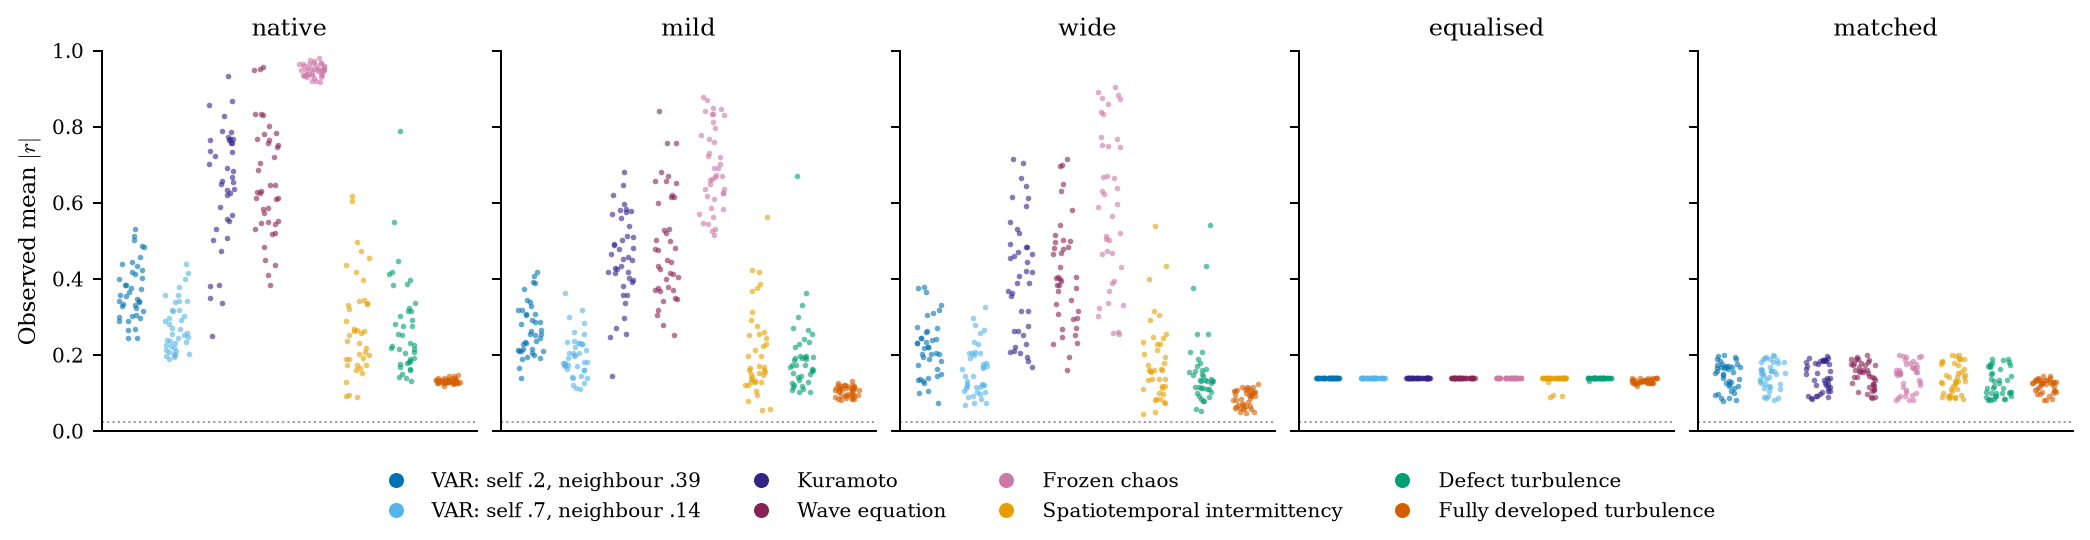

In [2]:
fig = P.strength_figure(rows, OUT); plt.show()

Within CML. Rows are arms. Fixed strength (`native`, `equalised`) leaves both representations clustered. Once strength varies between recordings (`matched`, `wide`) the mean vectors spread along it and their UMAP loses separate clusters; $z$ keeps four.

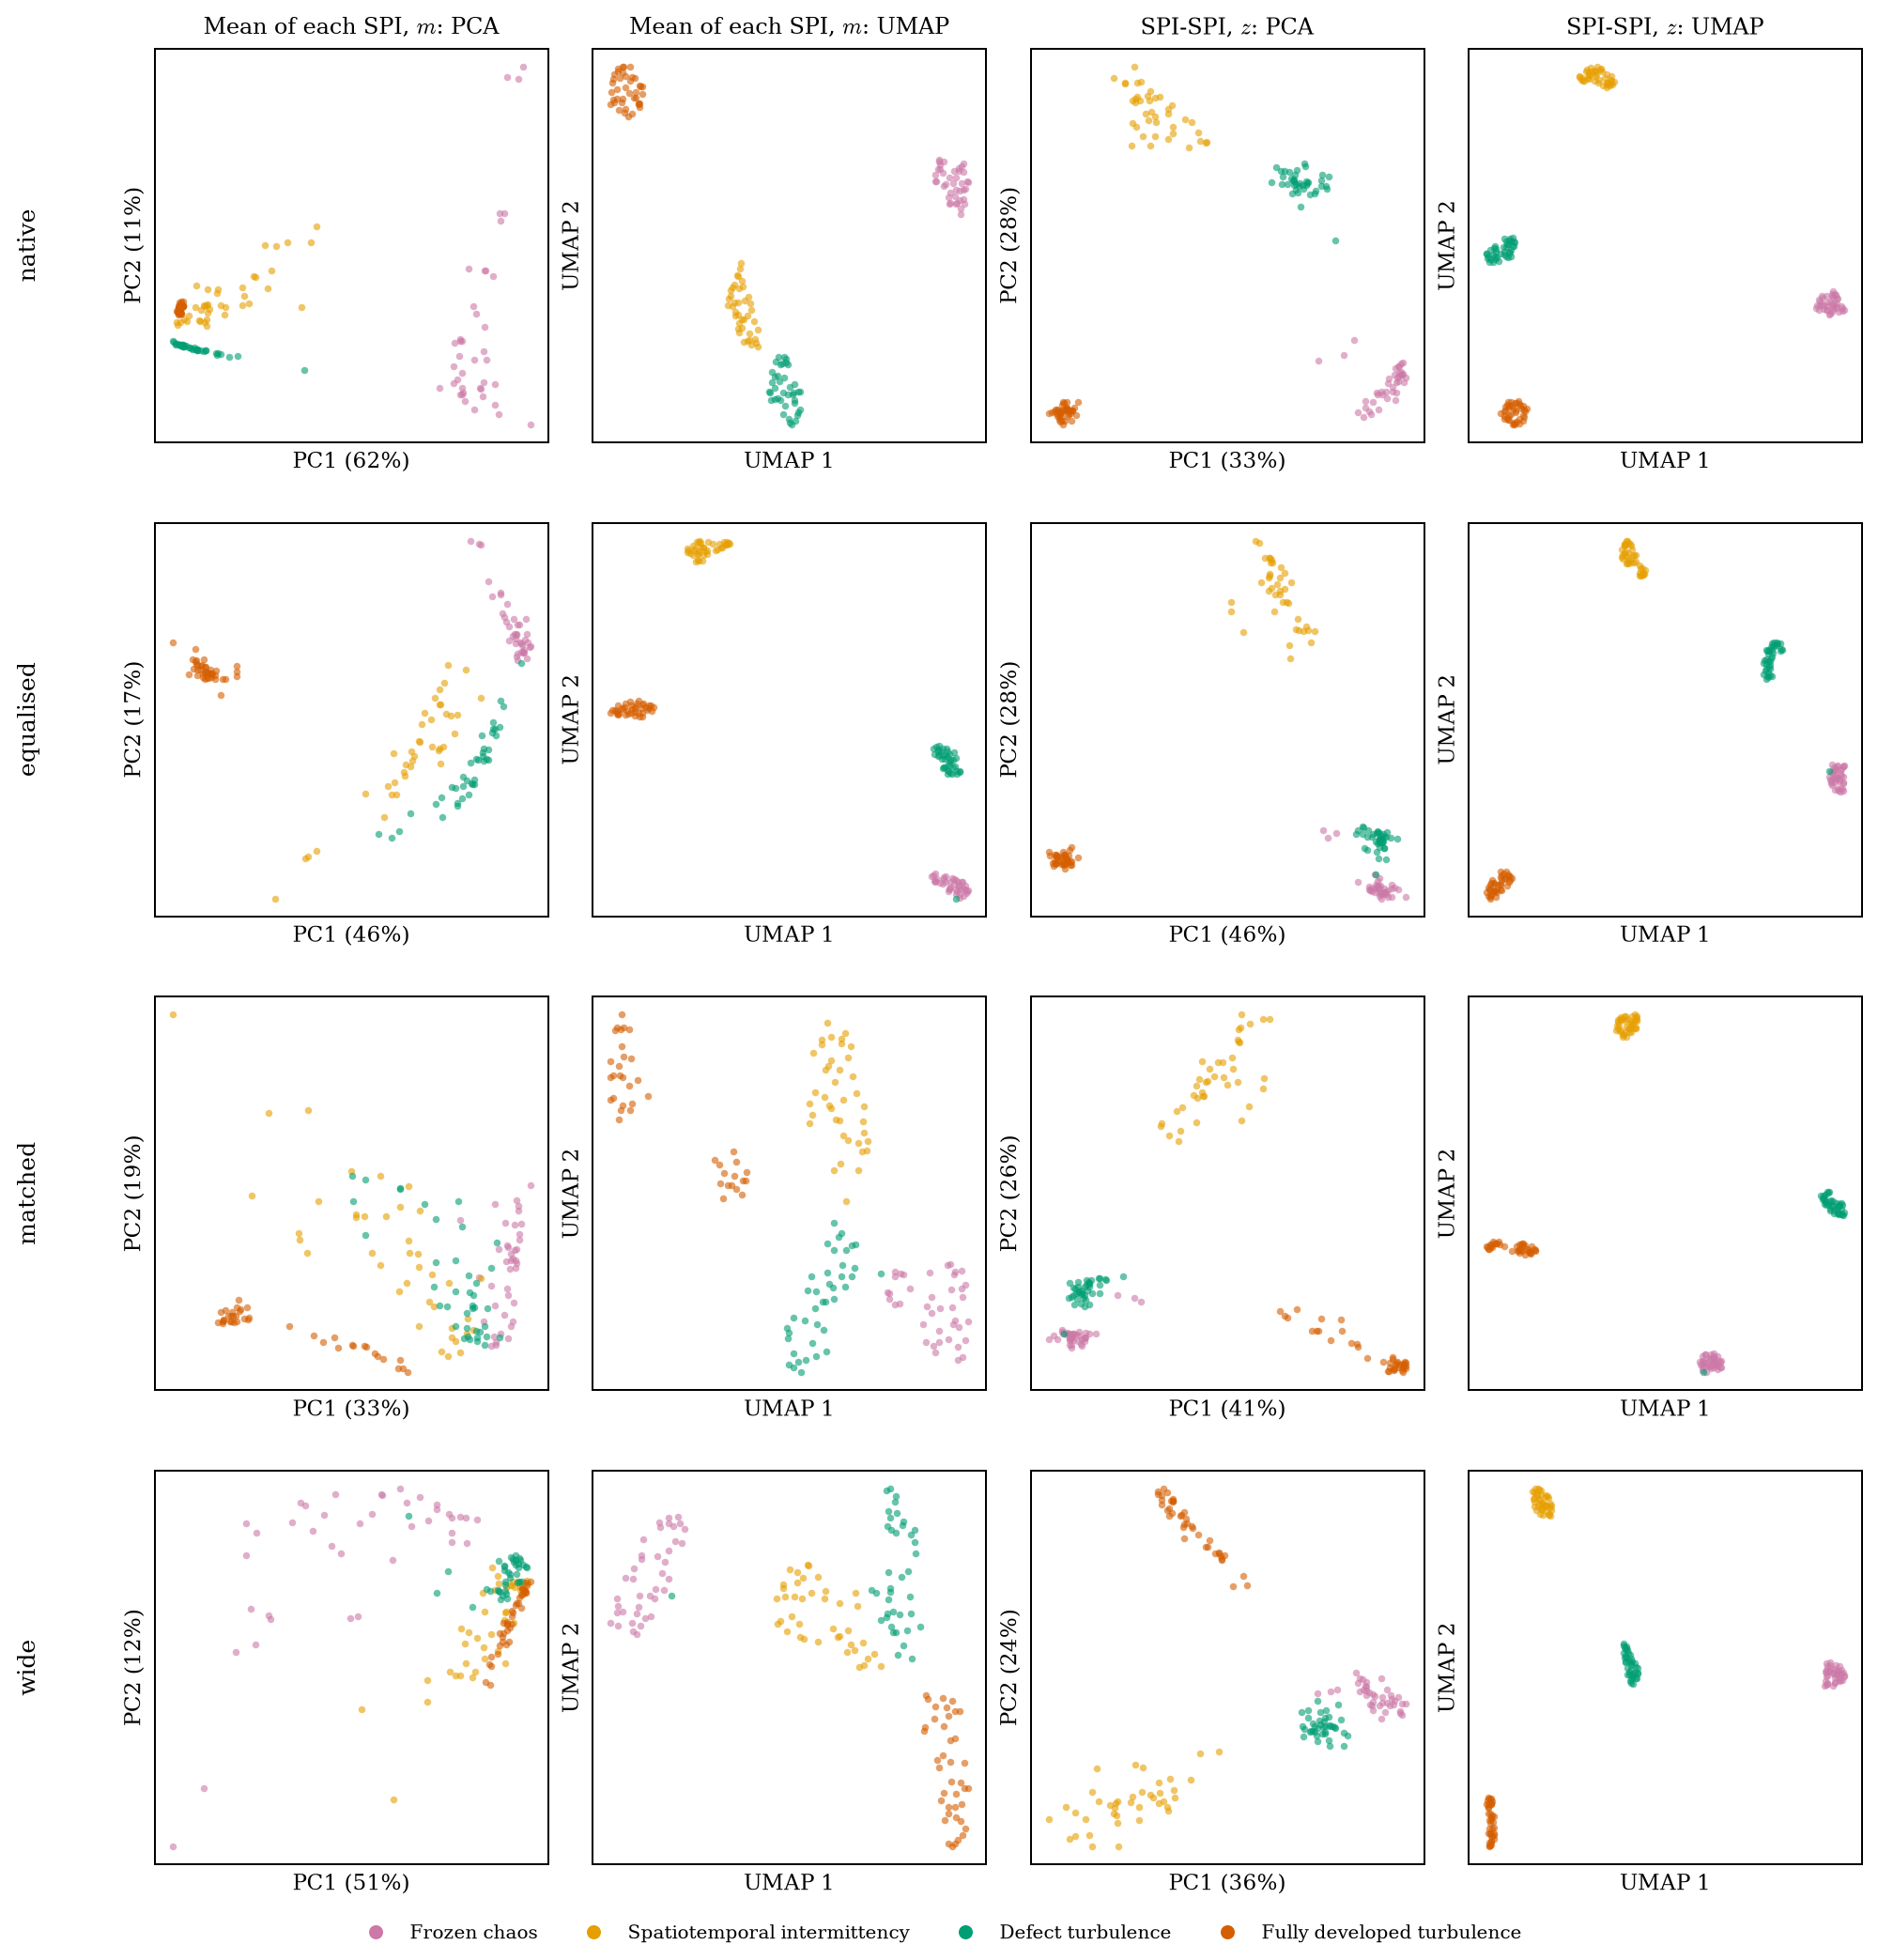

In [3]:
fig = P.embedding_figure(rows, bank, 'cml', ('native', 'equalised', 'matched', 'wide'), OUT, cache=cache); plt.show()

The same two varying-strength arms coloured by observed mean $|r|$: strength is a gradient across the mean embedding and is mixed within each $z$ cluster.

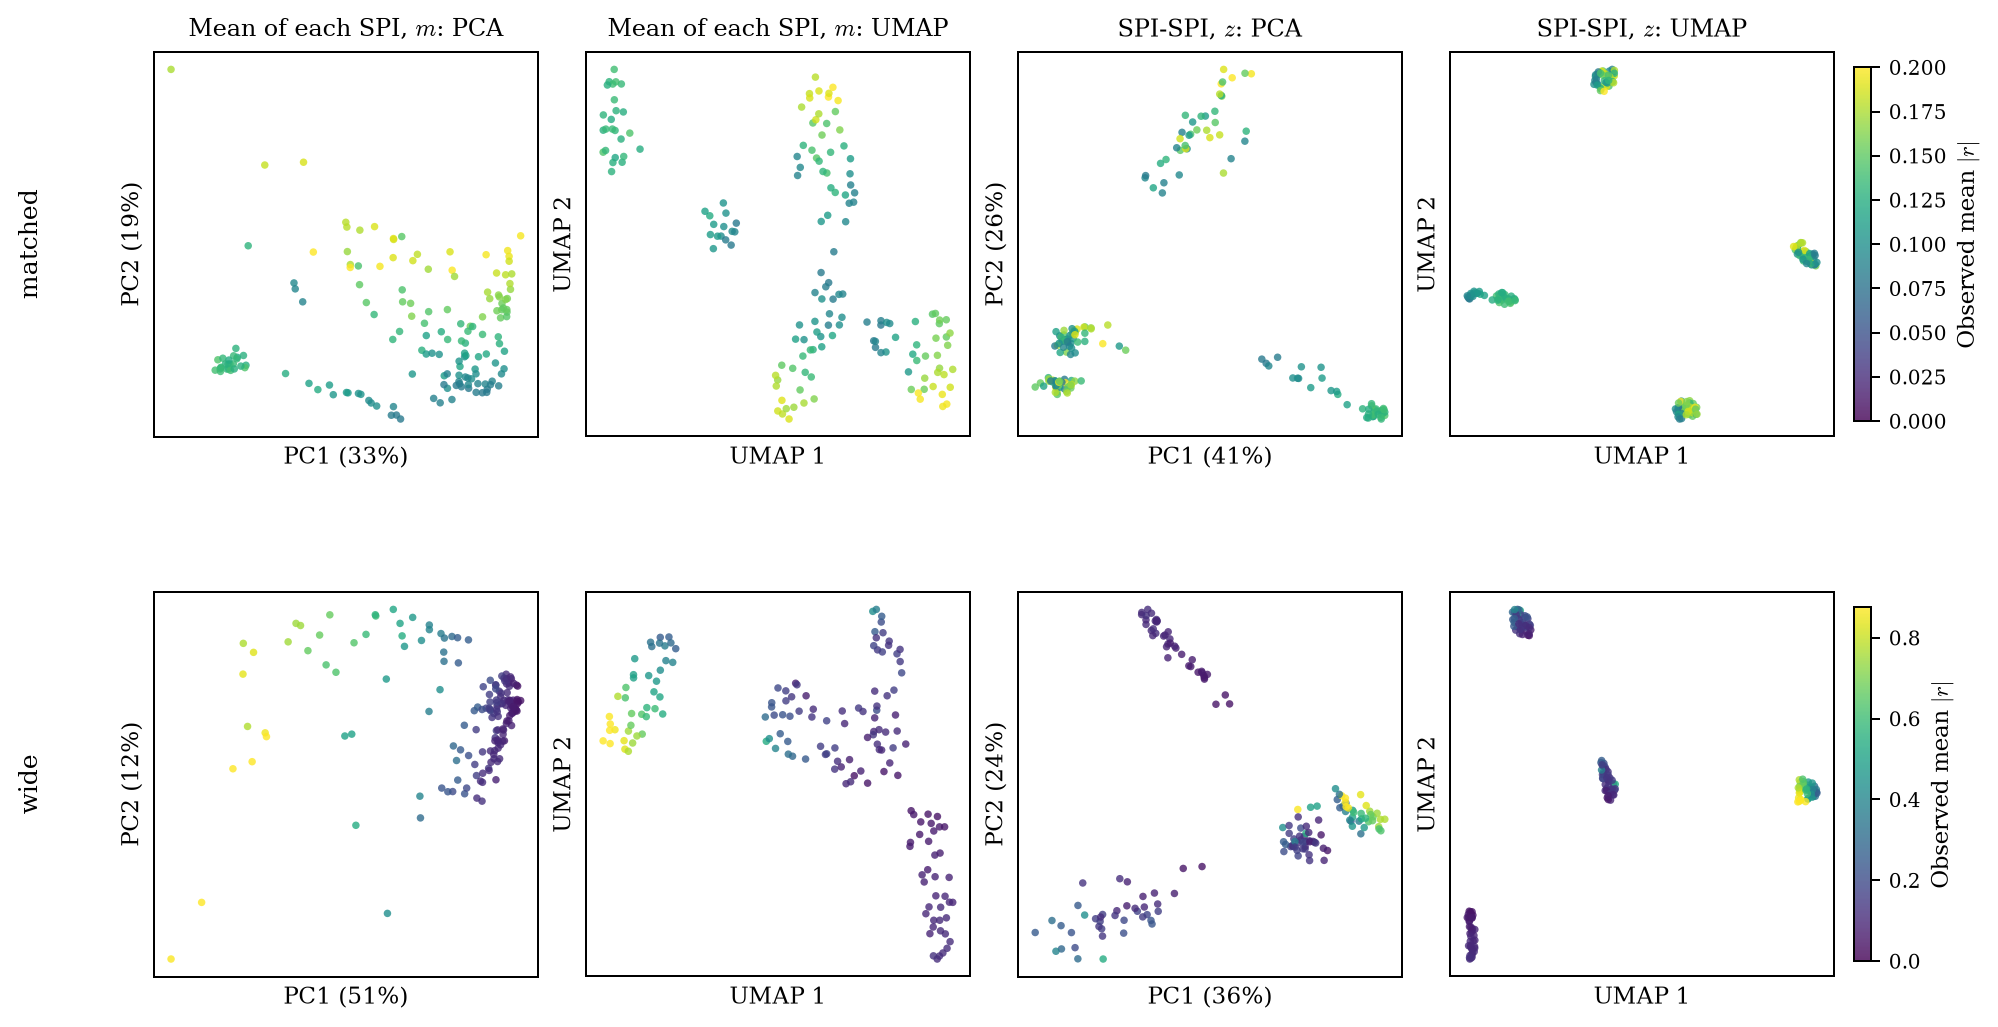

In [4]:
fig = P.embedding_figure(rows, bank, 'cml', ('matched', 'wide'), OUT, color='strength', cache=cache); plt.show()

Feature by feature in the `wide` arm, where noise level is independent of class: how closely each coordinate follows strength among recordings of one class. Most SPI means follow it; most $z$ coordinates do not, though a minority do, so $z$ is less sensitive to strength rather than blind to it.

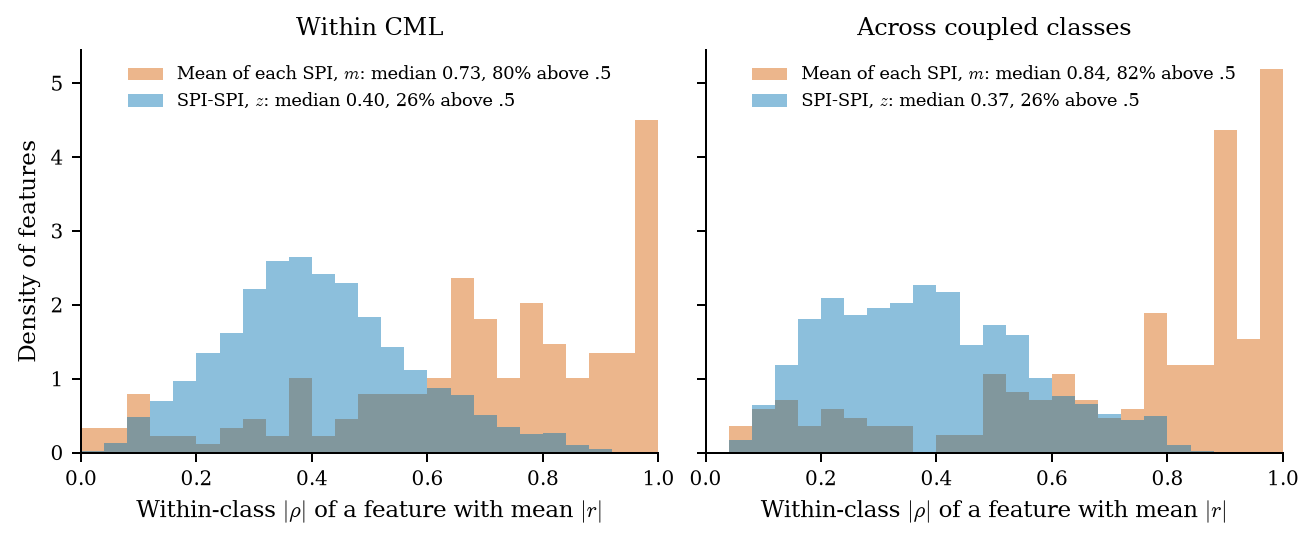

In [5]:
fig = P.dependence_figure(rows, bank, 'wide', OUT); plt.show()

Across classes. Strength variation turns the mean PCA into overlapping streaks, but the families differ in far more than strength and the mean UMAP still separates them. Under heavy noise neither representation separates the two VARs from Kuramoto in two dimensions.

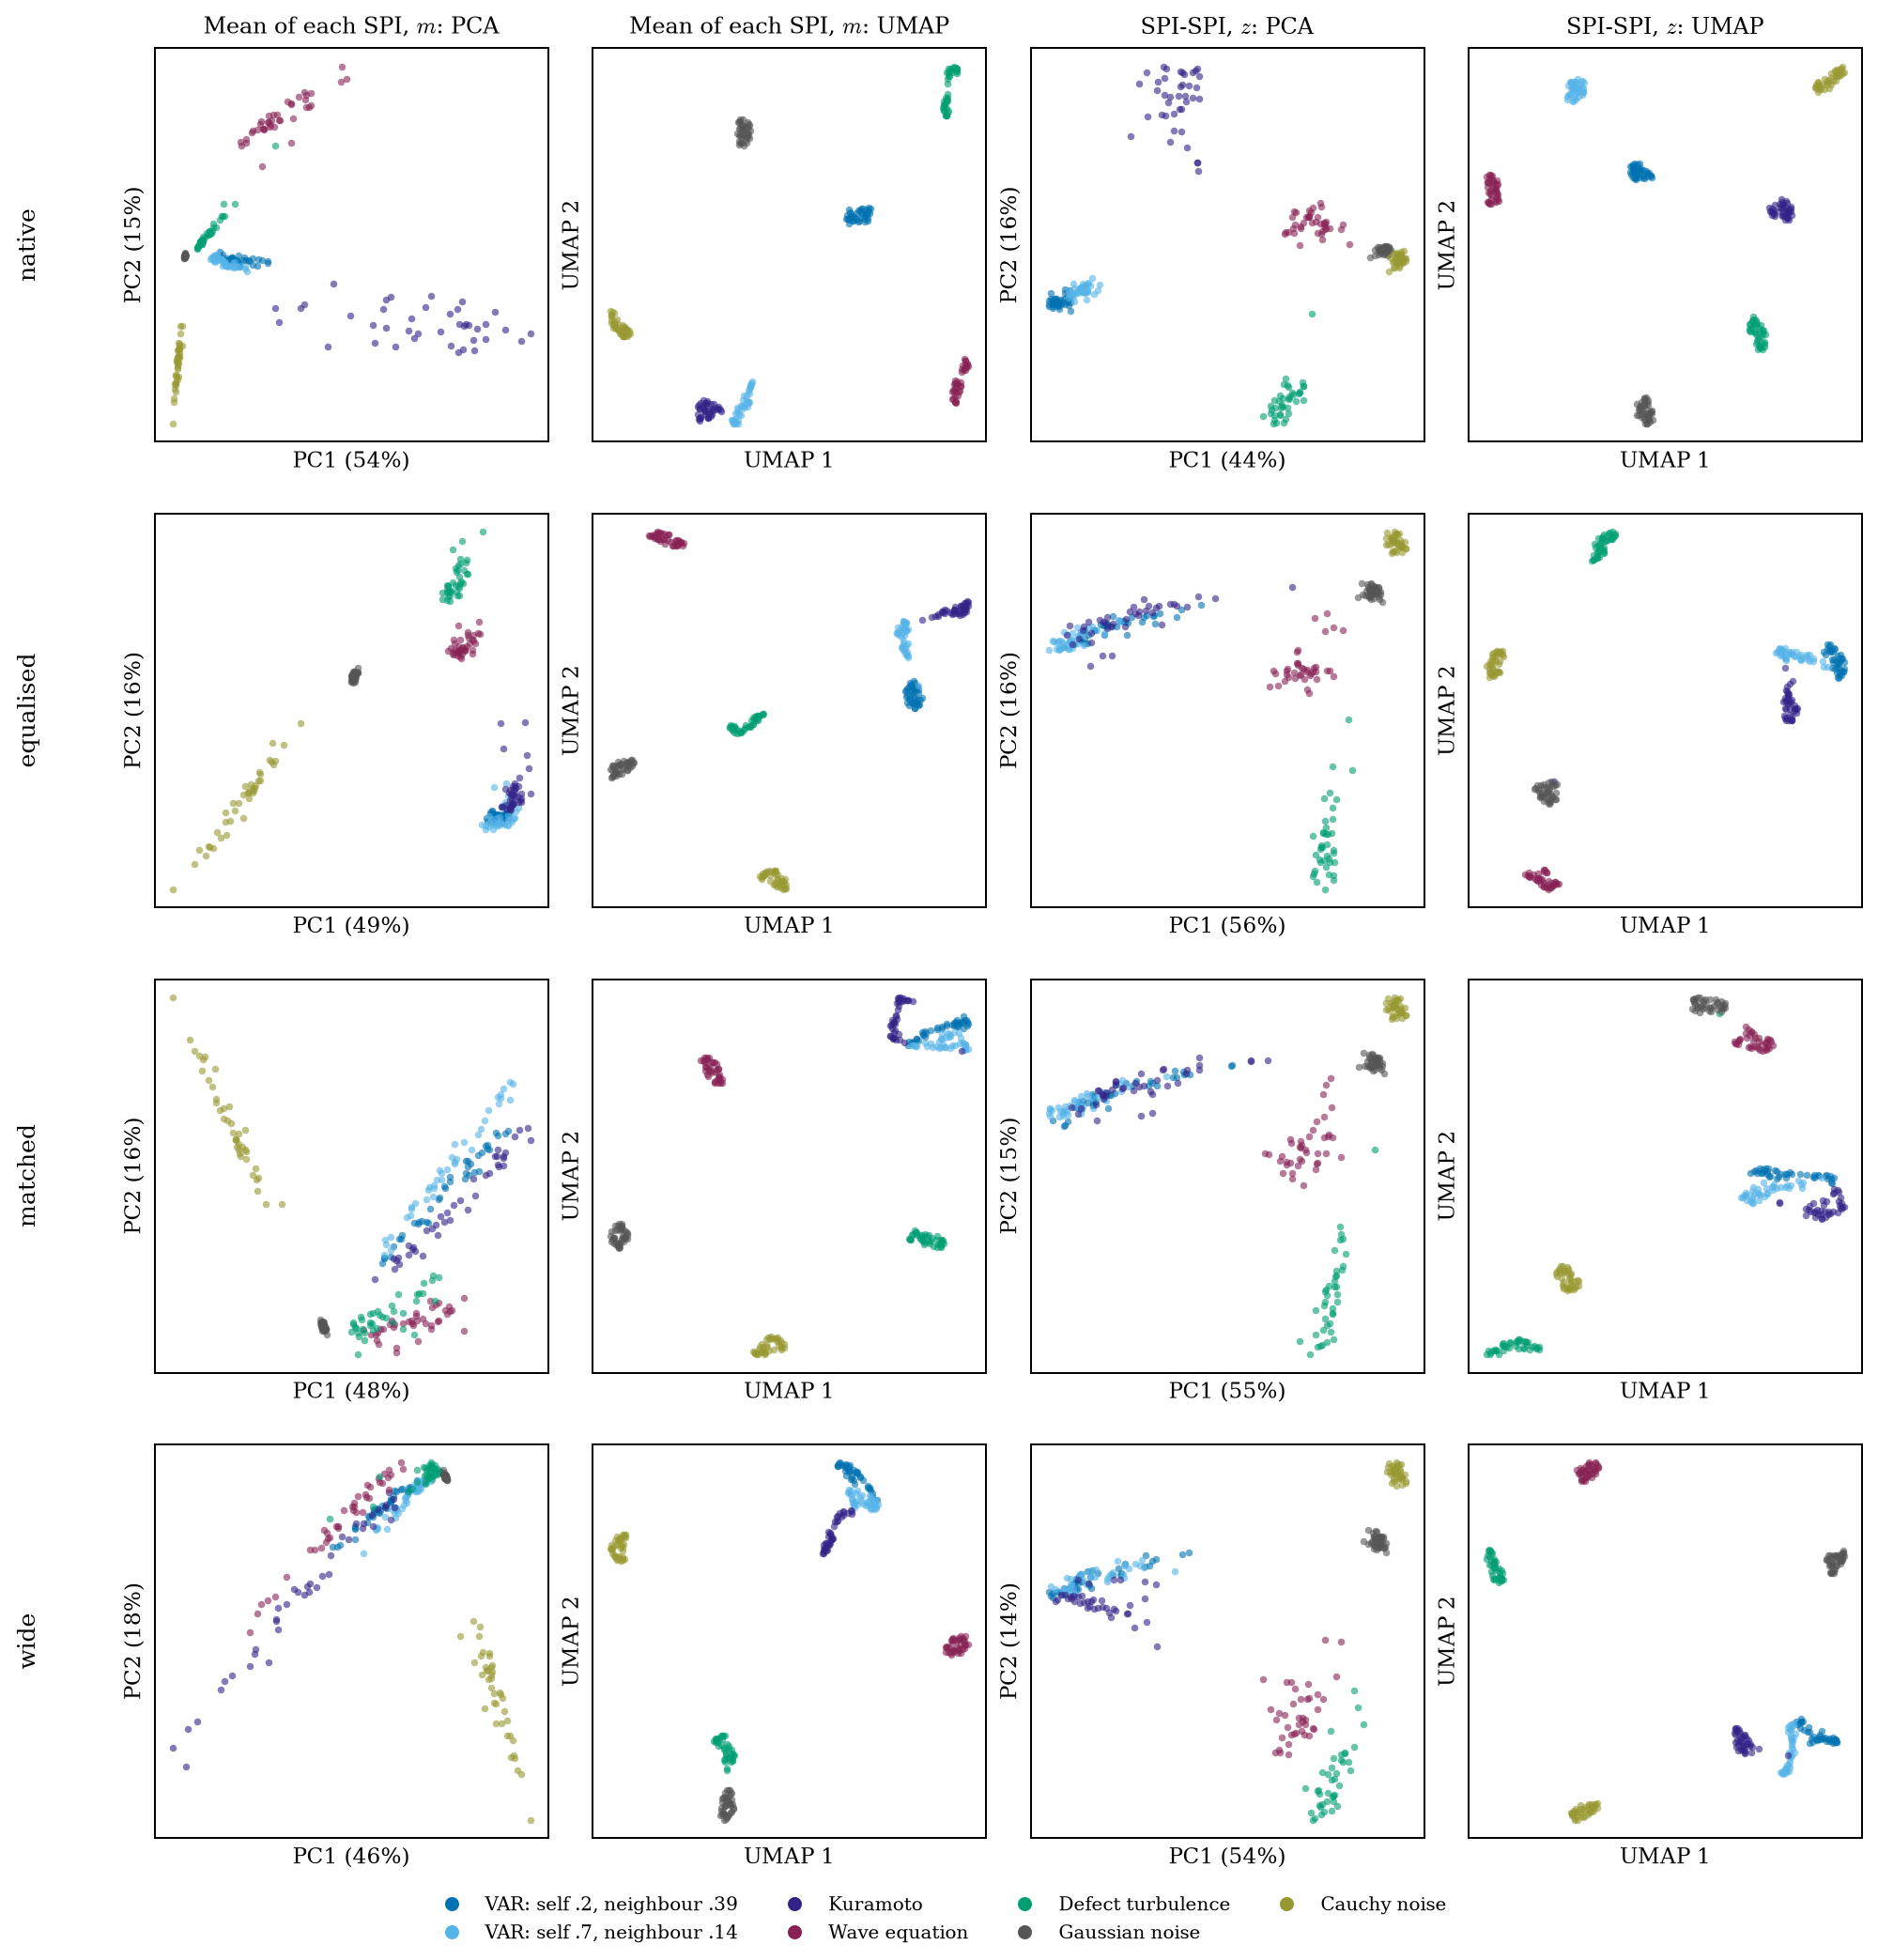

In [6]:
fig = P.embedding_figure(rows, bank, 'inter', ('native', 'equalised', 'matched', 'wide'), OUT, cache=cache); plt.show()

Scores in the 50-PC space of each fit, against class labels that the fit never saw. Silhouette measures cluster compactness; neighbour agreement is the share of each recording's five nearest neighbours in its own class (dotted: chance). `pooled` fits all five arms together. The dashed curve drops the leading component of $m$, the obvious repair once that component is strength.

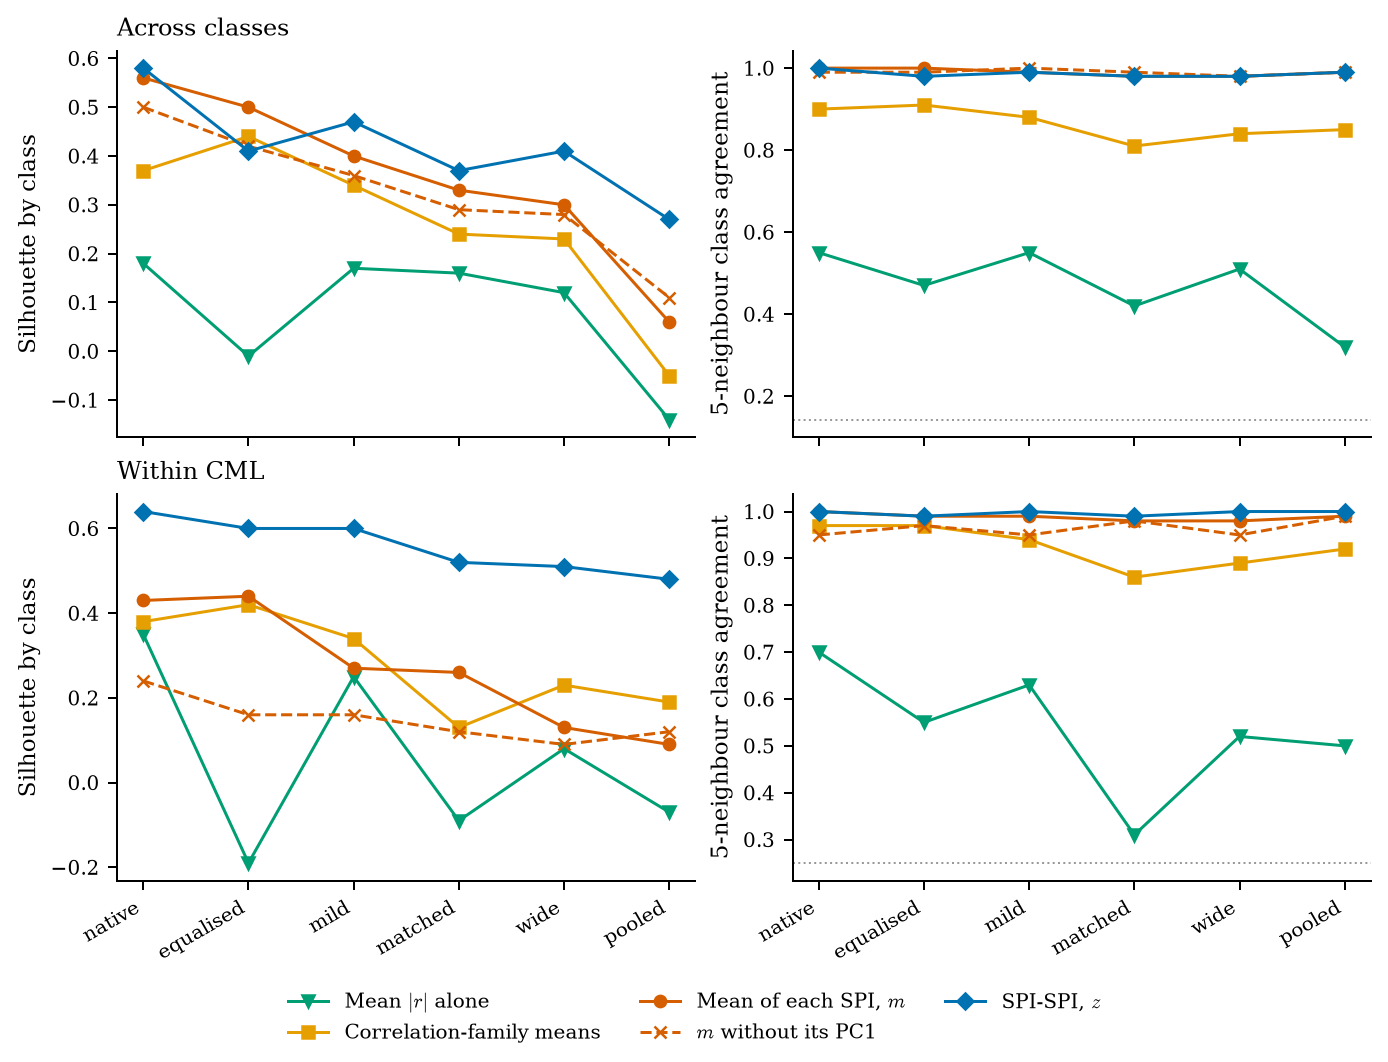

{('native', 'inter'): (0.02, 0.01, 0.03), ('equalised', 'inter'): (-0.09, -0.1, -0.08), ('matched', 'inter'): (0.04, 0.03, 0.06), ('wide', 'inter'): (0.11, 0.09, 0.13), ('native', 'cml'): (0.21, 0.2, 0.23), ('equalised', 'cml'): (0.16, 0.15, 0.17), ('matched', 'cml'): (0.25, 0.23, 0.27), ('wide', 'cml'): (0.38, 0.36, 0.4)}


In [7]:
m = P.metrics(rows, bank); m.to_csv(OUT / 'metrics.csv', index=False)
fig = P.metrics_figure(m, OUT); plt.show()
for panel in P.PANELS:
    display(pd.concat({c: P.table(m, panel, c) for c in ('silhouette', 'purity', 'ceiling')}, axis=1).loc[['strength', 'mean', 'z']].style.format('{:.2f}').set_caption(panel))
print({(a, p): tuple(round(float(v), 2) for v in P.silhouette_gap(rows, bank, a, p)) for p in P.PANELS for a in ('native', 'equalised', 'matched', 'wide')})

The last line is the silhouette of $z$ minus that of $m$ with a 95% interval from resampling realizations (embeddings held fixed). `ceiling` is grouped five-fold logistic accuracy on ten PCs. The within-CML ordering does not depend on how either representation is scaled:

In [8]:
P.sensitivity(rows, bank, 'cml')

,native,equalised,mild,matched,wide
"m, unit variance (shown)",0.43,0.44,0.27,0.26,0.13
"m, interquartile range",0.35,0.40,0.23,0.22,0.14
"m, rank-Gaussian",0.39,0.39,0.30,0.28,0.24
"z, centred (shown)",0.64,0.60,0.60,0.52,0.51
"z, unit variance",0.54,0.47,0.44,0.39,0.34


Fresh-seed repeat at $M=24$, `native` and `matched` only. Native strengths are lower at this size, so more recordings are left as generated (78% of fully developed turbulence).

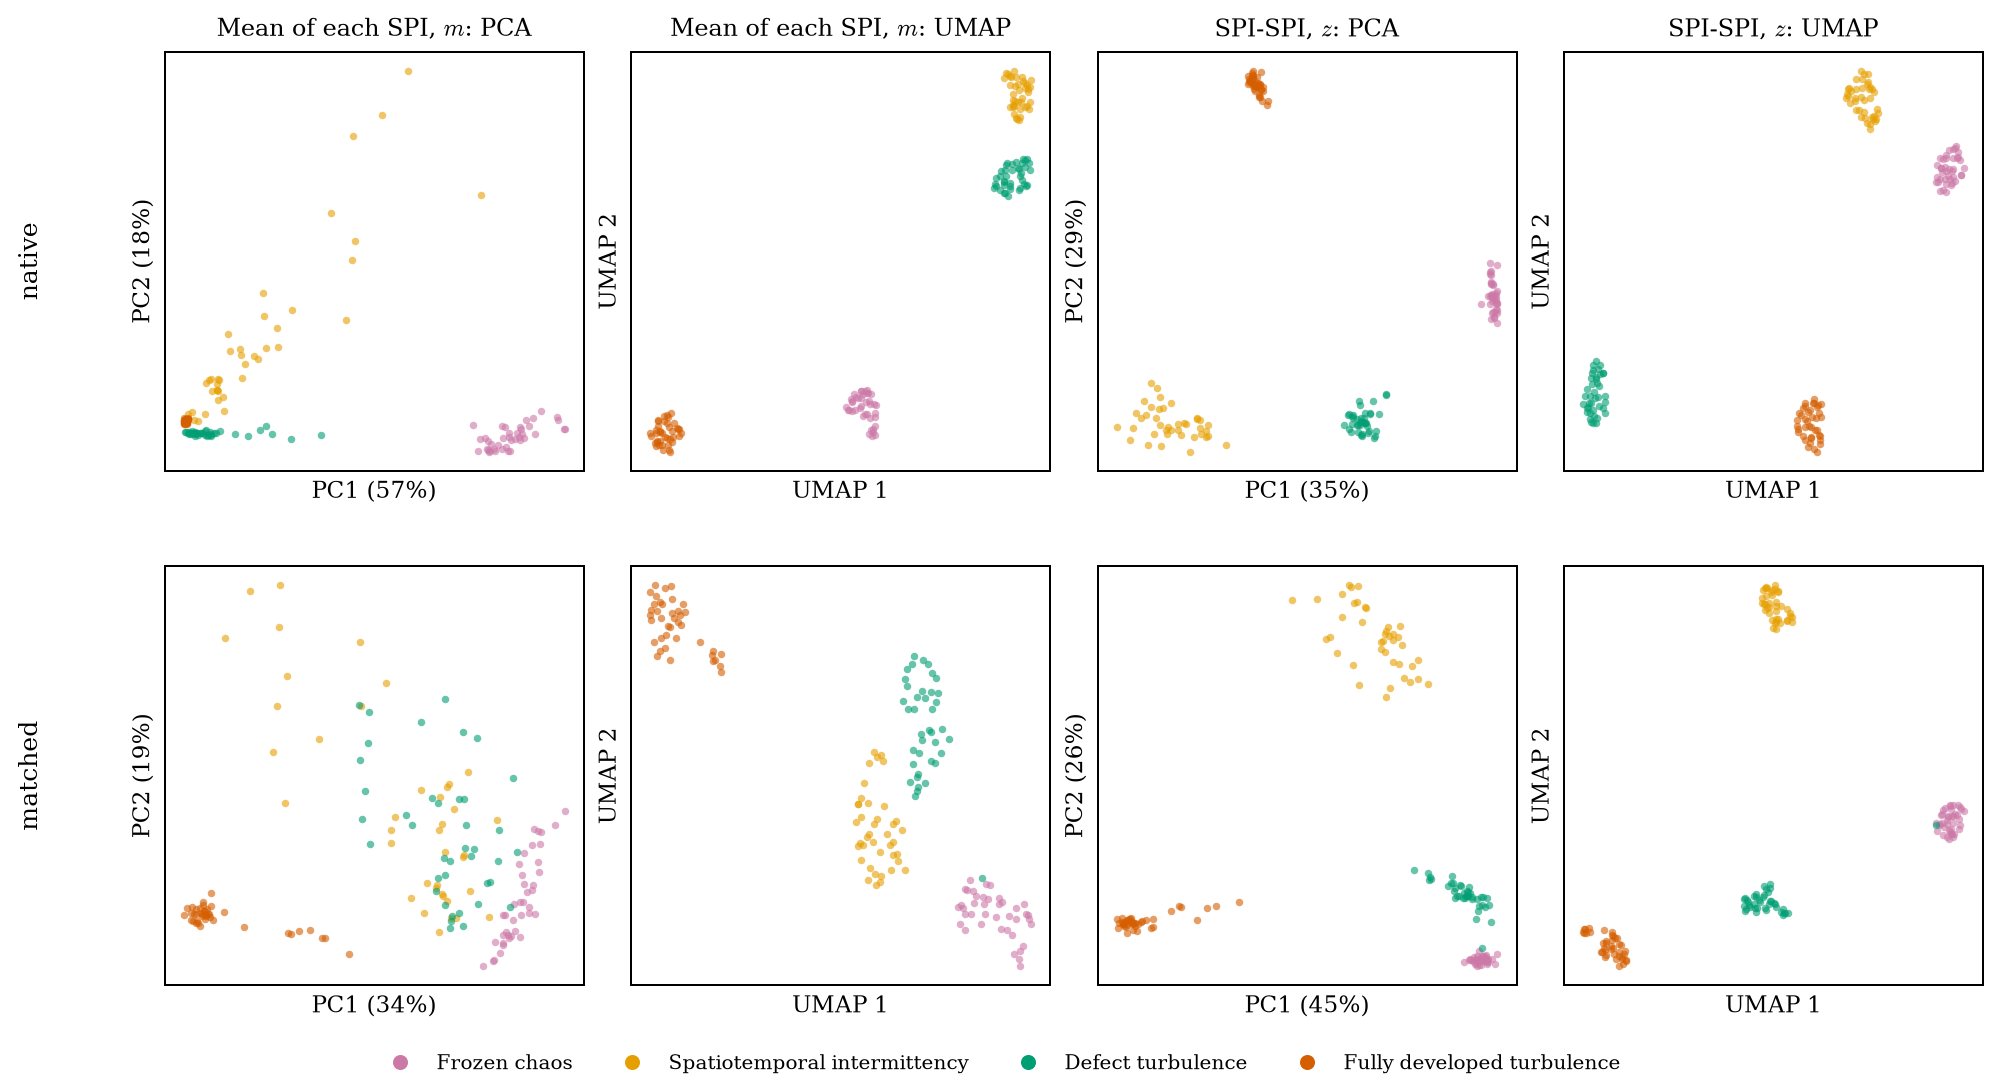

{('native', 'inter'): (0.06, 0.05, 0.07), ('matched', 'inter'): (0.07, 0.05, 0.09), ('native', 'cml'): (0.25, 0.24, 0.27), ('matched', 'cml'): (0.28, 0.27, 0.3)}


In [9]:
rows24, bank24 = P.load('m24'); OUT24 = ROOT / 'results/proof' / P.RUNS['m24']['run']
fig = P.embedding_figure(rows24, bank24, 'cml', ('native', 'matched'), OUT24); plt.show()
m24 = P.metrics(rows24, bank24); m24.to_csv(OUT24 / 'metrics.csv', index=False)
for panel in P.PANELS:
    display(pd.concat({c: P.table(m24, panel, c) for c in ('silhouette', 'purity', 'ceiling')}, axis=1).loc[['strength', 'mean', 'z']].style.format('{:.2f}').set_caption(panel + ', M=24'))
print({(a, p): tuple(round(float(v), 2) for v in P.silhouette_gap(rows24, bank24, a, p)) for p in P.PANELS for a in ('native', 'matched')})

Uncoupled control, added 7 October. For each coupled class, a recording is built from 16 independent realizations, one channel from each: every channel keeps its class's own dynamics and no channel has interacted with another (320 recordings, full p90). `classes apart?` scores class separation within each condition; `coupling visible?` scores, inside one class, coupled against uncoupled recordings. Without interaction the mean vectors still separate all eight classes, and $z$ separates all but the two VARs, which merge. Removing interaction does not remove dependence: frozen chaos, the wave equation and Kuramoto keep mean $|r|$ of .94, .58 and .37 because independent realizations share a deterministic period or mode frequencies.

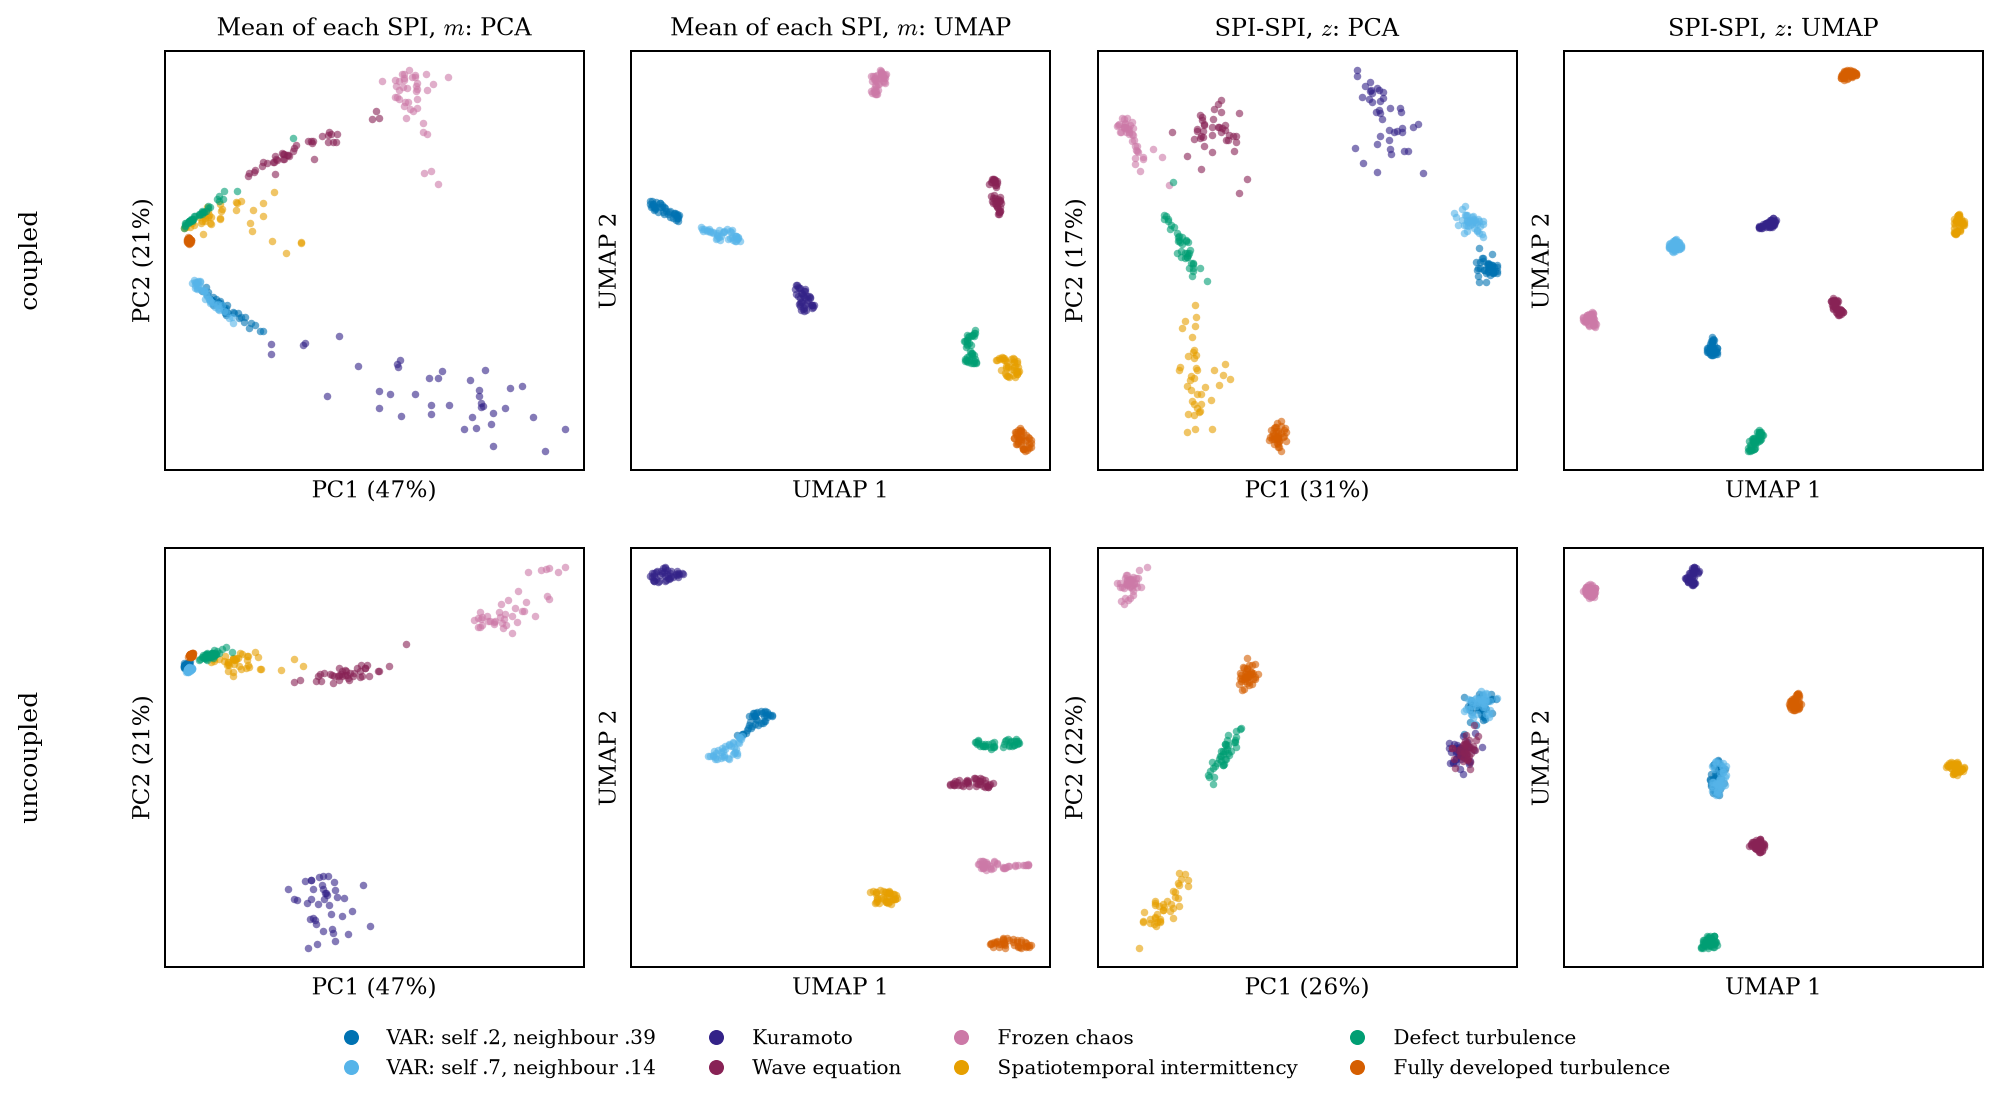

,question,scope,condition,strength_purity,mean_silhouette,mean_purity,z_silhouette,z_purity
0,classes apart?,eight classes,coupled,0.43,0.42,1.00,0.59,1.00
1,classes apart?,eight classes,uncoupled,0.73,0.42,1.00,0.41,0.89
2,classes apart?,CML four,coupled,0.70,0.43,1.00,0.64,1.00
3,classes apart?,CML four,uncoupled,0.75,0.42,1.00,0.50,1.00
4,classes apart?,VAR pair,coupled,0.62,0.40,1.00,0.54,1.00
5,classes apart?,VAR pair,uncoupled,0.61,0.21,1.00,0.02,0.60
6,coupling visible?,var-self-0.2,coupled vs uncoupled,1.00,0.65,1.00,0.78,1.00
7,coupling visible?,var-self-0.7,coupled vs uncoupled,1.00,0.53,1.00,0.76,1.00
8,coupling visible?,kuramoto,coupled vs uncoupled,0.83,0.42,0.94,0.49,1.00
9,coupling visible?,wave-1d,coupled vs uncoupled,0.60,0.13,0.90,0.13,0.90


In [10]:
crows, cbank = P.load_control(); OUTC = ROOT / 'results/proof' / P.RUNS['uncoupled']['run']
fig = P.embedding_figure(crows, cbank, P.COUPLED, ('coupled', 'uncoupled'), OUTC, stem='control'); plt.show()
P.control_table(crows, cbank)

**Reading.**

- *Mean absolute correlation* carries no class information once strength is matched (within CML: neighbour agreement .31 at $M=16$, .38 at $M=24$; chance .25).
- *Equalising strength does not neutralise $m$.* With mean $|r|$ fixed at .14 in every class, $m$ is as clustered as natively (CML silhouette .44 against .43) and across classes more compact than $z$ (.50 against .41). Equal mean $|r|$ does not equalise 289 means: they are responses of different detectors and encode character. Earlier matched-strength runs found the same.
- *Strength that varies between recordings is what degrades $m$.* Within CML the silhouette of $m$ falls to .26 (`matched`) and .13 (`wide`) while $z$ holds .52 and .51; at $M=24$, .32 against .61. Within a class 80% of SPI means follow strength ($|\rho|>.5$) against 26% of $z$ coordinates.
- *$m$ never becomes noise.* Neighbour agreement and supervised accuracy stay at or above .98 for both representations in every arm, and removing the leading component of $m$ does not restore compactness. The supported contrast is the unsupervised geometry, not the information.
- *Most of the class separation needs no interaction.* In the uncoupled control $m$ separates the eight classes as well as before (neighbour agreement 1.00, silhouette .42 in both conditions) and $z$ nearly so (.89). These classes differ in what each channel does alone, so neither panel shows that a representation reads how channels interact. The exception is informative: the two VARs differ, once uncoupled, only in autocorrelation; $m$ still separates them perfectly and $z$ does not (.60, chance .50). Both representations register coupling within a class (at least .84).
- *Qualifications.* $z$ is already more compact than $m$ within CML without any nuisance (silhouette gap .21; .25 `matched`, .38 `wide`), so only the growth of the gap is attributable to strength, and at $M=24$ that growth is small (.25 to .28). Across classes the gap is small in every arm. `equalised` and `matched` add more noise to natively stronger classes, which either representation may exploit; `mild` and `wide` do not. One nuisance (white, equal on all channels), one length.

Why: $z_{ab}$ is unchanged when each SPI's profile across pairs is shifted and rescaled, per recording. Standardising every profile within a recording therefore sets every mean to zero and leaves $z$ exactly as it was, so $z$ is by construction what remains once the set of strengths is removed. Equal sensor noise on all channels approximates such a rescaling for second-order statistics (attenuation by measurement error), which is why $z$ moves less; it also lowers the reliability of each profile and pulls $z$ toward its independent-noise value, which is the residual strength dependence seen above.

Run: `research/proof/baselines/proof_strength_nuisance.py` (`prepare`, external-corpus farm, `extract`); this notebook is rebuilt by `research/proof/baselines/build_proof_strength_notebook.py`. Full p90, estimator seeds 261102 and 261112, 2,720 recordings including the control, none failed.

## Added 15 October: physical coupling versus measurement noise

The nuisance varies **between recordings within each class**. We cross fixed/variable physical coupling with absent/variable independent sensor noise, keeping initial conditions or innovations paired across the four conditions. Classes are VAR, Kuramoto, wave 1D, nominal CML intermittency/defect turbulence, and shared-input Gaussian/Cauchy processes; independent Gaussian/Cauchy references are outside the primary comparison. M=16, T=1000; 40 instances/class, four conditions, plus 80 references: 1,200 fresh recordings, the repository p90 catalogue under one fresh computation version. Historical features above are not pooled with this run. Every channel is sample-centred and standardized before and after adding sensor noise; covariance therefore represents sample correlation up to the estimator denominator.

For standardized finite-variance signals and independent unit-variance sensor errors, $y_i=x_i+\eta\epsilon_i$ gives $\rho^y_{ij}=\rho^x_{ij}/(1+\eta^2)$ at population level. Here each recording gets its own noise level, with nominal attenuation uniform on [.25,.95]. Finite-record estimates and non-correlation SPIs need not follow this identity; Cauchy population covariance is undefined. Sensor noise leaves latent dynamics fixed, while changing measurement quality ([classical attenuation](https://psychclassics.yorku.ca/Spearman/chap1-4.htm)).

Physical coupling parameters independently get multipliers uniform on [.5,1.5]: VAR neighbour coefficient, Kuramoto K, wave c² at fixed cadence, CML epsilon, or common-input loading. Multiplication preserves the coupling rule's form, **not necessarily its emergent dependence pattern or regime**. For example, changing Kuramoto coupling can change synchronization ([finite-network theory](https://arxiv.org/abs/1011.3878)). Shared-input loading is functional dependence, not causal coupling. The ranges and seven classes were fixed before SPI results; no severe-noise tail was selected to make a baseline fail.

Instances 0–19, fixed clean/sensor conditions only, fit all preprocessing and PCA50/UMAP. Instances 20–39 evaluate all four conditions in those same coordinates. Added t-SNE is a joint descriptive fit of all conditions on the same training-derived PCA50 inputs (perplexity 30, PCA initialization, seed 261015, 1,000 iterations); it is not an out-of-sample projection and does not enter any scores. The additional five-class view hides shared-input Gaussian/Cauchy points without refitting or changing limits; independent references remain. Hollow grey symbols project independent Gaussian/Cauchy references; they do not enter fitting or the seven-class scores. The main baseline is the raw MPI mean vector, with training-fitted feature scaling/clipping for differing SPI units; no per-recording mean-vector normalization. z uses the historical symmetrized profile definition and centering. Training validity/variance filtering retains 247 of 289 means and 25,971 z coordinates (12,071 in the complete-training control). Raw-mean full-vector distances/linear/RBF classifiers, standardized/complete-training z, and validity-only classification are recorded as controls. Retrieval uses the fixed-clean training gallery, so query and gallery never share a simulation parent. This tests system/regime recognition and nuisance robustness; it does not independently identify a nonlinear or lag mechanism.

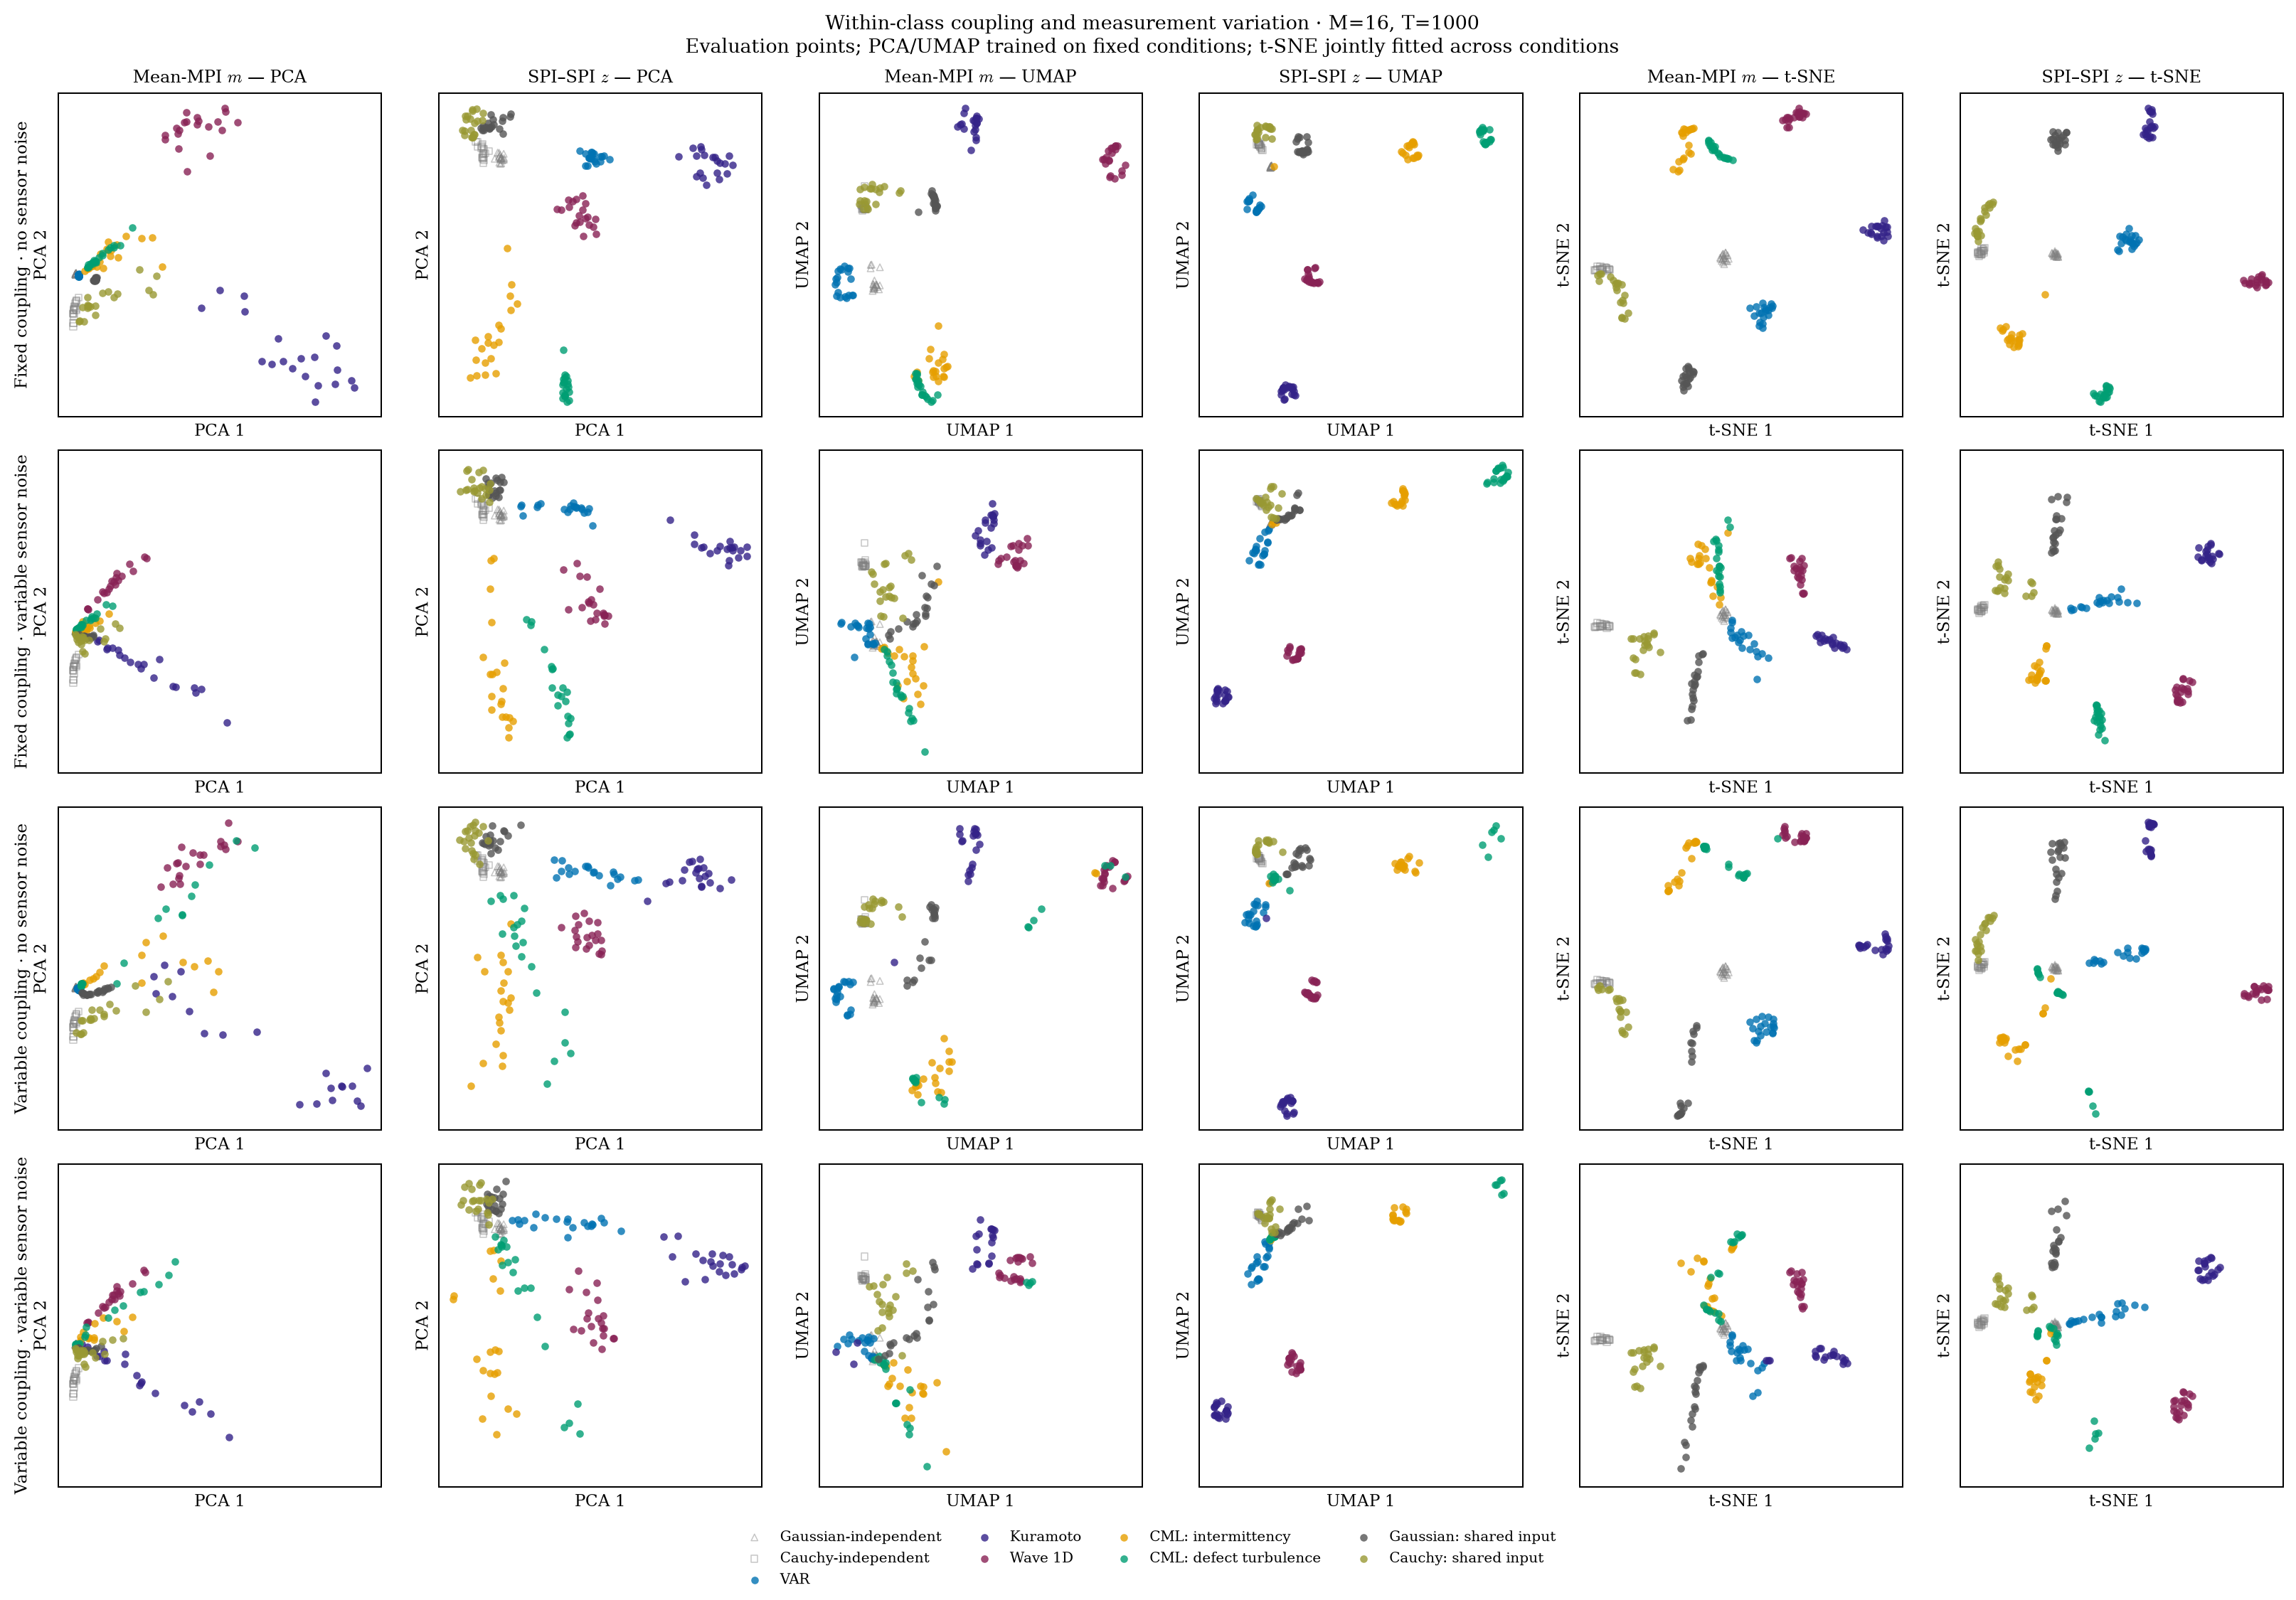

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
FACTOR_ROOT=Path.cwd().resolve()
while not (FACTOR_ROOT/'pyproject.toml').exists() and FACTOR_ROOT!=FACTOR_ROOT.parent: FACTOR_ROOT=FACTOR_ROOT.parent
FACTOR_OUT=FACTOR_ROOT/'results/proof/strength-factorial-261015'
display(Image(filename=str(FACTOR_OUT/'figures/factorial-class.png')))

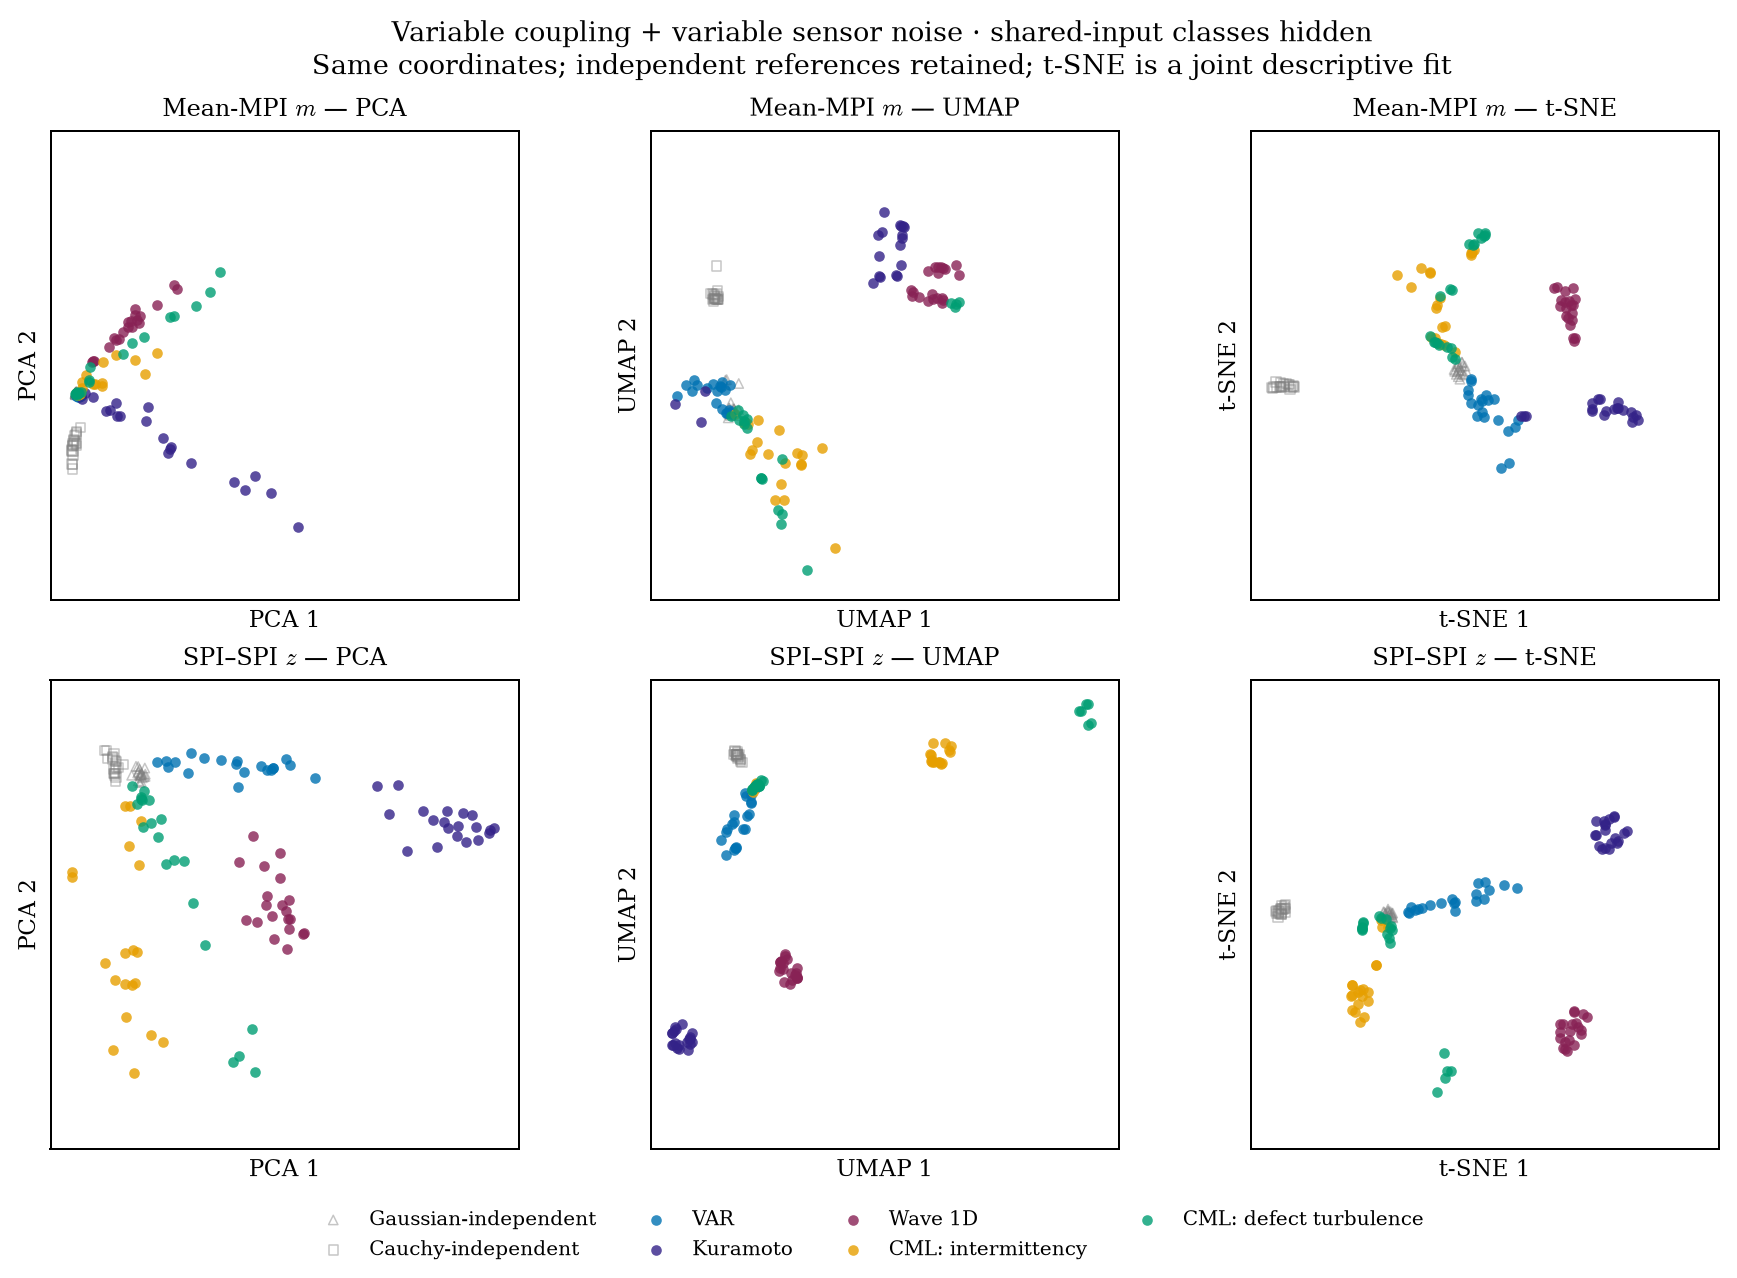

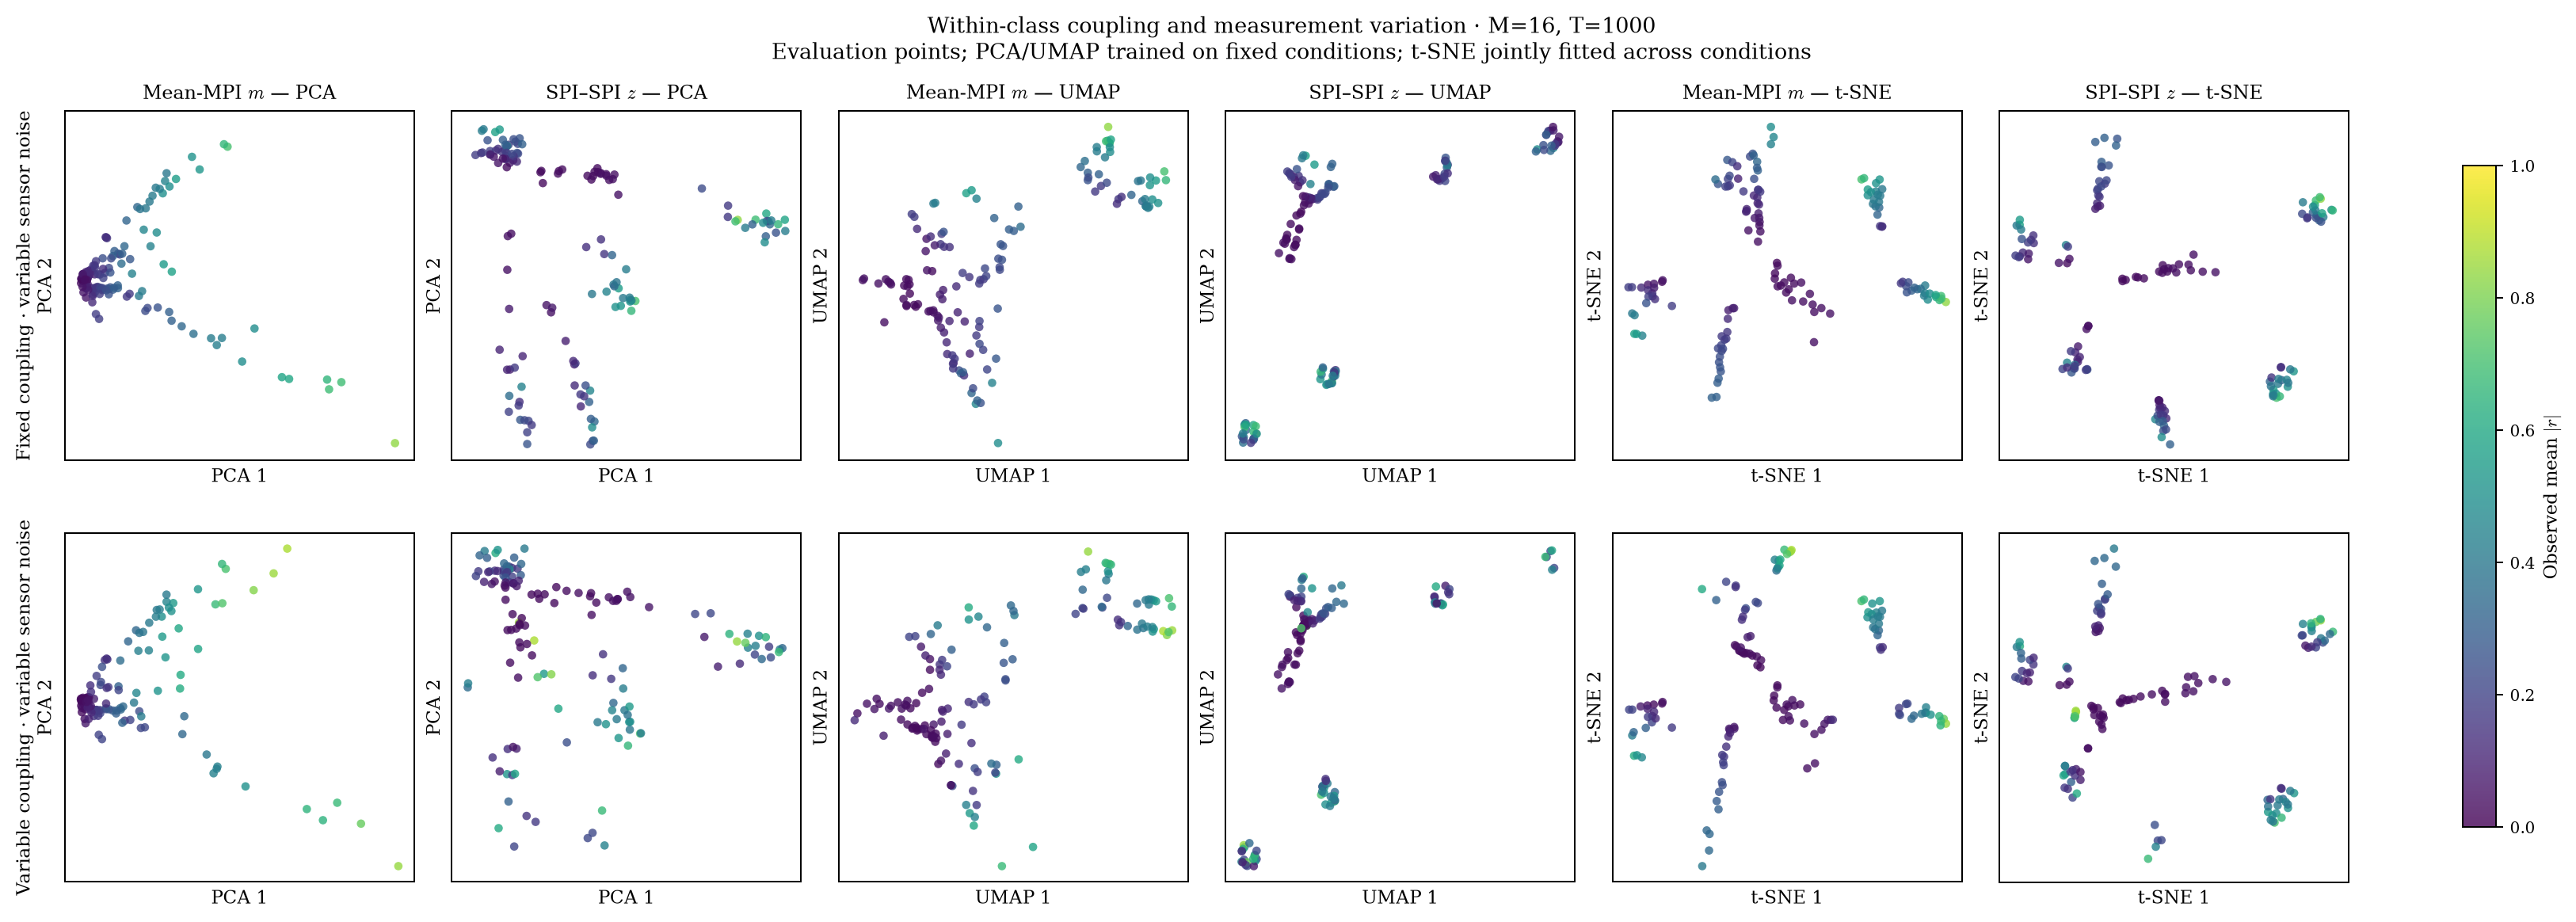

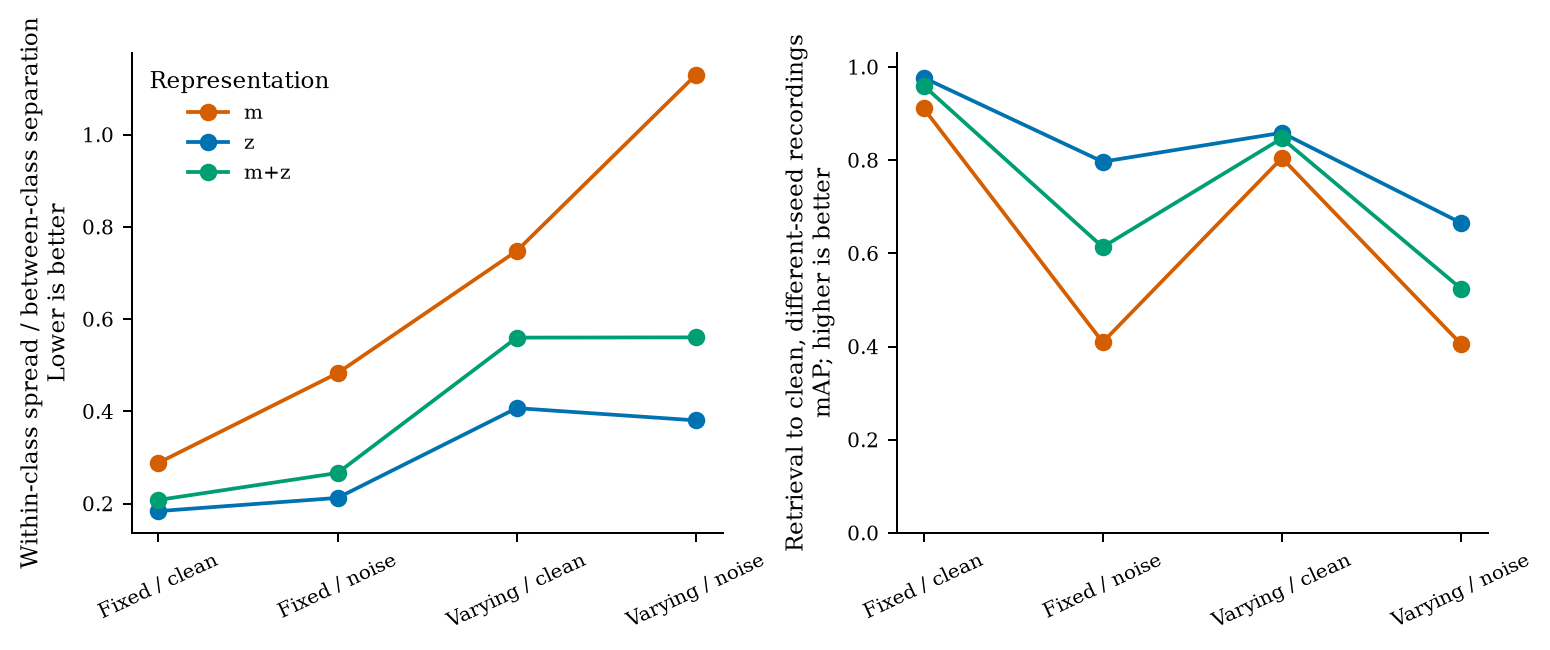

In [2]:
display(Image(filename=str(FACTOR_OUT/'figures/factorial-no-shared.png')))
display(Image(filename=str(FACTOR_OUT/'figures/factorial-strength.png')))
display(Image(filename=str(FACTOR_OUT/'figures/factorial-summary.png')))

In [3]:
factor_scores=pd.read_csv(FACTOR_OUT/'metrics.csv')
display(factor_scores[factor_scores.representation.isin(['m','z','m+z'])].pivot(index='arm',columns='representation',values=['spread_to_separation','mAP','accuracy']).round(3))
display(pd.read_csv(FACTOR_OUT/'intervention-intervals.csv').query("representation == 'z minus m'").round(3))

spread_to_separation                  mAP                \
representation                    m    m+z      z      m    m+z      z   
arm                                                                      
fixed_clean                   0.288  0.208  0.184  0.912  0.960  0.977   
fixed_sensor                  0.483  0.266  0.212  0.409  0.614  0.797   
varying_clean                 0.748  0.560  0.407  0.805  0.847  0.859   
varying_sensor                1.130  0.560  0.380  0.405  0.524  0.665   

               accuracy                
representation        m    m+z      z  
arm                                    
fixed_clean       1.000  1.000  1.000  
fixed_sensor      0.986  0.986  0.986  
varying_clean     0.986  0.914  0.907  
varying_sensor    0.907  0.871  0.893

,contrast,representation,change,low,high
2,fixed_sensor minus fixed_clean,z minus m,-0.166,-0.292,-0.053
5,varying_clean minus fixed_clean,z minus m,-0.236,-0.369,-0.038
8,varying_sensor minus fixed_clean,z minus m,-0.645,-0.926,-0.271


**Result: relative geometry and clean-reference retrieval favour z; classification does not.** With both variations, spread/separation is 1.130 for m versus .380 for z; silhouette .090 versus .355; retrieval mAP .405 versus .665 (paired difference .260, 95% interval [.216,.303]). More importantly, deterioration from fixed/clean is .841 for m versus .197 for z; the paired difference in deterioration is −.645 [−.926,−.271]. These intervals resample evaluation instances, keeping classes/arms paired, conditional on the training fit. Sensor noise alone compresses m's between-class separation more than its within-class spread: “more diffuse” means worse relative separation, not literally larger clouds.

The means remain informative: full-vector linear accuracy is .921 versus z's .893 under both variations. z's retrieval gain is broad but not universal: Wave, shared Gaussian/Cauchy and intermittency improve; nominal defect turbulence worsens (.323 versus m's .482), and Kuramoto remains poor (.217). Combining m+z improves m's retrieval (.524), but does not beat z. The physical-only condition also perturbs z, consistent with altered emergent dynamics; nominal CML regime preservation was not established.

**Checks and limits.** Standardizing z retains a smaller retrieval advantage (.549); restricting to features complete in training strengthens it (.768). Missingness alone predicts classes (accuracy .37–.71 across conditions), so estimator validity is a real confound; complete-training z has only .073% missing evaluation entries in the combined condition. The primary m convention clips training-standardized values at ±5 SD; an explicitly post-result *unclipped* audit gives combined-condition full-mean mAP .401 and accuracy .921, so clipping does not explain that contrast. Extreme clean-condition mean values make unclipped spread particularly unstable. All 1,200 outputs passed provenance checks; 4,624 means and 1,600 z values were independently checked. This supports robustness of this representation/metric pipeline across these systems, not absent information in means or a uniquely identified dependence-character axis.

In [4]:
display(pd.read_csv(FACTOR_OUT/'per-class.csv').query("arm == 'varying_sensor' and representation in ['m','z']").pivot(index='label',columns='representation',values=['spread_to_separation','mAP']).round(3))
factor_audit=json.loads((FACTOR_OUT/'analysis-audit.json').read_text())
print('SPIs:',factor_audit['catalogue_size'],'; computation:',factor_audit['computation'],'; validity-only accuracy:',factor_audit['validity_only_accuracy'])

spread_to_separation           mAP       
representation                       m      z      m      z
label                                                      
CML-defect                       2.592  0.494  0.482  0.323
CML-intermittency                1.217  0.780  0.160  0.634
Cauchy-shared                    0.710  0.290  0.284  0.826
Gaussian-shared                  0.157  0.200  0.653  0.904
Kuramoto                         2.652  0.397  0.161  0.217
VAR                              0.006  0.215  1.000  0.987
Wave                             0.574  0.288  0.098  0.767

SPIs: 289 ; computation: 3.0.0.r9 ; validity-only accuracy: {'fixed_clean': 0.7142857142857143, 'fixed_sensor': 0.39285714285714285, 'varying_clean': 0.7, 'varying_sensor': 0.37142857142857144}


## Size-grid rerun: intermittency and frozen chaos

Five independent realizations per class and $(M,T)$ cell, $M\in\{8,16,32\}$ and $T\in\{500,1000,2000\}$. Four paired conditions per realization and seven classes plus two independent references give 1,350 recordings. Nominal CML frozen chaos ($\alpha=1.45$, $\epsilon=.2$) replaces defect turbulence; the earlier result remains above. Coupling multipliers $U[.5,1.5]$ and nominal noise attenuation $U[.25,.95]$ are unchanged. Increasing T changes recording duration at fixed cadence; the grid avoids T=100, where estimator validity/precision could dominate.

M counts observed sensors: all hosts have 32 channels, with a uniform M-channel subset (CML evolves 100 sites and supplies a central 32-site window). Parents are independent across size cells; the four arms share a parent's initial conditions/innovations and sensor-noise array. This is observation-size robustness, not physical finite-size scaling. Frozen chaos/intermittency name the base settings; varying coupling does not certify preservation of either regime.

Instances 0–2, fixed clean/noisy only, fit preprocessing/PCA50 and UMAP; instances 3–4 evaluate all conditions. Retrieval uses a clean training gallery with different parents. Means use the same training scaling/clipping as before, with full/unclipped controls and no normalization of each recording’s mean vector. SPI–SPI retains the historical proof convention: Pearson correlation of aligned symmetrized off-diagonal MPI profiles. t-SNE jointly fits all display conditions on the training-derived PCA50 inputs and is descriptive only. Marker **area scales as $\sqrt{M}$**; shape denotes T. No class/point/embedding selection based on outcomes. Cross-size retrieval restricts the gallery to recordings with both a different M and a different T. Descriptive M/T effects are fractions of within-class squared spread explained by each size factor, allowing a different shift per class; they include finite-sample variation and do not imply causal size effects. Only two evaluation instances per class/cell means cell-specific scores are exploratory.

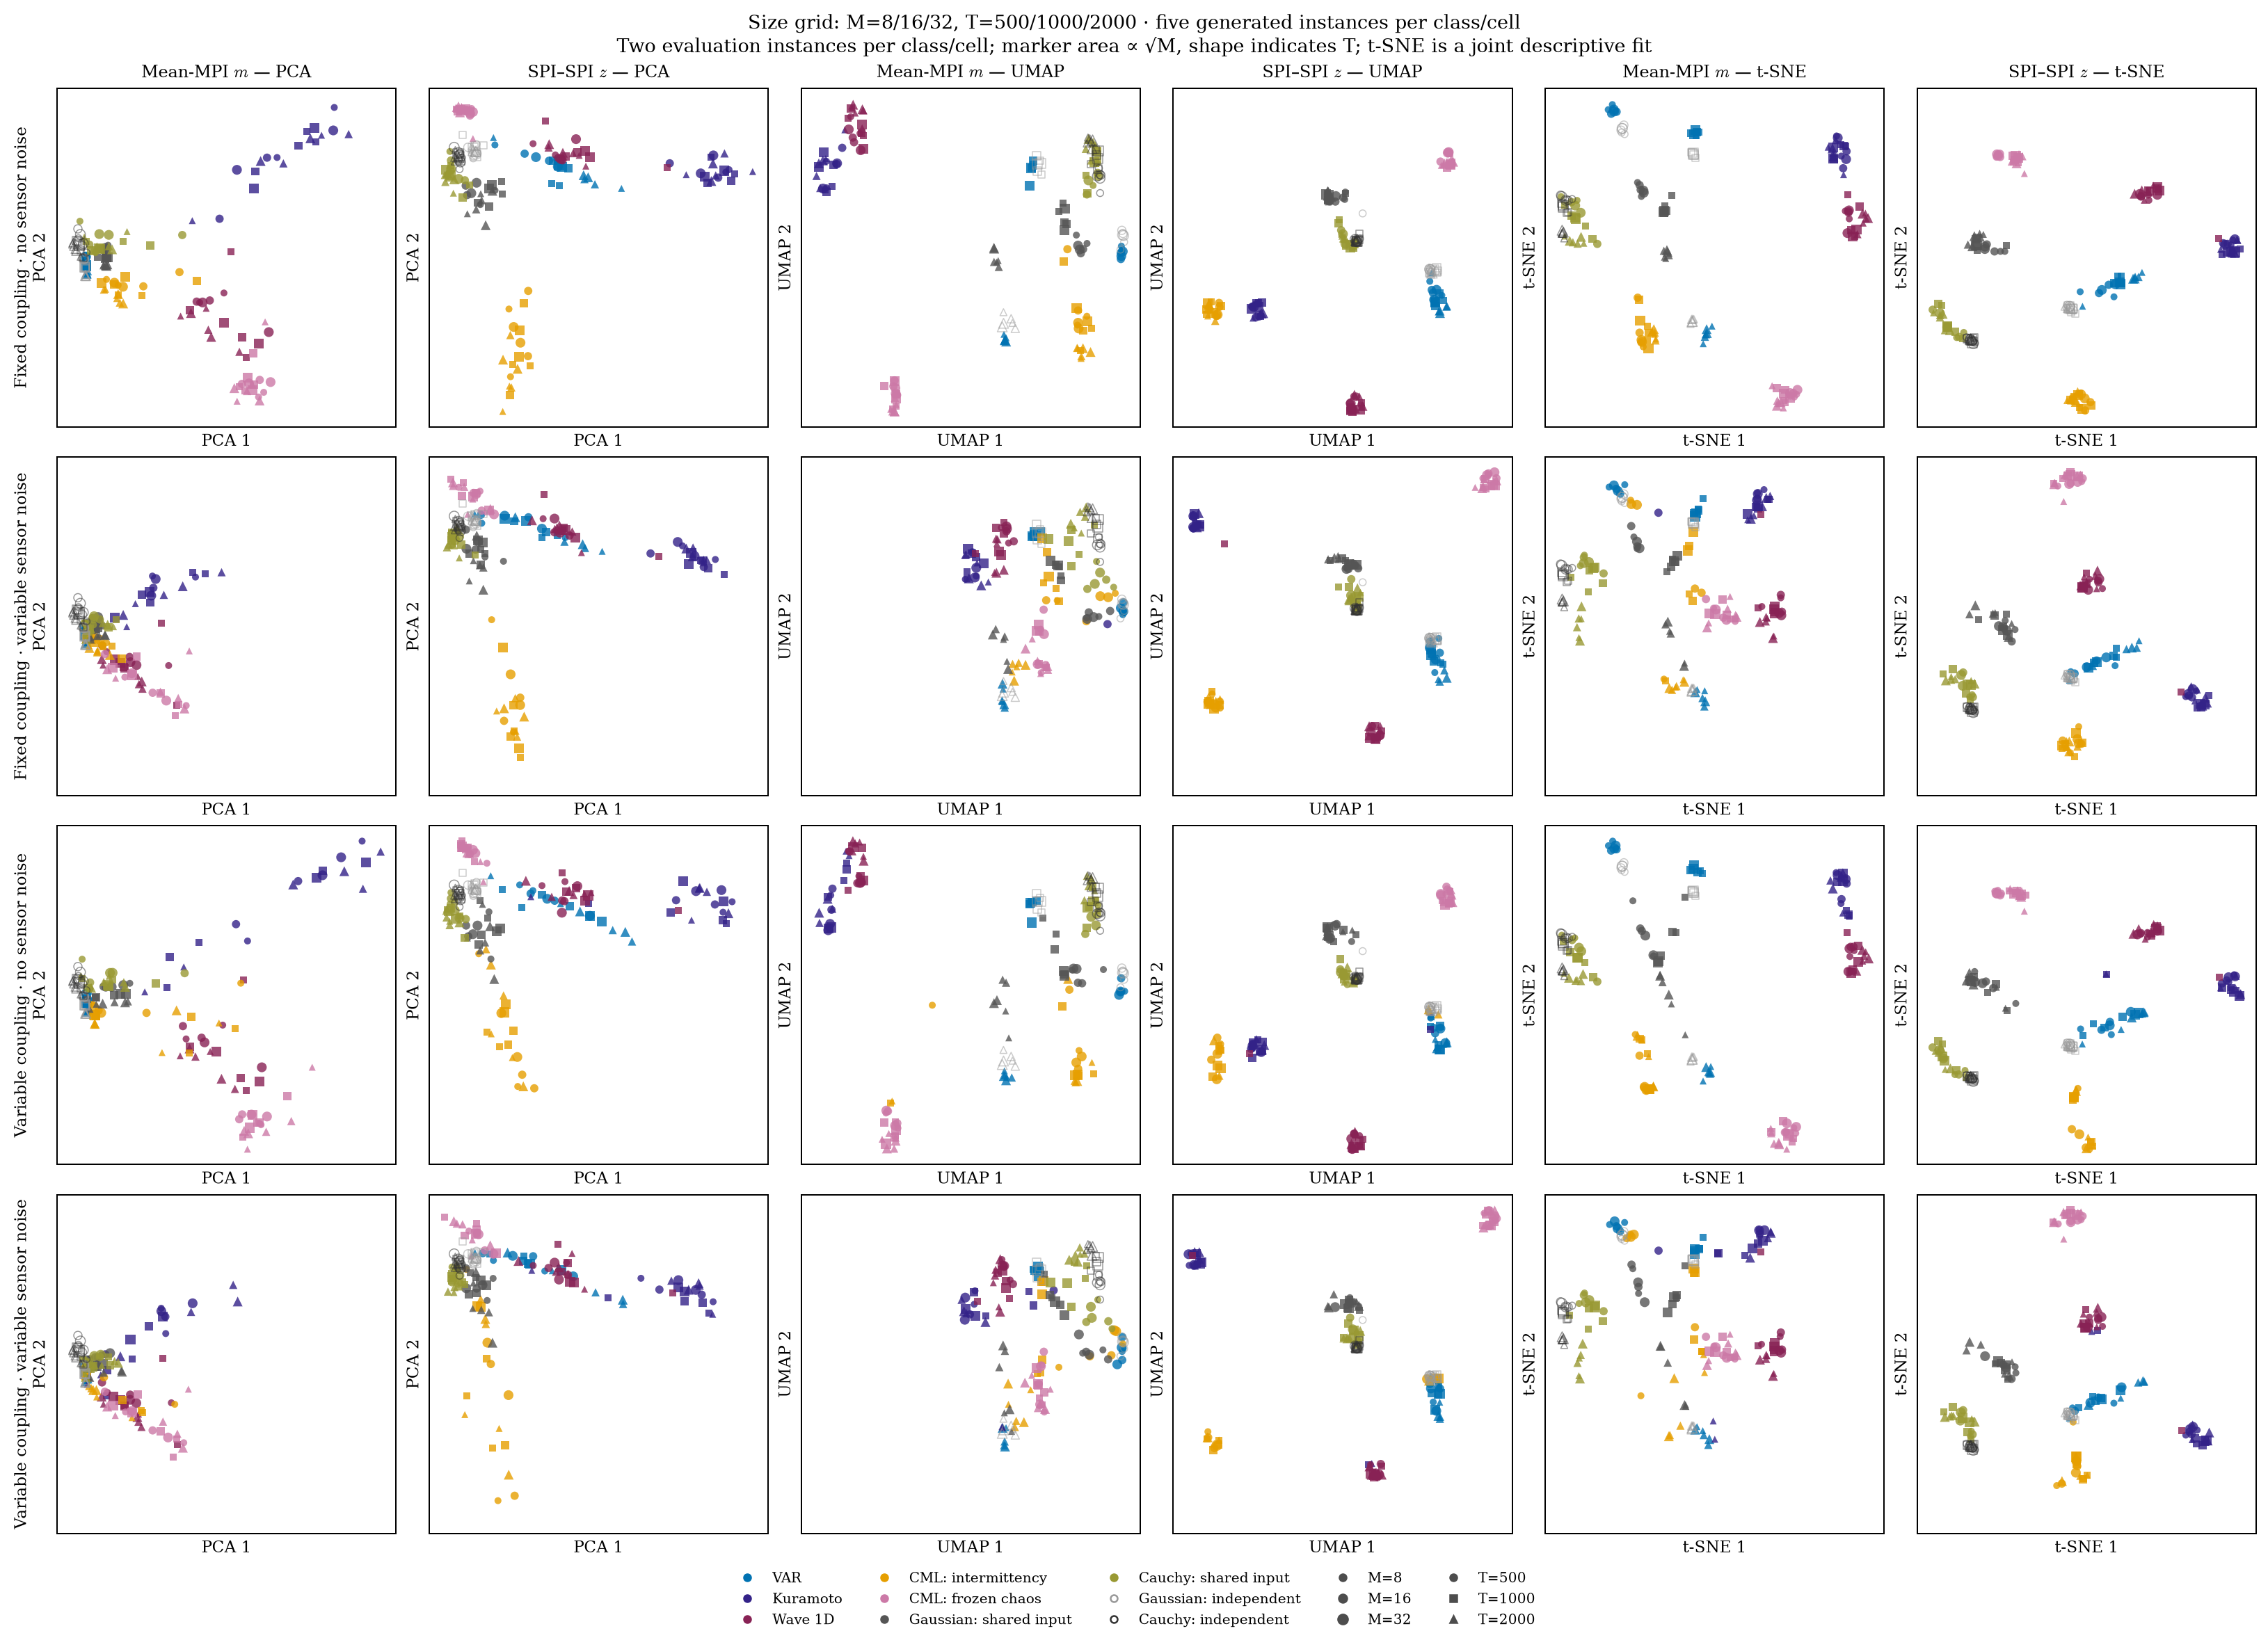

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
GRID_ROOT=Path.cwd().resolve()
while not (GRID_ROOT/'pyproject.toml').exists() and GRID_ROOT!=GRID_ROOT.parent: GRID_ROOT=GRID_ROOT.parent
GRID_OUT=GRID_ROOT/'results/proof/strength-grid-261015'
display(Image(filename=str(GRID_OUT/'figures/grid-class.png')))

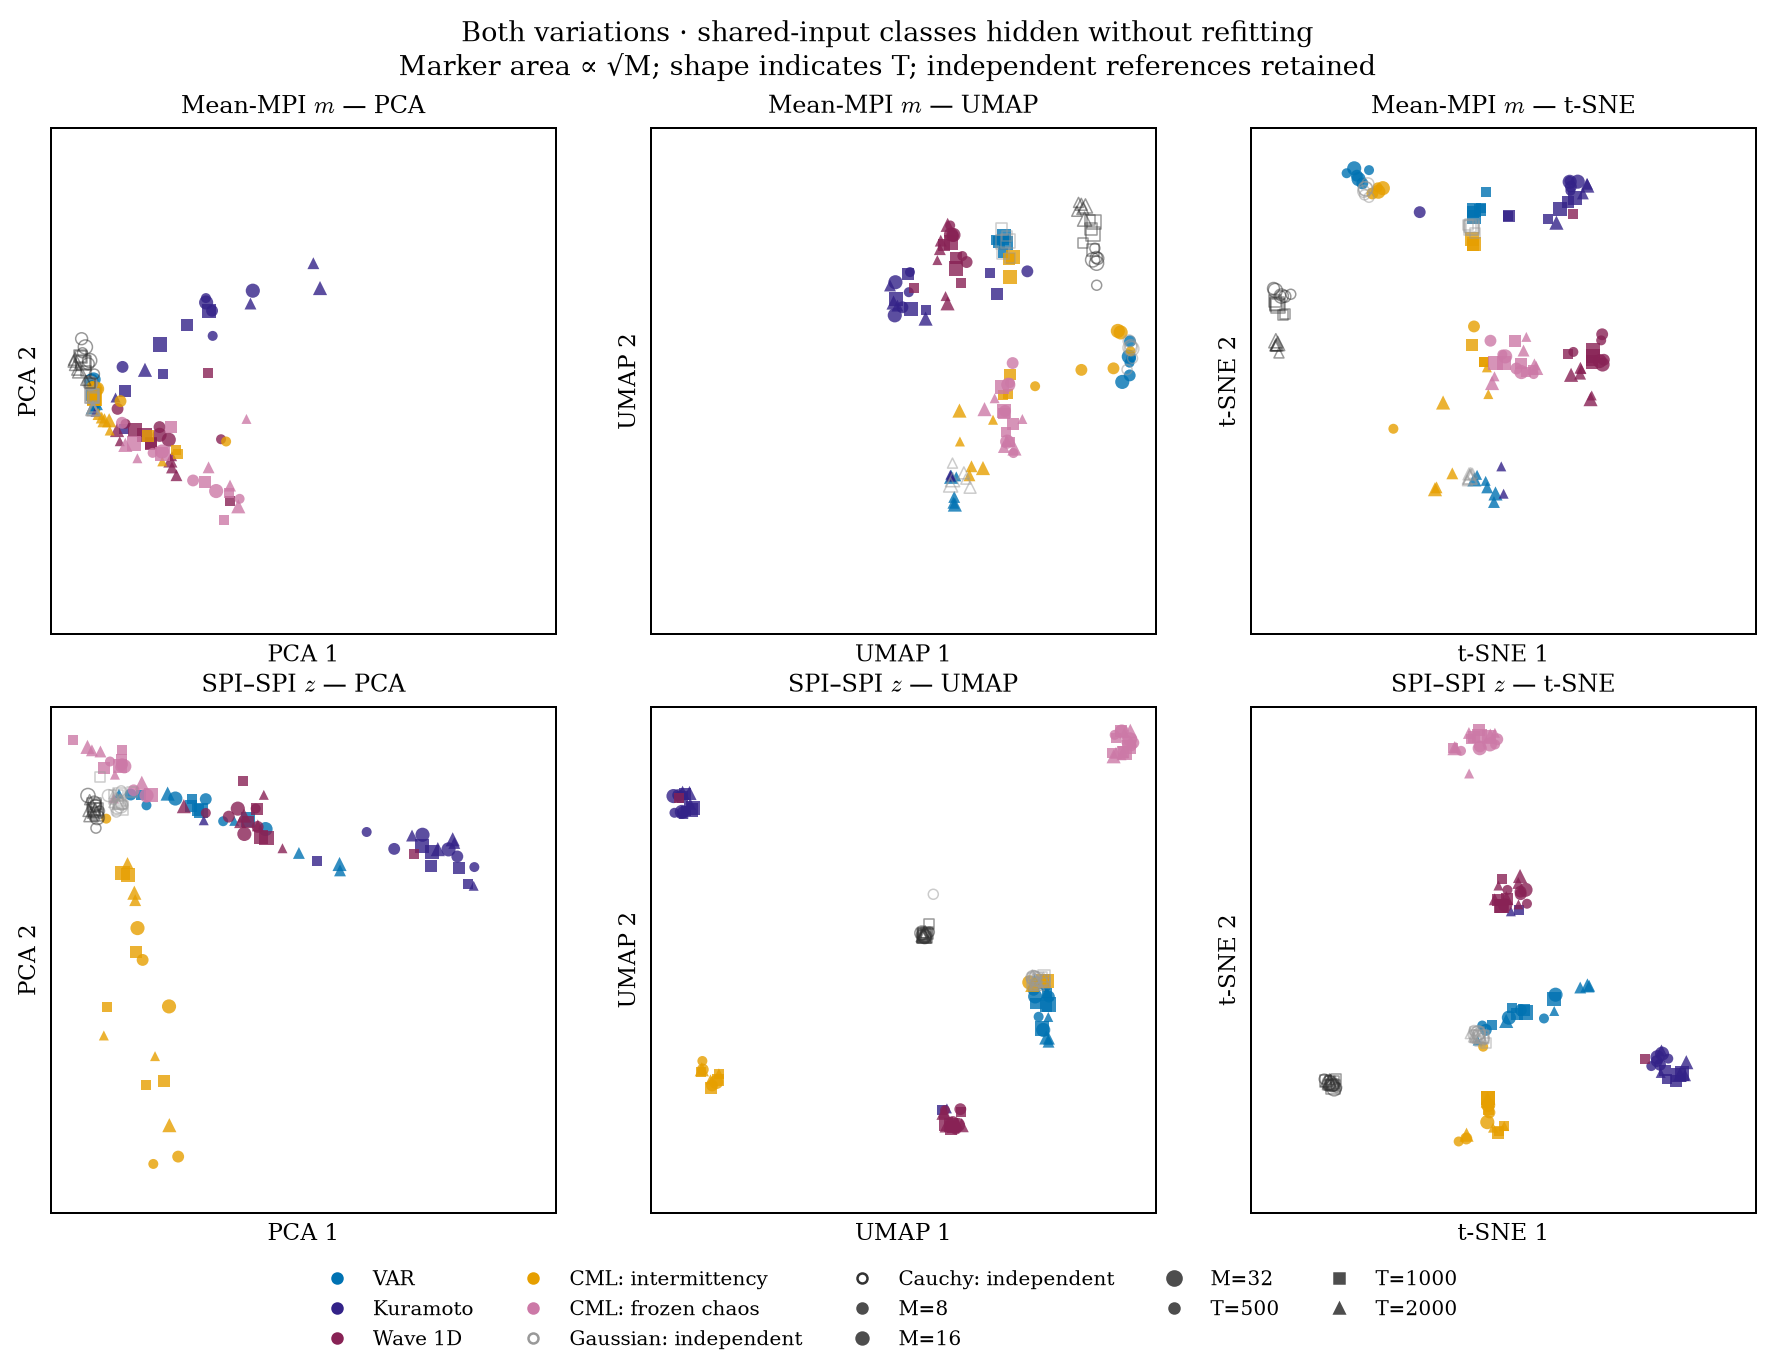

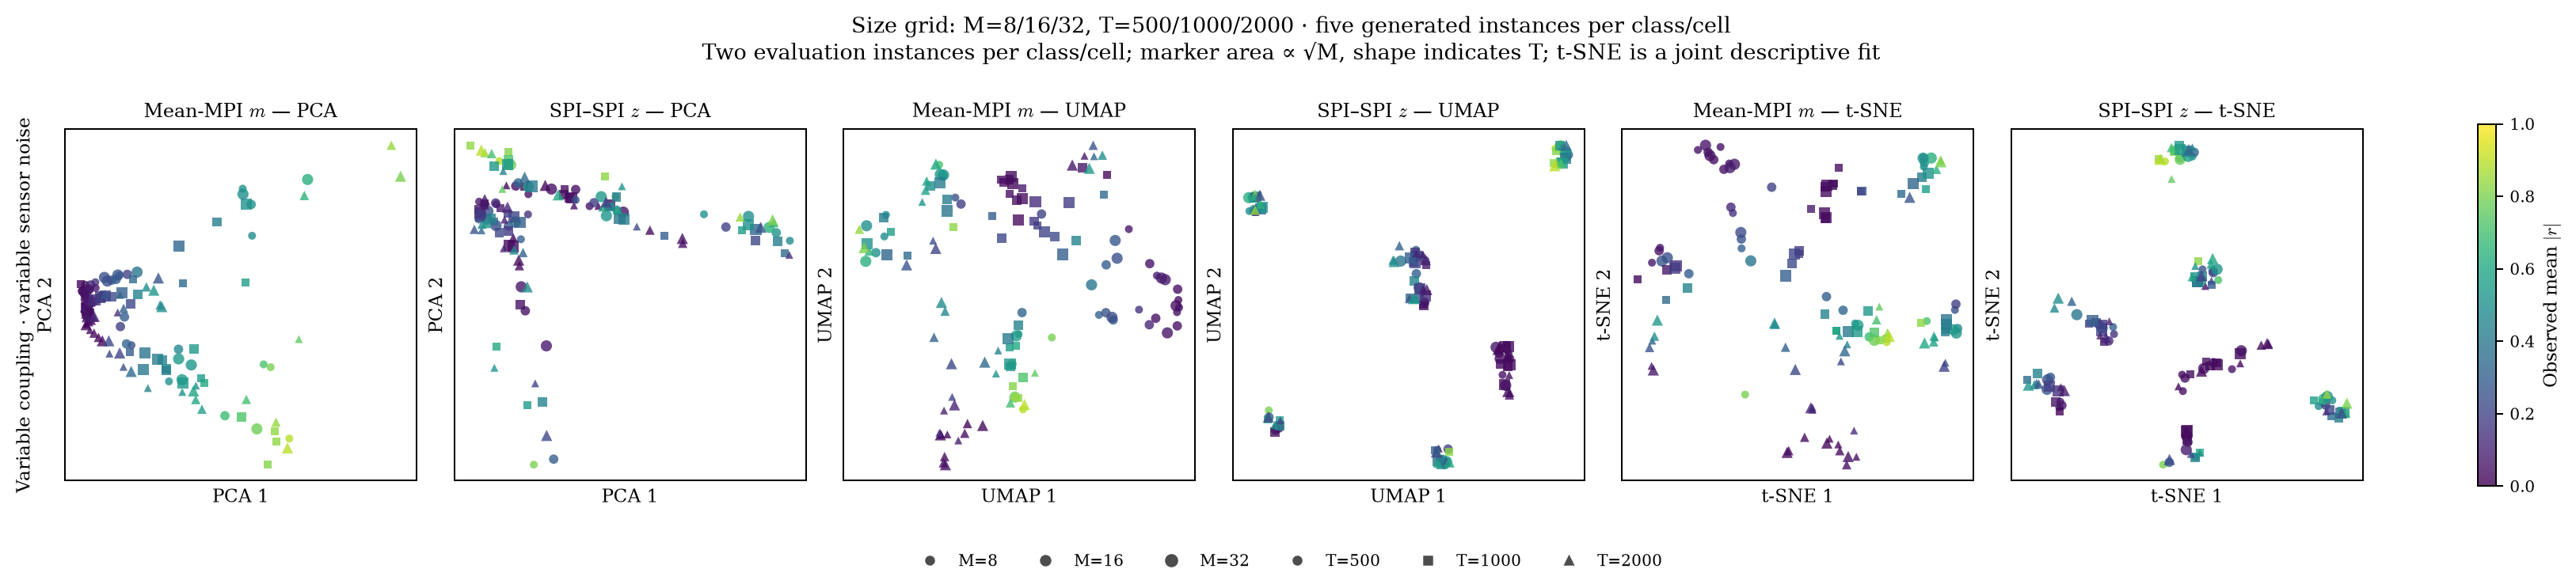

In [2]:
display(Image(filename=str(GRID_OUT/'figures/grid-no-shared.png')))
display(Image(filename=str(GRID_OUT/'figures/grid-strength.png')))

In [3]:
grid_scores=pd.read_csv(GRID_OUT/'metrics.csv')
display(grid_scores.query("cell == 'all' and representation in ['m','z','m+z']").pivot(index='arm',columns='representation',values=['spread_to_separation','mAP','accuracy']).round(3))
display(grid_scores.query("cell != 'all' and arm == 'varying_sensor' and representation in ['m','z']").pivot(index='cell',columns='representation',values=['spread_to_separation','mAP']).round(3))
display(pd.read_csv(GRID_OUT/'cross-size-retrieval.csv').query("representation in ['m','z']").groupby(['arm','representation']).mAP.mean().unstack().round(3))
display(pd.read_csv(GRID_OUT/'size-effects.csv').query("representation in ['m','z']").round(3))

spread_to_separation                  mAP                \
representation                    m    m+z      z      m    m+z      z   
arm                                                                      
fixed_clean                   0.337  0.268  0.261  0.908  0.959  0.966   
fixed_sensor                  0.639  0.350  0.284  0.405  0.602  0.762   
varying_clean                 0.546  0.444  0.433  0.845  0.896  0.900   
varying_sensor                0.972  0.578  0.479  0.408  0.552  0.694   

               accuracy                
representation        m    m+z      z  
arm                                    
fixed_clean       0.992  0.992  0.992  
fixed_sensor      0.984  0.992  0.992  
varying_clean     0.952  0.976  0.960  
varying_sensor    0.960  0.929  0.937

spread_to_separation           mAP       
representation                    m      z      m      z
cell                                                    
M16-T1000                     0.344  0.121  0.341  0.725
M16-T2000                     0.077  0.083  0.558  0.719
M16-T500                      0.399  0.145  0.309  0.614
M32-T1000                     0.072  0.027  0.353  0.657
M32-T2000                     0.677  0.383  0.499  0.711
M32-T500                      0.062  0.080  0.384  0.726
M8-T1000                      0.176  0.280  0.469  0.719
M8-T2000                      0.546  0.433  0.342  0.673
M8-T500                       0.460  0.376  0.416  0.700

representation,m,z
arm,,
fixed_clean,0.914,0.970
fixed_sensor,0.410,0.764
varying_clean,0.854,0.908
varying_sensor,0.418,0.703


,representation,arm,M_fraction_within_class,T_fraction_within_class
0,m,fixed_clean,0.106,0.297
1,m,fixed_sensor,0.059,0.305
2,m,varying_clean,0.226,0.176
3,m,varying_sensor,0.151,0.255
8,z,fixed_clean,0.099,0.213
9,z,fixed_sensor,0.089,0.191
10,z,varying_clean,0.198,0.121
11,z,varying_sensor,0.156,0.135


**Geometry/retrieval contrast survives the size grid; means remain informative.** Under both variations, spread/separation is .972 for m versus .479 for z, compared with .337/.261 when clean and fixed. Clean-reference mAP is .408/.694; restricting retrieval to a different M **and** T gives .418/.703. Retrieval favours z in every size cell and every class on average, although Kuramoto remains weak (m/z .181/.285). Cellwise compactness does not uniformly favour z: three of nine cells reverse the comparison, with only two evaluation instances per class/cell. UMAP shows the clearest visual contrast; t-SNE also organizes means, while two-dimensional PCA retains overlap.

**Size is not eliminated.** With both variations, descriptive T-associated shares of within-class spread are .255/.135 for m/z, whereas M-associated shares are .151/.156: this sample supports reduced duration sensitivity more clearly than reduced channel-count sensitivity. These shares include finite-sample and nuisance-draw variation. Cross-size retrieval tests different query/reference sizes within a representation fitted across all nine cells, not generalization to a completely unseen size.

**Controls limit the claim.** Full-vector mean accuracy is .960 versus z .937, so marginal information has not disappeared. Full unclipped means retain mAP .399; standardized z .542 and complete-training z .770 preserve the retrieval advantage. Validity alone classifies .405 under both variations; the complete-training z control has zero missing evaluation entries in that condition. Main filtering retains 230 means and 23,114 z coordinates from the fixed 289-SPI catalogue; the complete-training control uses 11,457 z coordinates. Compact groups do not identify a dependence-character mechanism or establish strength/size invariance. Differences from the preceding M=16 experiment cannot be attributed solely to size: one CML class, host size and replication count also change.

In [4]:
display(pd.read_csv(GRID_OUT/'preprocessing.csv').round(3))
display(grid_scores.query("cell == 'all' and arm == 'varying_sensor'")[["representation","mAP","accuracy","RBF_accuracy"]].round(3))
print('Validity-only accuracy:',json.loads((GRID_OUT/'analysis-audit.json').read_text())['validity_only_accuracy'])

,representation,features,PCs,training_variance_retained
0,m,230,50,0.994
1,z,23114,50,0.882
2,z_standard,23114,50,0.836
3,z_complete,11457,50,0.913
4,m_unclipped,230,50,0.993


,representation,mAP,accuracy,RBF_accuracy
30,m,0.408,0.960,NaN
70,m_full,0.407,0.960,0.857
110,z,0.694,0.937,NaN
150,z_standard,0.542,0.921,NaN
190,z_complete,0.770,0.944,NaN
230,m_unclipped,0.401,0.960,NaN
270,m_unclipped_full,0.399,0.960,0.857
310,m+z,0.552,0.929,NaN
350,mean_abs_r,0.365,0.333,NaN


Validity-only accuracy: {'fixed_clean': 0.7936507936507936, 'fixed_sensor': 0.4126984126984127, 'varying_clean': 0.7619047619047619, 'varying_sensor': 0.40476190476190477}


## Focused interpretation: fixed coupling, variable recording quality

This is a **post-result presentation of cached data**, with no new embedding fit or parameter search. The earlier fixed-size factorial has 20 evaluation instances/class at M=16, T=1000, including nominal CML **defect turbulence**; the newer size-grid appendix instead uses frozen chaos. Every clean/noisy pair has identical latent data and physical coupling. Main figure: all seven classes; the second figure hides shared-input controls categorically, with identical coordinates/limits. Independent references remain in the original figures above.

For unit-variance, finite-variance latent channels and independent unit-variance errors, $y_i=(x_i+\eta_d\epsilon_i)/\sqrt{1+\eta_d^2}$ gives $\mathrm{corr}(y_i,y_j)=\alpha_d\mathrm{corr}(x_i,x_j)$, where $\alpha_d=(1+\eta_d^2)^{-1}$ varies between recordings. Importantly, adding independent noise **without restandardizing does not attenuate the population off-diagonal covariance**; attenuation here concerns correlation and the covariance of standardized observations. The Cauchy control has no population covariance; the identity is not asserted for it.

If each noisy SPI profile were a positive affine transform of its clean profile, $v'_k=a_kv_k+b_k\mathbf{1}$, then $m'_k=a_km_k+b_k$ while $z'_{kl}=z_{kl}$ exactly. Actual sensor noise only approximates this situation for some statistics, and sufficiently heavy noise eventually destroys both representations. The present result supports partial robustness, not universal strength invariance.

Noise-only clean-reference retrieval changes from .912 to .409 for means, and .977 to .797 for z; spread/separation changes .288→.483 versus .184→.212. Means’ **absolute within-class variance decreases** (77.8→26.6), but between-class separation decreases more (269.7→55.1): the geometry loses relative separation rather than simply expanding. Full-mean classification remains high. This isolates an observation nuisance more cleanly than varying physical parameters, which can also alter synchronization, timescales or CML regimes.

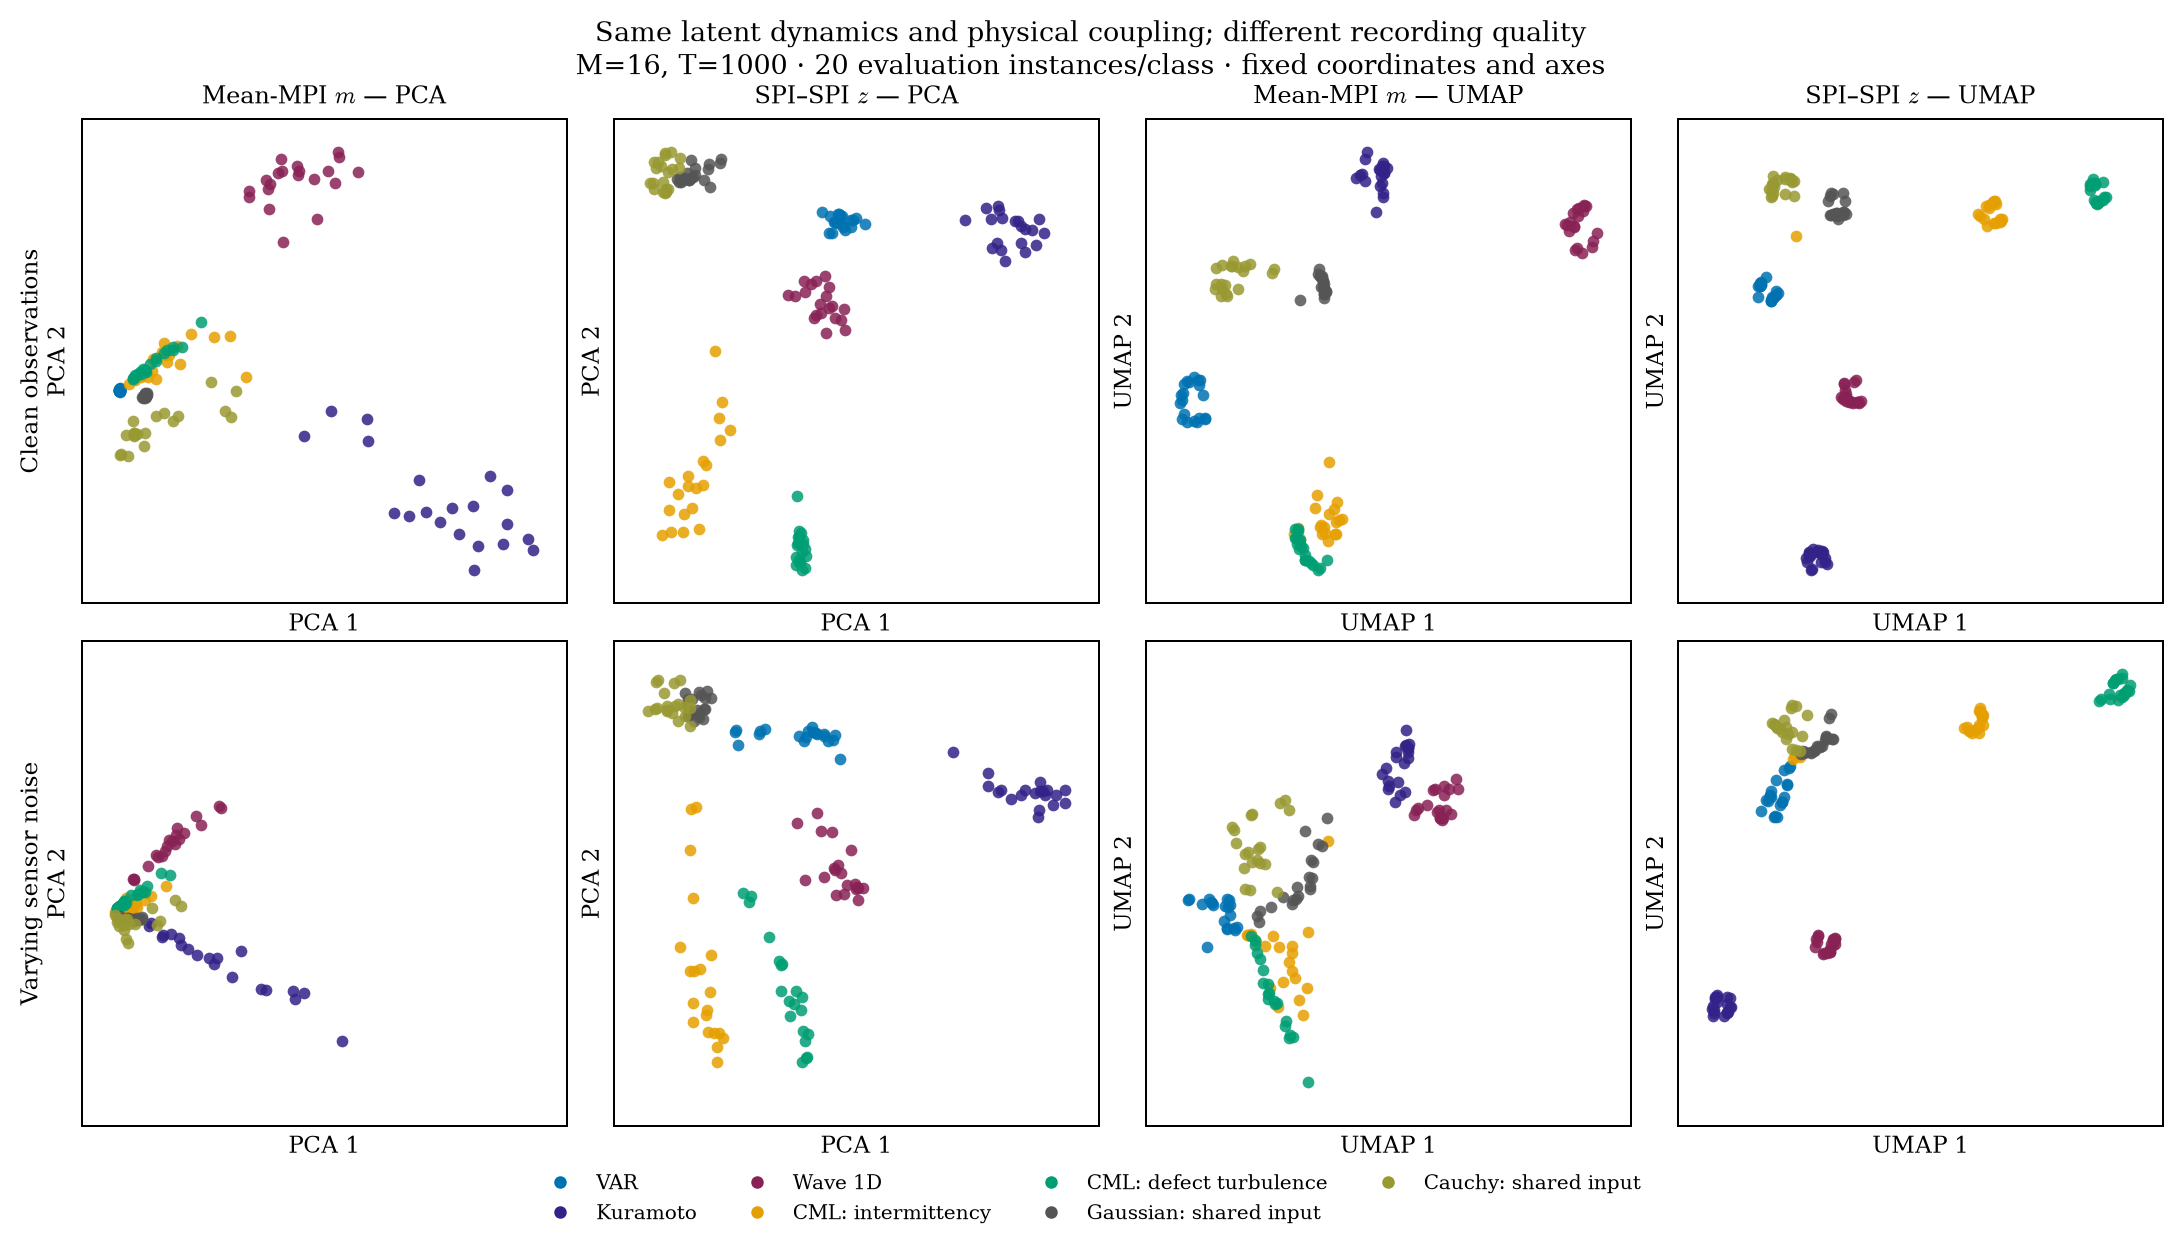

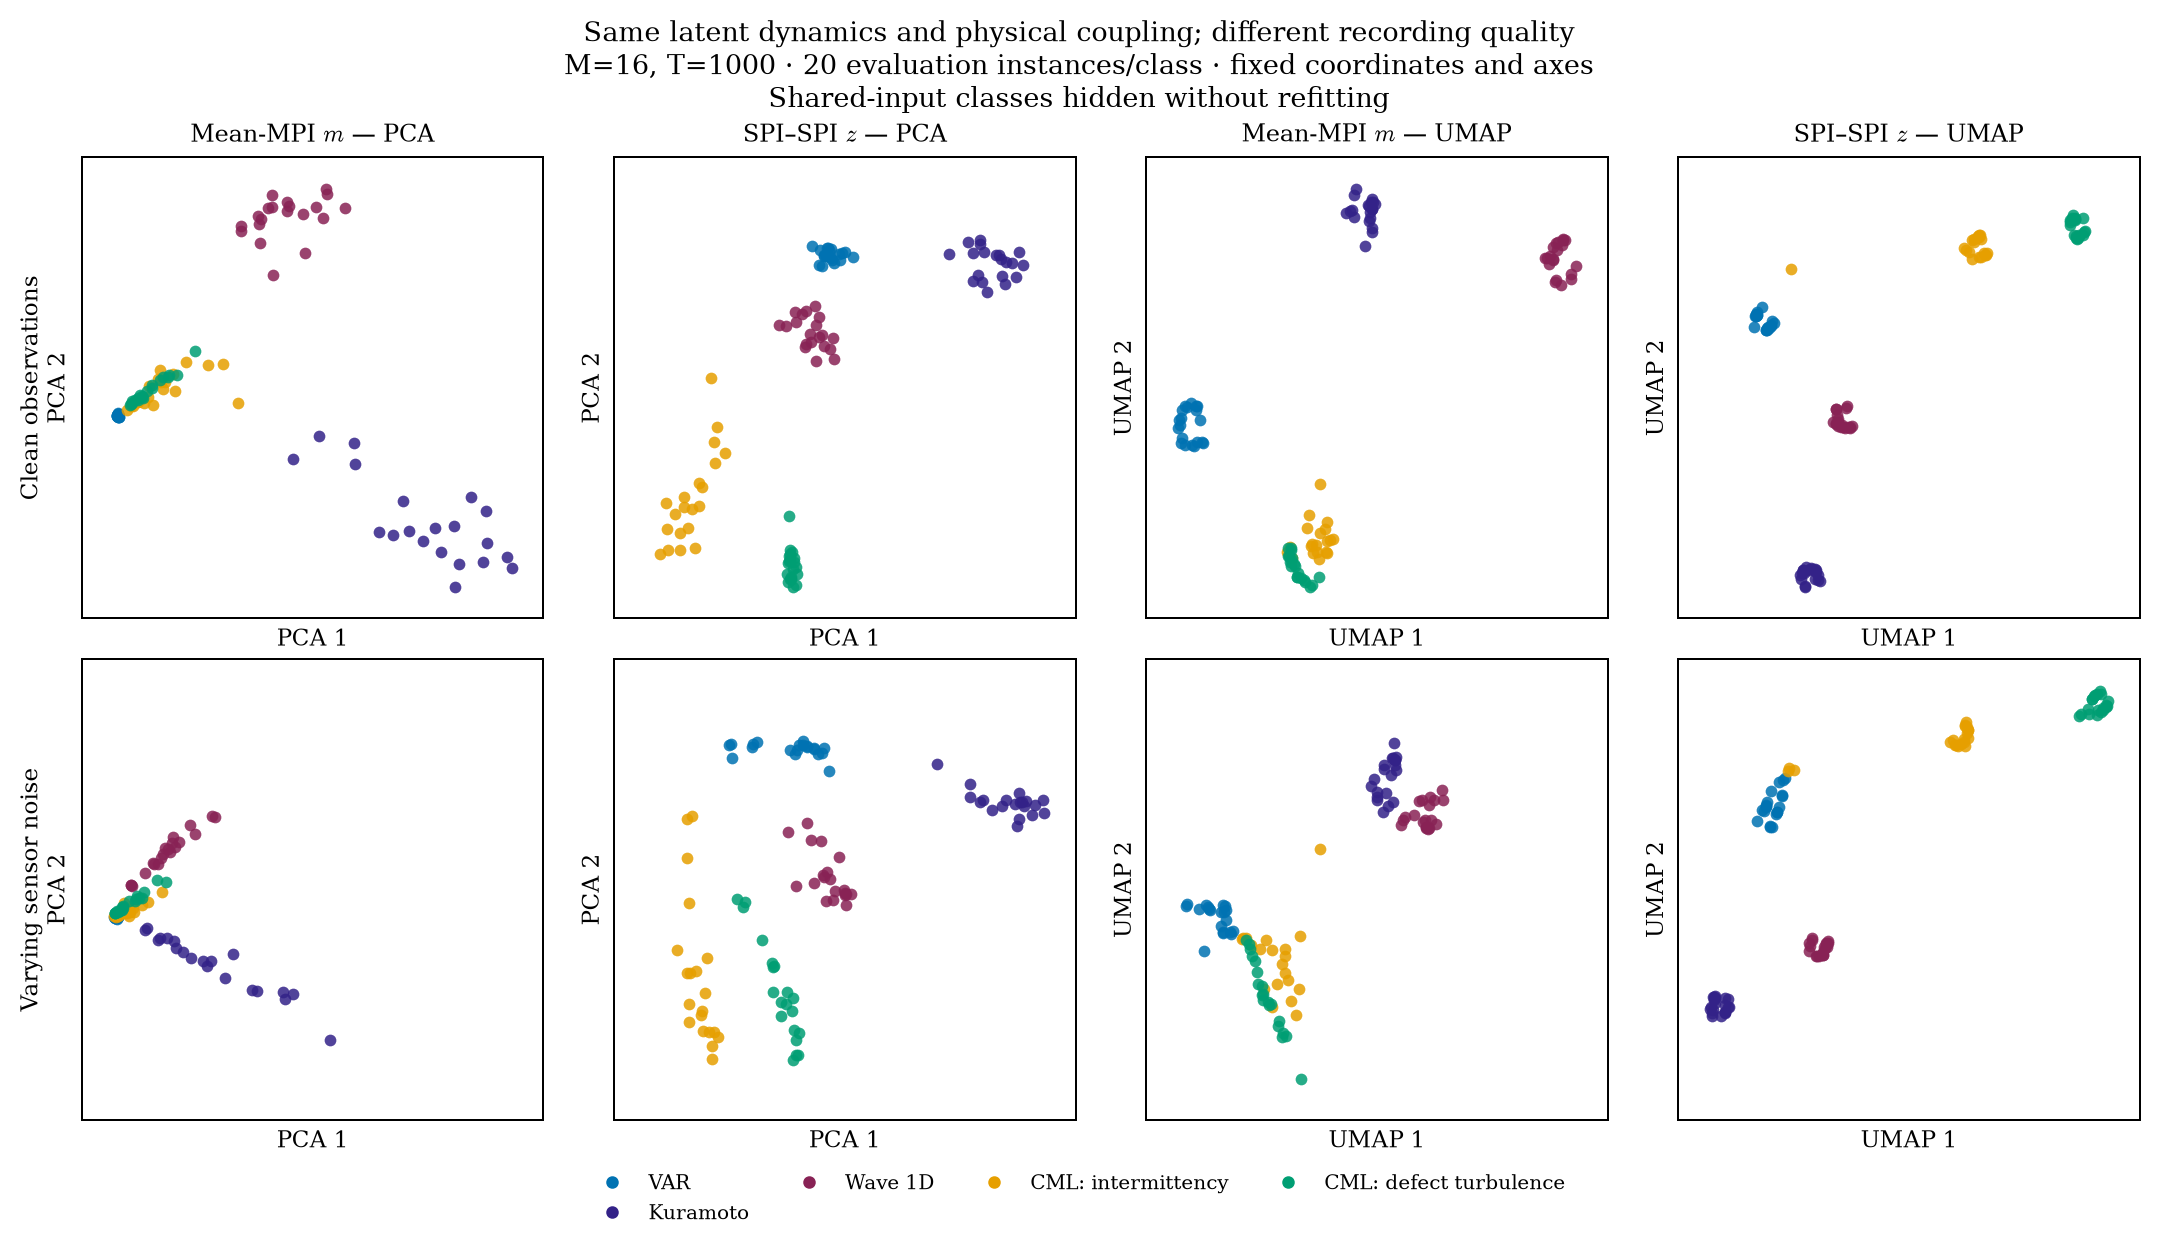

In [1]:
from pathlib import Path
from IPython.display import display,Image
NOISE_ROOT=Path.cwd().resolve()
while not (NOISE_ROOT/'pyproject.toml').exists() and NOISE_ROOT!=NOISE_ROOT.parent:NOISE_ROOT=NOISE_ROOT.parent
NOISE_FIG=NOISE_ROOT/'results/proof/strength-factorial-261015/figures'
display(Image(filename=str(NOISE_FIG/'noise-focus-all.png')))
display(Image(filename=str(NOISE_FIG/'noise-focus-dynamics.png')))

### The same views coloured by observed mean $|r|$

Only point colour changes; the all-class/five-dynamical-class selections, coordinates and axis limits match the preceding figures. Both rows share the viridis scale [0,1]. Noise samples already follow independent $N(0,1)$ draws across channels/time; the uniform draw is the recording-level nominal attenuation $\alpha_d\sim U[.25,.95]$, converted to a shared channel noise SD $\eta_d=\sqrt{1/\alpha_d-1}$. Unequal sensor noise SDs and exponential noise samples have not been tested here.

The combined intervention gives a stronger **relative compactness** contrast than noise alone: spread/separation rises from .288/.184 (m/z) to 1.130/.380, factors 3.92/2.07. Noise-only factors are 1.67/1.16. Conversely, the **retrieval** advantage is larger under noise alone (mAP difference .387) than both (.260). These are different properties of the same geometry; neither negates the other. Noise-only remains the cleaner intervention for holding latent dynamics fixed.

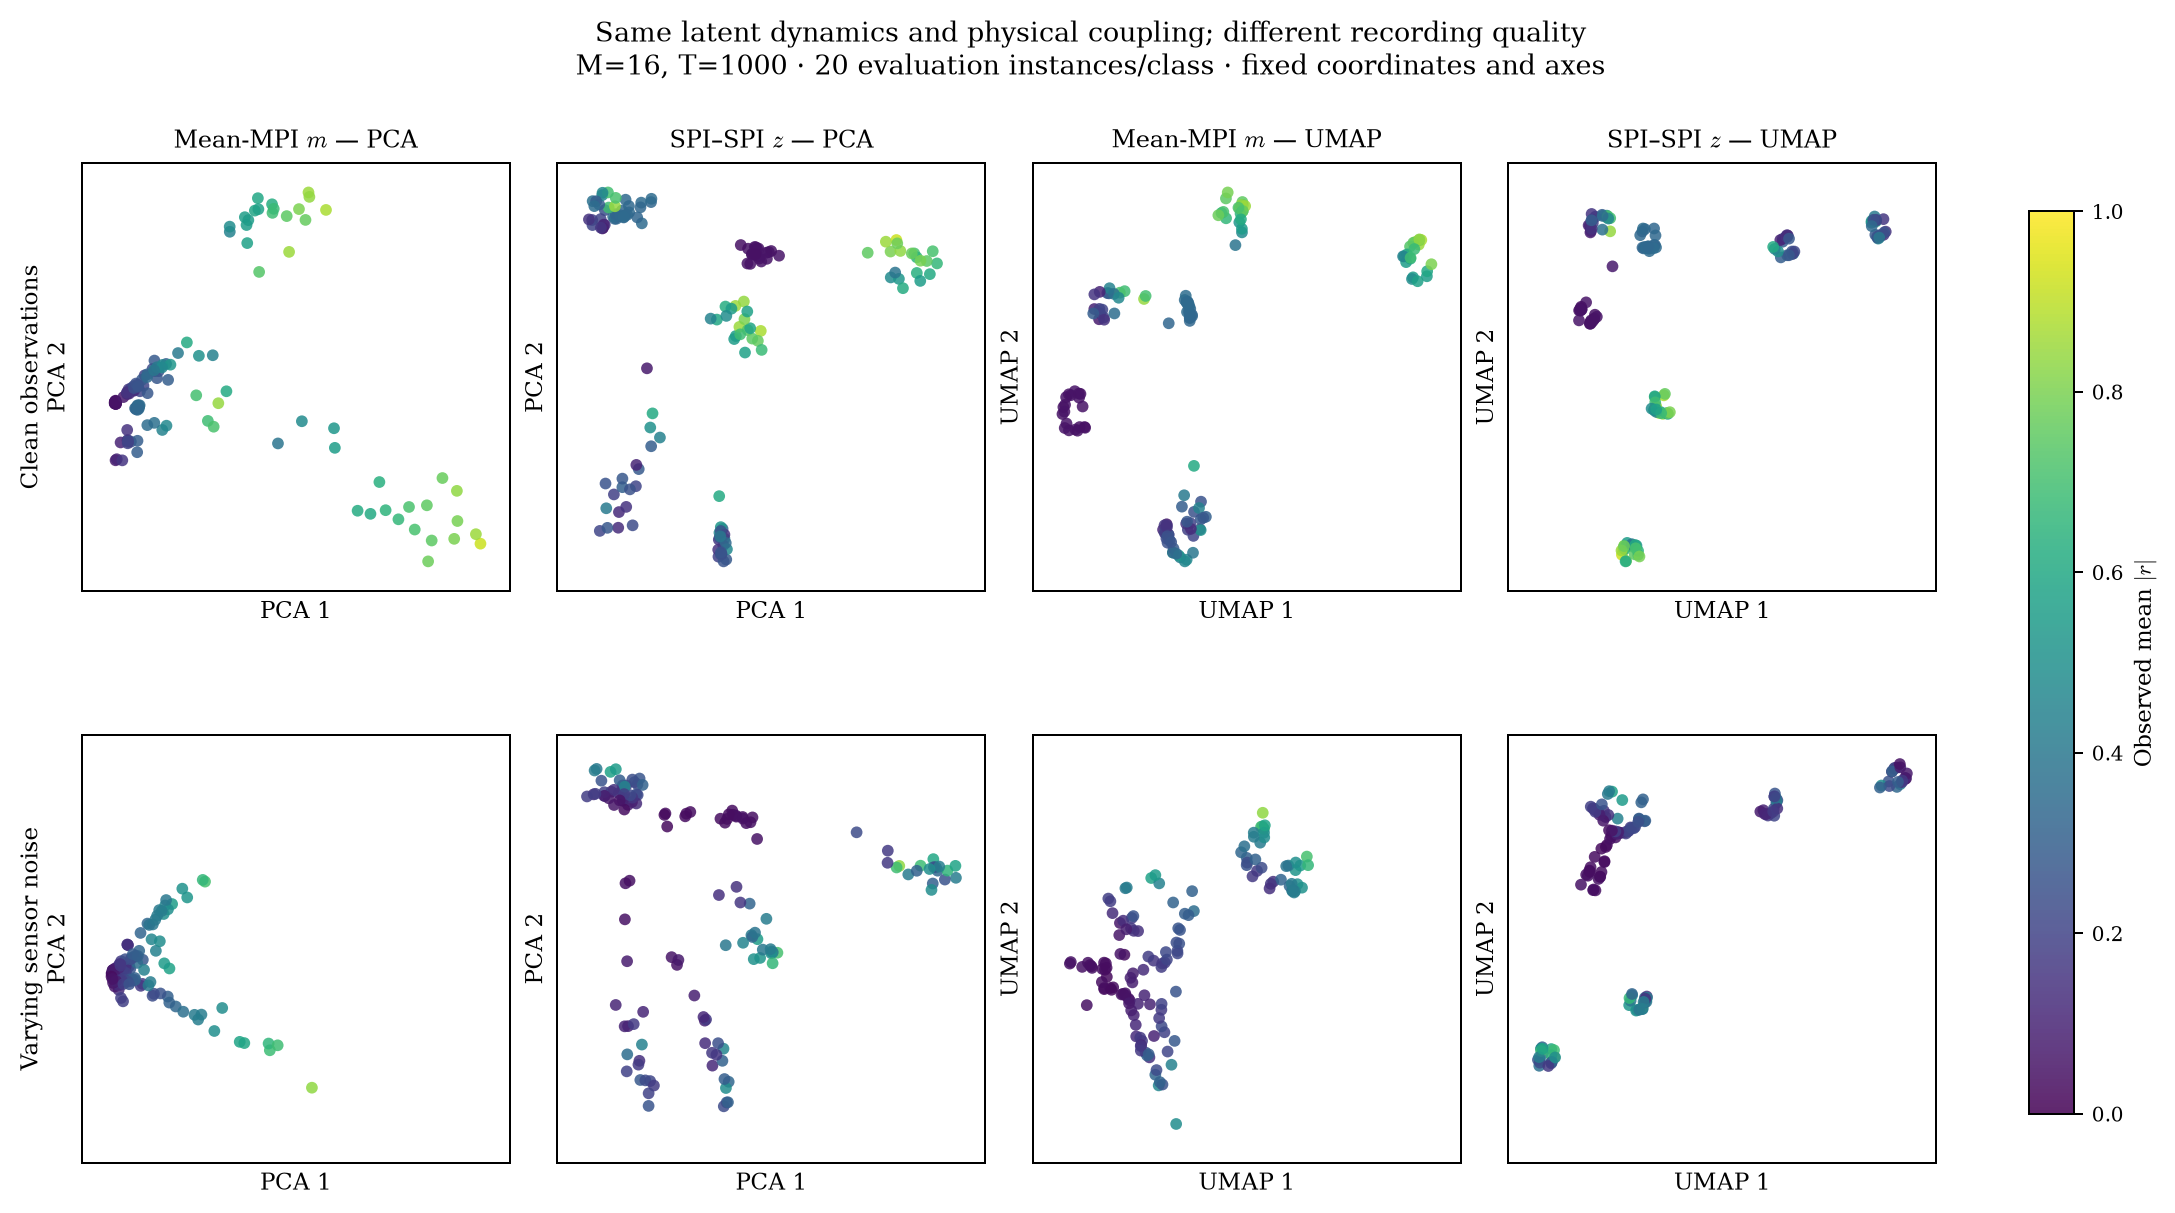

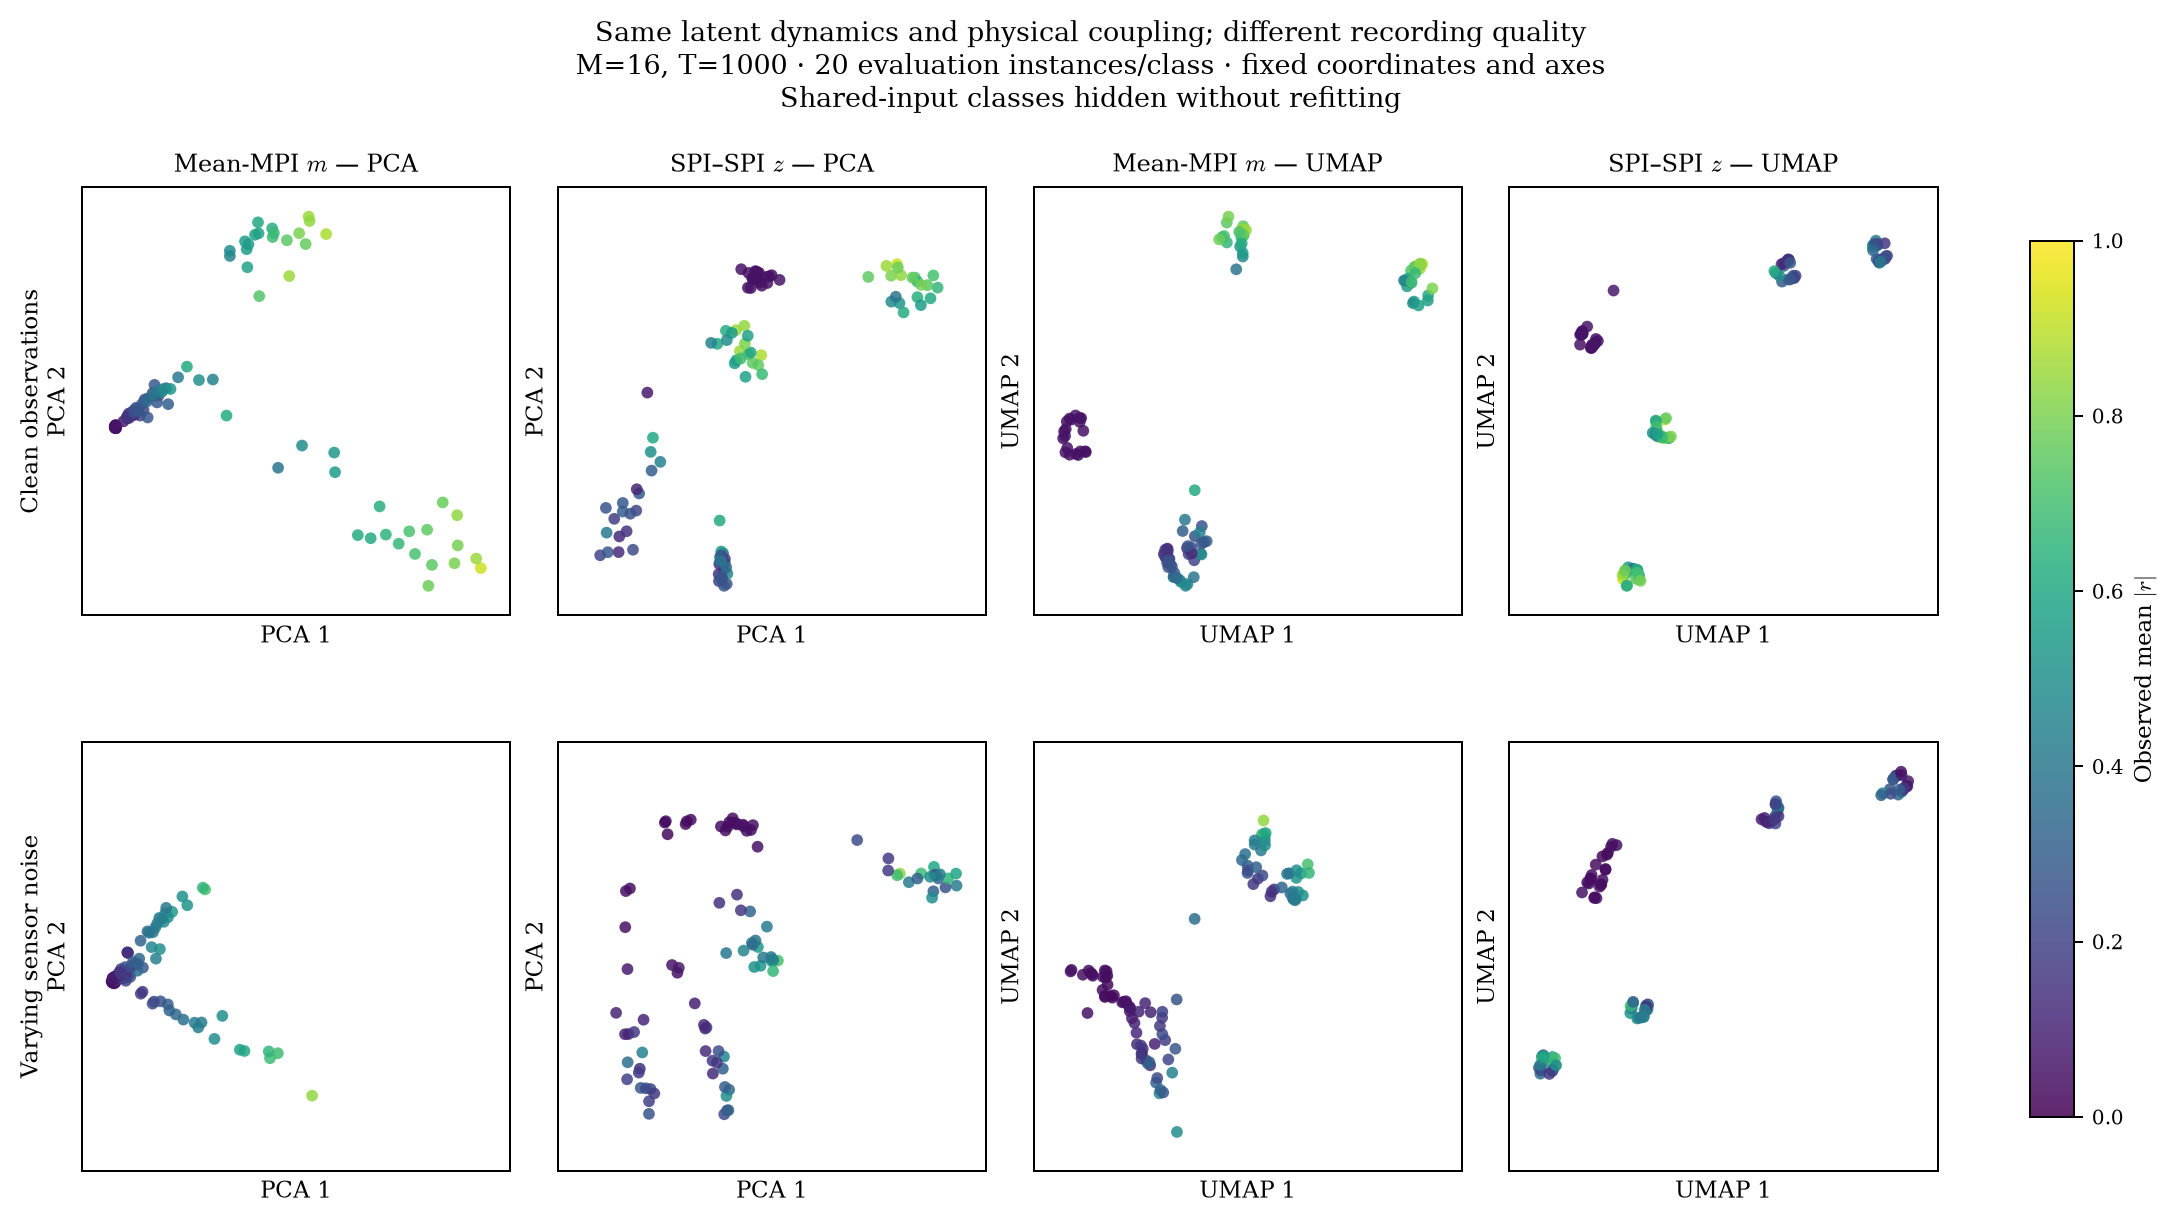

In [1]:
from pathlib import Path
from IPython.display import display,Image
NS_ROOT=Path.cwd().resolve()
while not (NS_ROOT/'pyproject.toml').exists() and NS_ROOT!=NS_ROOT.parent:NS_ROOT=NS_ROOT.parent
NS_FIG=NS_ROOT/'results/proof/strength-factorial-261015/figures'
display(Image(filename=str(NS_FIG/'noise-focus-all-strength.png')))
display(Image(filename=str(NS_FIG/'noise-focus-dynamics-strength.png')))

## Paired noise-dose and stronger random-noise experiments — 16 October

Fresh M=16/T=1000 recordings, 32 realizations/class, seven classes including CML intermittency/frozen chaos. Physical coupling is fixed. Each parent supplies identical latent data and independent Gaussian error samples to all its conditions. The 2,688-record dose bank tests $\eta=0,.5,1,2,4,8$, equal versus exponential relative channel SDs, plus the error array alone as a pure-noise limit. The 448-record random bank compares matched-quantile attenuations $U[.25,.95]$ and $U[.05,.50]$. No failed seed, class or severe dose is removed.

For the unequal-SD condition, $w_i\sim\mathrm{Exp}(1)$ and $\eta_i=\eta w_i/\sqrt{M^{-1}\sum_j w_j^2}$. The mean channel noise variance is exactly $\eta^2$ before observation standardization; realized noise energy is audited separately. Equal power is **not equal average attenuation**: uneven allocation leaves some sensors cleaner. At eta8, theoretical mean pair attenuation averages .015 for equal noise versus .129 for these exponential profiles (finite-variance model, not a Cauchy population identity).

Instances 0–15 at clean/equal-eta1/exponential-eta1 fit all transforms and readouts; instances 16–31 evaluate every condition. Clean-gallery retrieval uses different parents. Primary means retain training feature scaling/clipping but no per-recording normalization. Full/unclipped means, standardized/complete-training z and validity-only prediction remain controls. A secondary direction-normalized mean vector subtracts the training pure-noise centroid and normalizes length; it is not the primary baseline. Common PCA50/UMAP coordinates and limits are fixed across conditions. The main montage shows prospectively selected clean/eta2/eta8/limit; all doses appear in the curves and full-profile figure files. Intervals resample instance blocks, retaining classes/conditions, conditional on training.

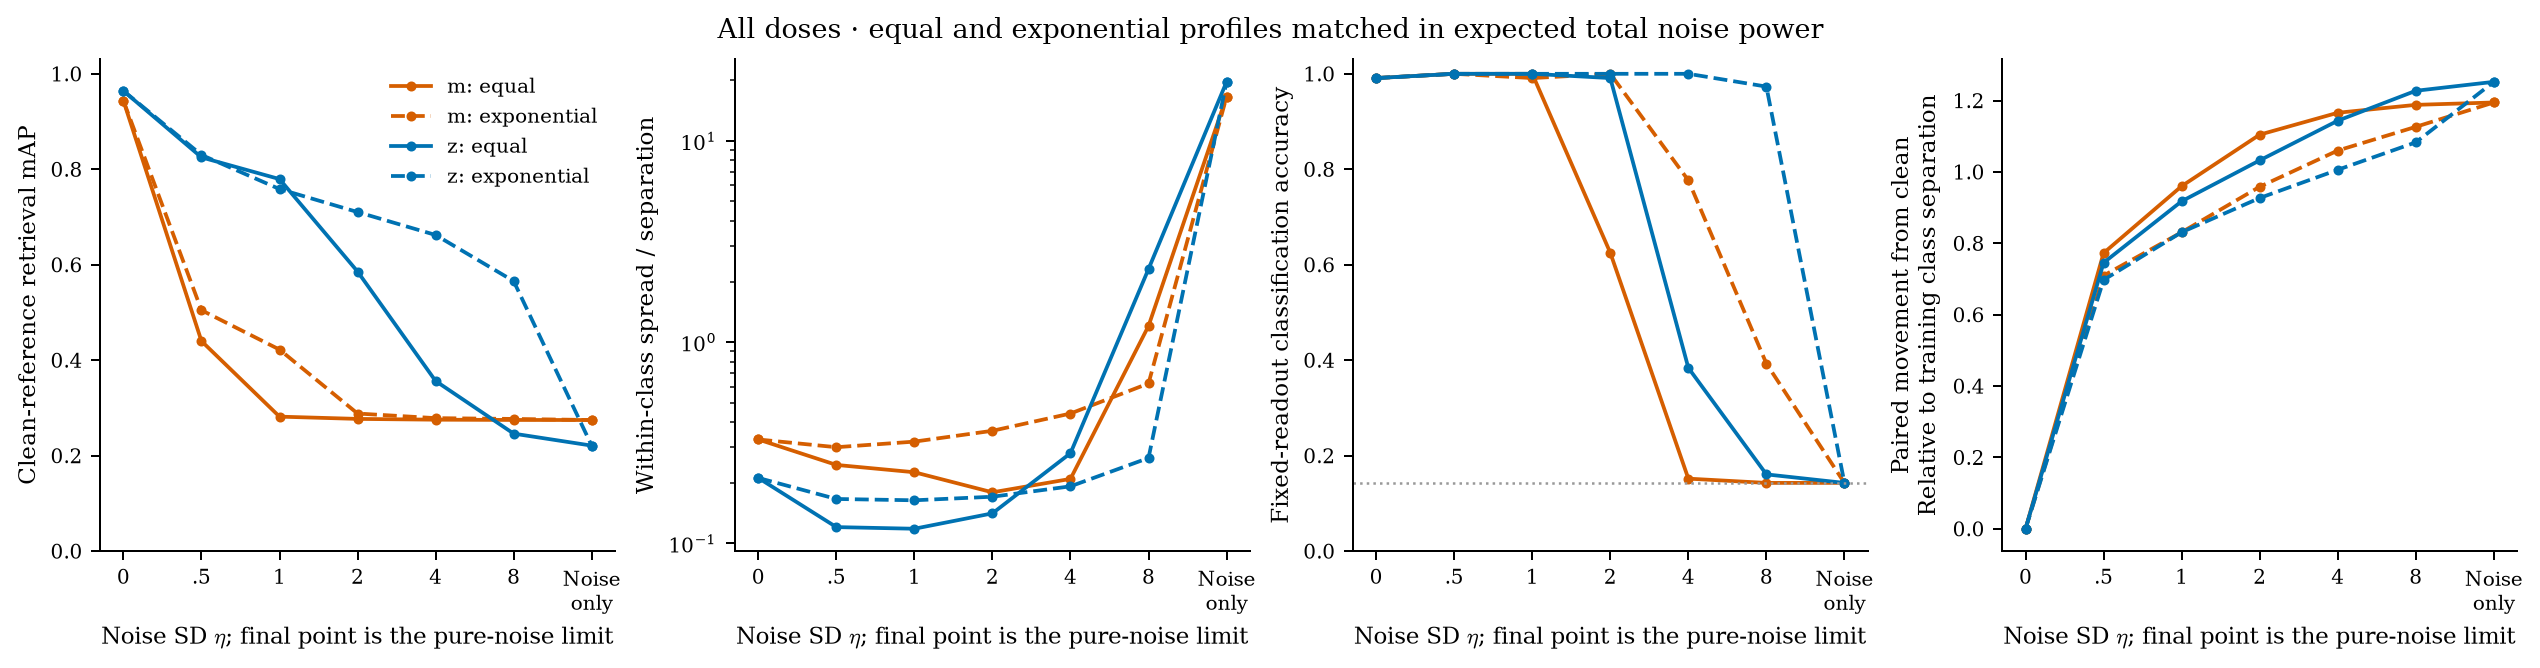

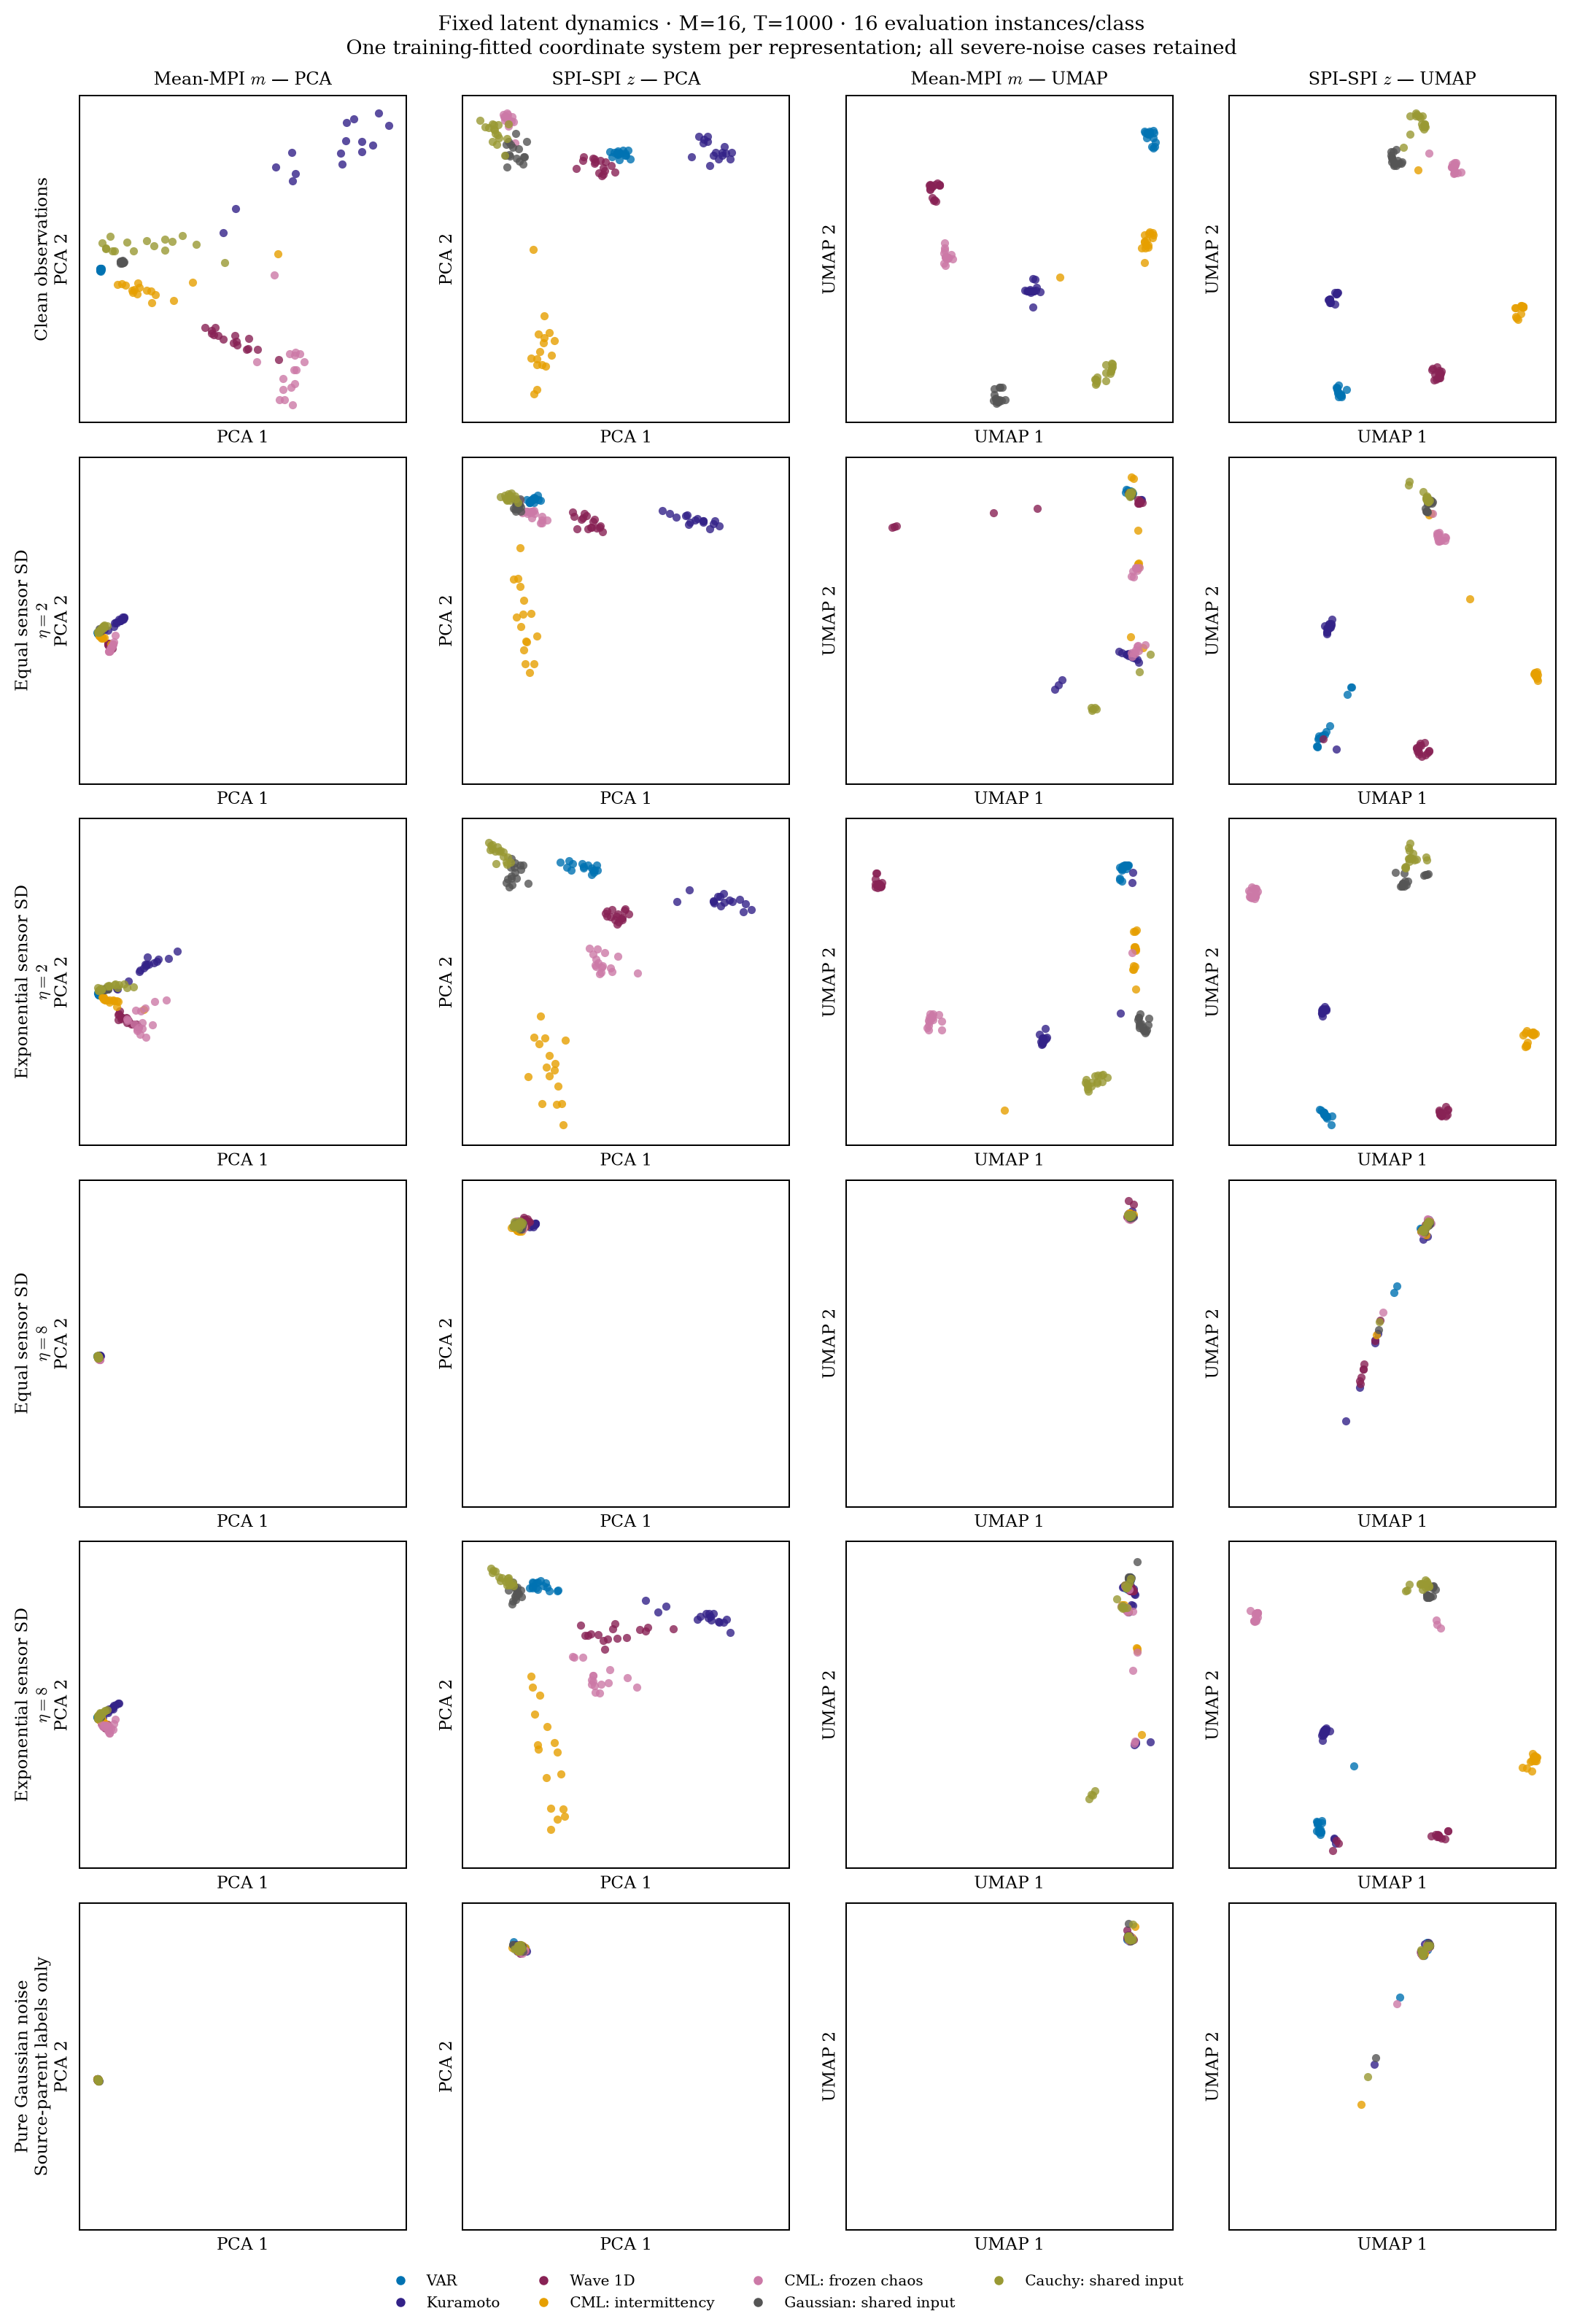

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
NE_ROOT=Path.cwd().resolve()
while not (NE_ROOT/'pyproject.toml').exists() and NE_ROOT!=NE_ROOT.parent:NE_ROOT=NE_ROOT.parent
NE_OUT=NE_ROOT/'results/proof/noise-experiments-261016'
display(Image(filename=str(NE_OUT/'figures/dose-curves.png')))
display(Image(filename=str(NE_OUT/'figures/dose-main-class.png')))

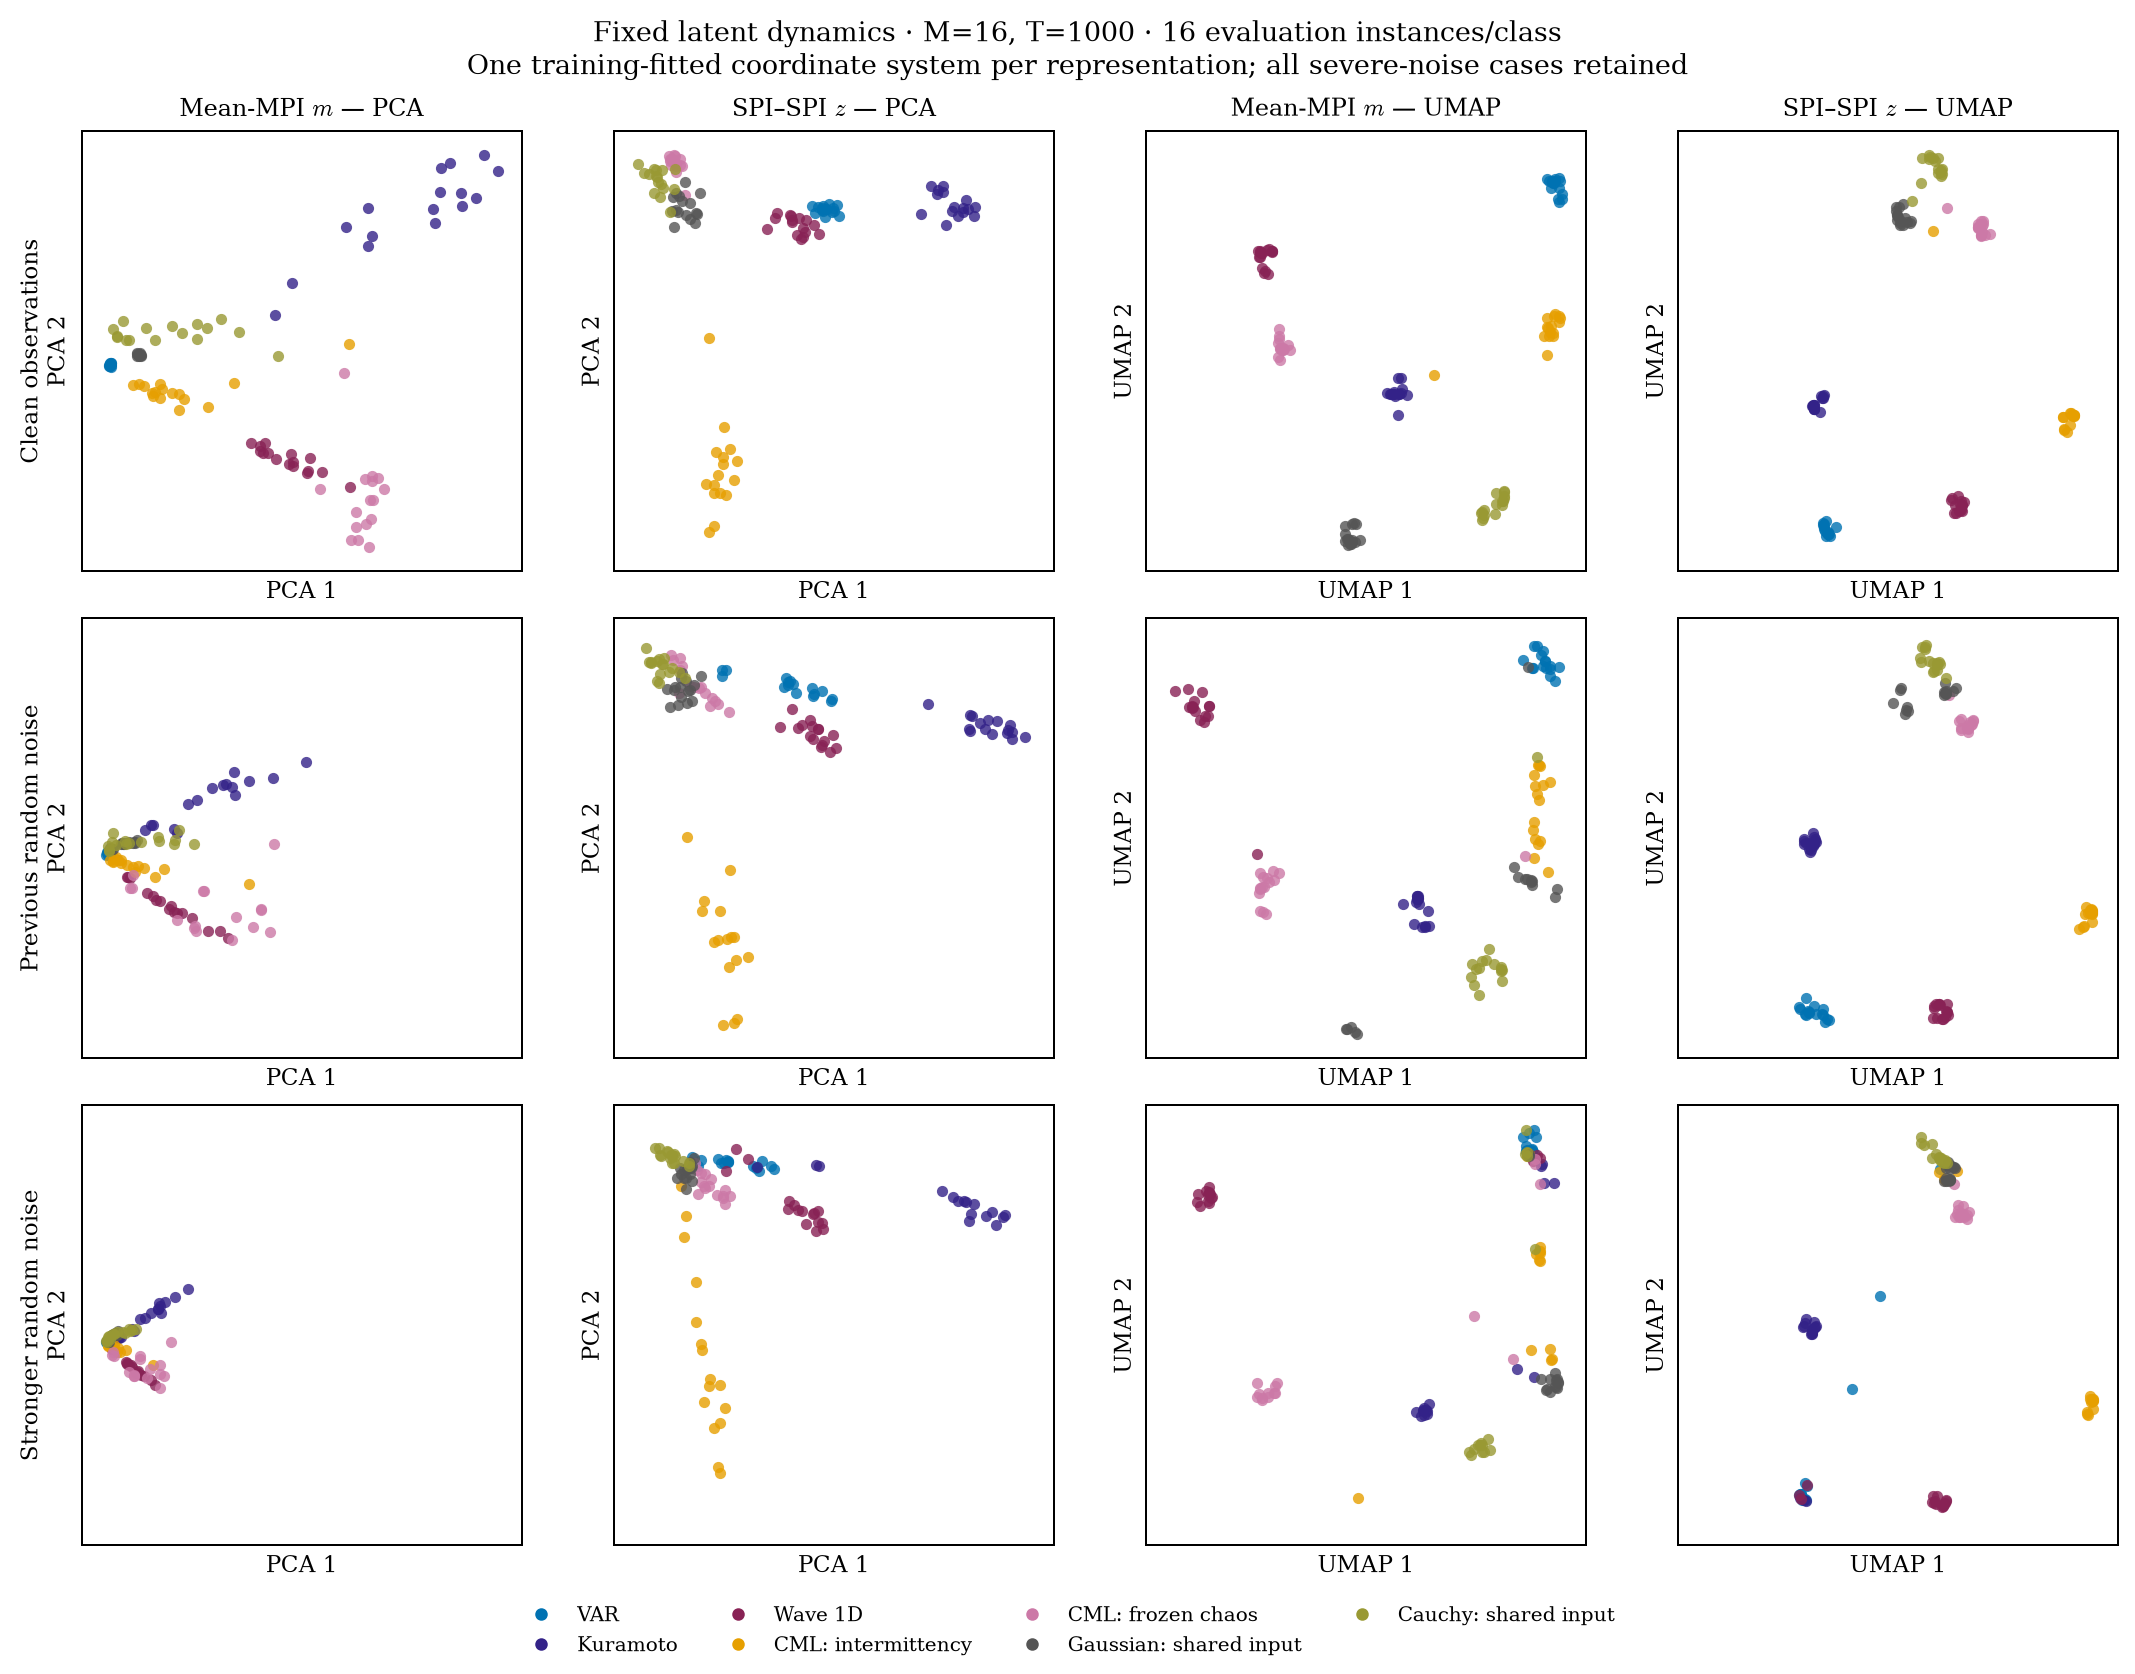

mAP        spread_to_separation         accuracy       
representation        m      z                    m       z        m      z
arm                                                                        
clean             0.944  0.964                0.328   0.211    0.991  0.991
equal-eta8        0.275  0.246                1.203   2.307    0.143  0.161
exponential-eta8  0.277  0.566                0.623   0.265    0.393  0.973
noise-limit       0.275  0.221               16.581  19.648    0.143  0.143
random-previous   0.411  0.810                0.607   0.201    0.991  1.000
random-stronger   0.278  0.669                0.523   0.287    0.821  0.911

In [2]:
display(Image(filename=str(NE_OUT/'figures/random-class.png')))
ne_scores=pd.read_csv(NE_OUT/'metrics.csv')
display(ne_scores.query("representation in ['m','z'] and arm in ['clean','equal-eta8','exponential-eta8','noise-limit','random-previous','random-stronger']").pivot(index='arm',columns='representation',values=['mAP','spread_to_separation','accuracy']).round(3))

**Stronger noise preserves a raw-mean retrieval contrast, but does not improve it monotonically.** For previous → stronger random noise, m/z clean-reference mAP changes .411/.810 → .278/.669; the stronger-arm difference is .391 [95% paired interval .319,.455]. Spread/separation changes .607/.201 → .523/.287: increasing noise actually narrows this geometry advantage. Means contract towards the noise reference rather than becoming literally more spread out. The PCA plots show this contraction; UMAP retains some mean clusters and mixes others. Both use fixed training coordinates, so collapse is not evidence that all residual information is absent. Full-mean linear accuracy remains .821 (z .911).

**Noise allocation matters, and severe failures remain.** At equal eta2, m/z retrieval is .277/.586; at eta8 it is .275/.246 and accuracy .143/.161: both fixed readouts fail. Equal-eta8 spread/separation is also worse for z (2.307 versus 1.203). Exponential eta8 instead gives .277/.566 retrieval and .393/.973 accuracy, with spread/separation .623/.265; its cleaner channels preserve usable signal despite identical expected total noise power. This is not a comparison at matched observed dependence. The pure-noise endpoint has no source-family signal by construction; both primary classifiers score 1/7. Its raw AP differs (.275/.221) because gallery rankings have different class structure: the exact randomized-query-label AP expectation is reported as `mAP_label_null`, and excess over it is approximately zero for both. Small UMAP islands at this endpoint are projection artifacts, not recovered families.

**A simple normalized-mean control remains competitive.** Subtracting the training noise centroid and normalizing mean-vector length gives stronger-random mAP .665 (z .669), exponential-eta8 .777 (z .566), and equal-eta8 .373 with accuracy .580 (z .161). Thus raw means lose useful distance geometry before their information disappears, and the advantage is not unique to SPI–SPI. The main baseline remains raw m. Unclipped/full means give the same retrieval conclusion; standardized z is weaker (stronger-random .452), whereas complete-training z improves to .740. Validity alone classifies .295 under stronger random noise; complete-training z still has .138% missing held entries there, so estimator validity is not wholly eliminated as a confound. Kuramoto remains difficult for clean-reference z retrieval (.166); benefits are not uniform across families.

All 3,136 records completed with unchanged p90/r9 provenance. Independent checks of 28,322 means and 9,800 z values agree within $3\times10^{-8}$. These experiments support robustness of the specified representation/readout to observation noise, not identified causal/nonlinear character or intrinsic marginal-information absence. All-dose figures and mean-$|r|$ colour analogues are saved under `results/proof/noise-experiments-261016/figures/`; no held-result choice of seeds, doses, classes or embedding settings was made.

In [3]:
ne_arms=['equal-eta8','exponential-eta8','noise-limit','random-stronger']
display(ne_scores.query('arm in @ne_arms').pivot(index='representation',columns='arm',values=['mAP','mAP_excess','accuracy']).round(3))
display(pd.read_csv(NE_OUT/'paired-intervals.csv').query('arm in @ne_arms').round(3))
print('Validity-only accuracy:',json.loads((NE_OUT/'analysis-audit.json').read_text())['validity_only_accuracy'])

mAP                                               \
arm              equal-eta8 exponential-eta8 noise-limit random-stronger   
representation                                                             
m                     0.275            0.277       0.275           0.278   
m_direction           0.373            0.777       0.254           0.666   
m_full                0.275            0.277       0.275           0.278   
m_unclipped           0.275            0.277       0.274           0.278   
m_unclipped_full      0.275            0.277       0.274           0.278   
mean_abs_r            0.252            0.257       0.252           0.270   
z                     0.246            0.566       0.221           0.669   
z_complete            0.260            0.601       0.247           0.740   
z_standard            0.250            0.446       0.240           0.452   

                 mAP_excess                                               \
arm              equal-eta8 exponential-eta8 noise-limit random-stronger   
representation                                                             
m                     0.000            0.002       0.000           0.004   
m_direction           0.126            0.517       0.014           0.408   
m_full                0.000            0.002      -0.000           0.004   
m_unclipped           0.000            0.003      -0.000           0.004   
m_unclipped_full      0.000            0.003      -0.000           0.004   
mean_abs_r           -0.000            0.013      -0.000           0.032   
z                     0.024            0.311      -0.000           0.415   
z_complete            0.017            0.348       0.003           0.482   
z_standard            0.009            0.191       0.001           0.204   

                   accuracy                                               
arm              equal-eta8 exponential-eta8 noise-limit random-stronger  
representation                                                            
m                     0.143            0.393       0.143           0.821  
m_direction           0.580            0.964       0.116           0.991  
m_full                0.143            0.366       0.143           0.821  
m_unclipped           0.143            0.393       0.143           0.821  
m_unclipped_full      0.143            0.366       0.143           0.821  
mean_abs_r            0.143            0.152       0.143           0.223  
z                     0.161            0.973       0.143           0.911  
z_complete            0.161            0.973       0.143           0.911  
z_standard            0.214            0.955       0.161           0.920

,arm,metric,estimate,low,high
9,equal-eta8,z_minus_m_mAP,-0.029,-0.036,-0.021
10,exponential-eta8,z_minus_m_mAP,0.289,0.259,0.318
11,noise-limit,z_minus_m_mAP,-0.054,-0.059,-0.049
13,random-stronger,z_minus_m_mAP,0.391,0.319,0.455
23,equal-eta8,z_minus_m_change_in_spread_ratio,1.221,0.485,1.684
24,exponential-eta8,z_minus_m_change_in_spread_ratio,-0.241,-0.456,-0.029
25,noise-limit,z_minus_m_change_in_spread_ratio,3.184,-4.010,5.908
27,random-stronger,z_minus_m_change_in_spread_ratio,-0.119,-0.266,-0.011


Validity-only accuracy: {'clean': 0.875, 'equal-eta0.5': 0.4642857142857143, 'exponential-eta0.5': 0.7589285714285714, 'equal-eta1': 0.4017857142857143, 'exponential-eta1': 0.6964285714285714, 'equal-eta2': 0.21428571428571427, 'exponential-eta2': 0.625, 'equal-eta4': 0.16071428571428573, 'exponential-eta4': 0.5446428571428571, 'equal-eta8': 0.17857142857142858, 'exponential-eta8': 0.39285714285714285, 'noise-limit': 0.16964285714285715, 'random-previous': 0.4642857142857143, 'random-stronger': 0.29464285714285715}


### Composite: varying sensor noise, fixed latent dynamics

These PCA/UMAP composites reuse the **fixed_sensor** arm of the October 15 factorial, not the later stronger-noise experiment: all seven classes, M=16, T=1000, 20 evaluation recordings/class. This includes nominal CML intermittency and **defect turbulence**. Starting from sample-standardized latent channels, add independent Gaussian samples with one common SD per recording, $\eta_d=\sqrt{1/\alpha_d-1}$, where $\alpha_d\sim U[.25,.95]$ (thus $\eta\approx .23$–$1.73$). Noise strength varies between recordings, with the same draw across classes at a given instance; physical coupling stays fixed. Channels are standardized again before p90. For finite-variance population channels this gives nominal correlation attenuation $\alpha_d$; the identity does not apply to Cauchy population moments.

Columns compare z and raw mean-MPI (training feature scaling/clipping, no within-recording normalization). The second row changes only colour to observed mean absolute Pearson correlation. Coordinates and limits are reused without fitting; PCA variance percentages refer to training data, and neither PC is defined to be a strength axis. Here mean-MPI PC1 strongly tracks observed mean absolute correlation (pooled Spearman $\rho=.962$, within-class $.904$–$.995$), versus $.350$ pooled for z PC1. The colour gradients describe association, not a uniquely identified physical coordinate; z still has within-class strength associations. Mean-MPI retains class information despite less robust clean-reference distances.

The lower row shows three illustrative SPI–SPI coordinates: within CML, Gaussian versus Cauchy shared input, and VAR versus Wave. Candidate families are rank/distance versus KSG mutual information, Pearson versus rank correlation, and lagged Pearson versus spectral coherence/phase locking, respectively. Maximal oriented AUC within each family selects a coordinate using noisy **training instances 0–19 only** (catalogue order breaks ties; preceding selections are excluded to obtain three distinct features); rainclouds show instances 20–39, with boxes denoting median/IQR and 1.5-IQR whiskers. Undefined values are omitted and counts are reported below. Candidate coordinates can tie at training AUC 1; these are illustrative examples, not uniquely best probes. Class contrasts were chosen for illustration, so this remains a retrospective presentation, not a new confirmation or mechanistic identification. Each feature panel has its own vertical scale.

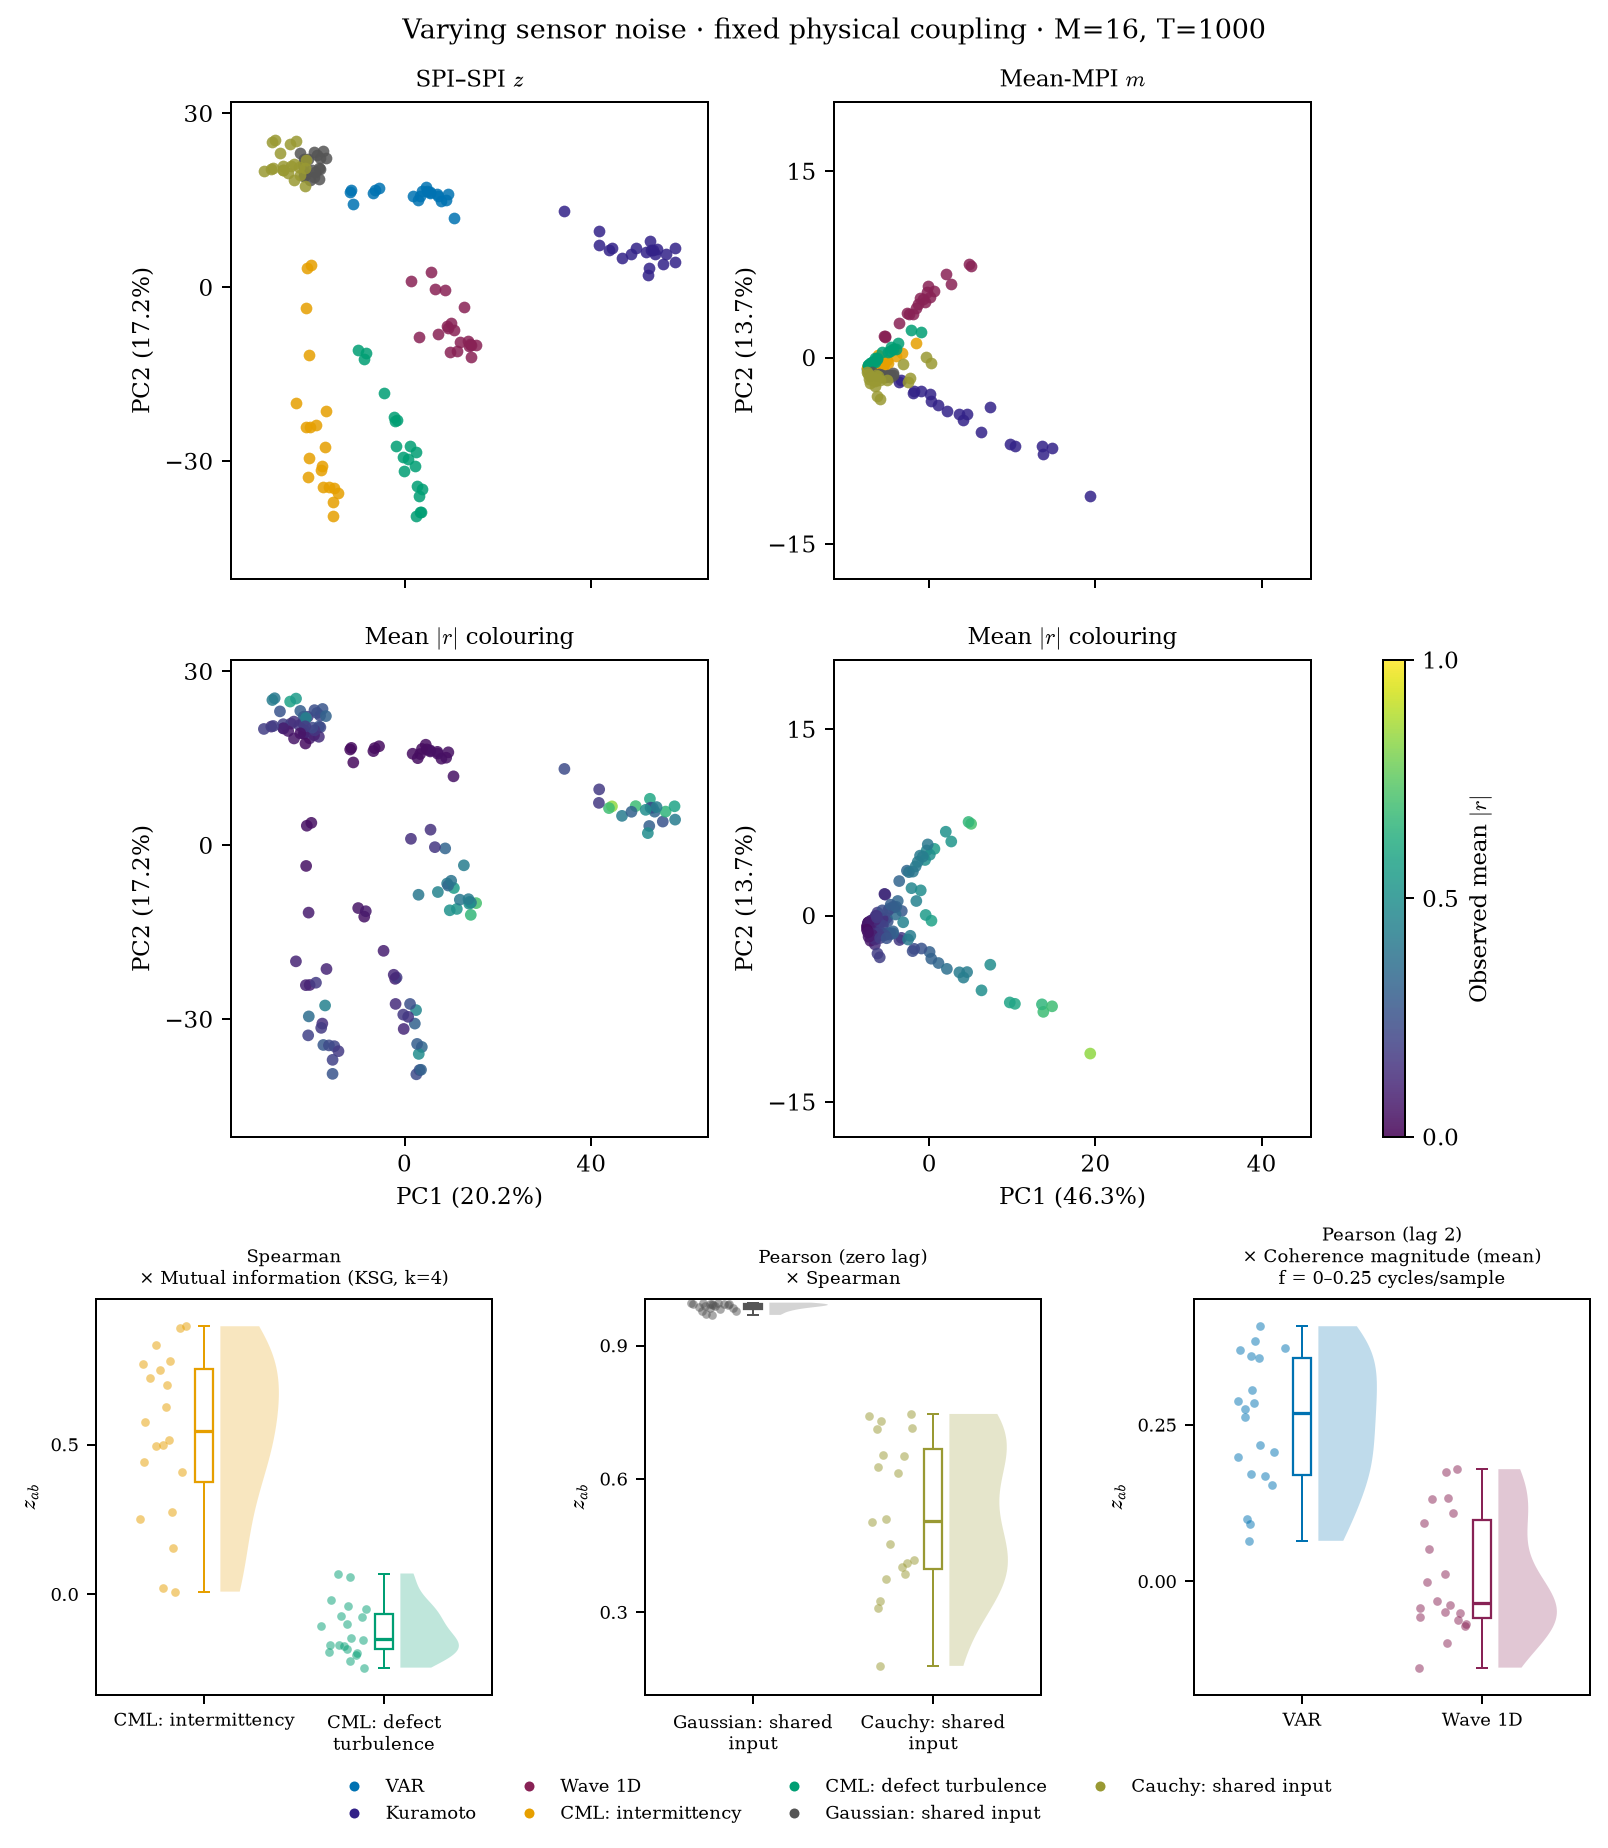

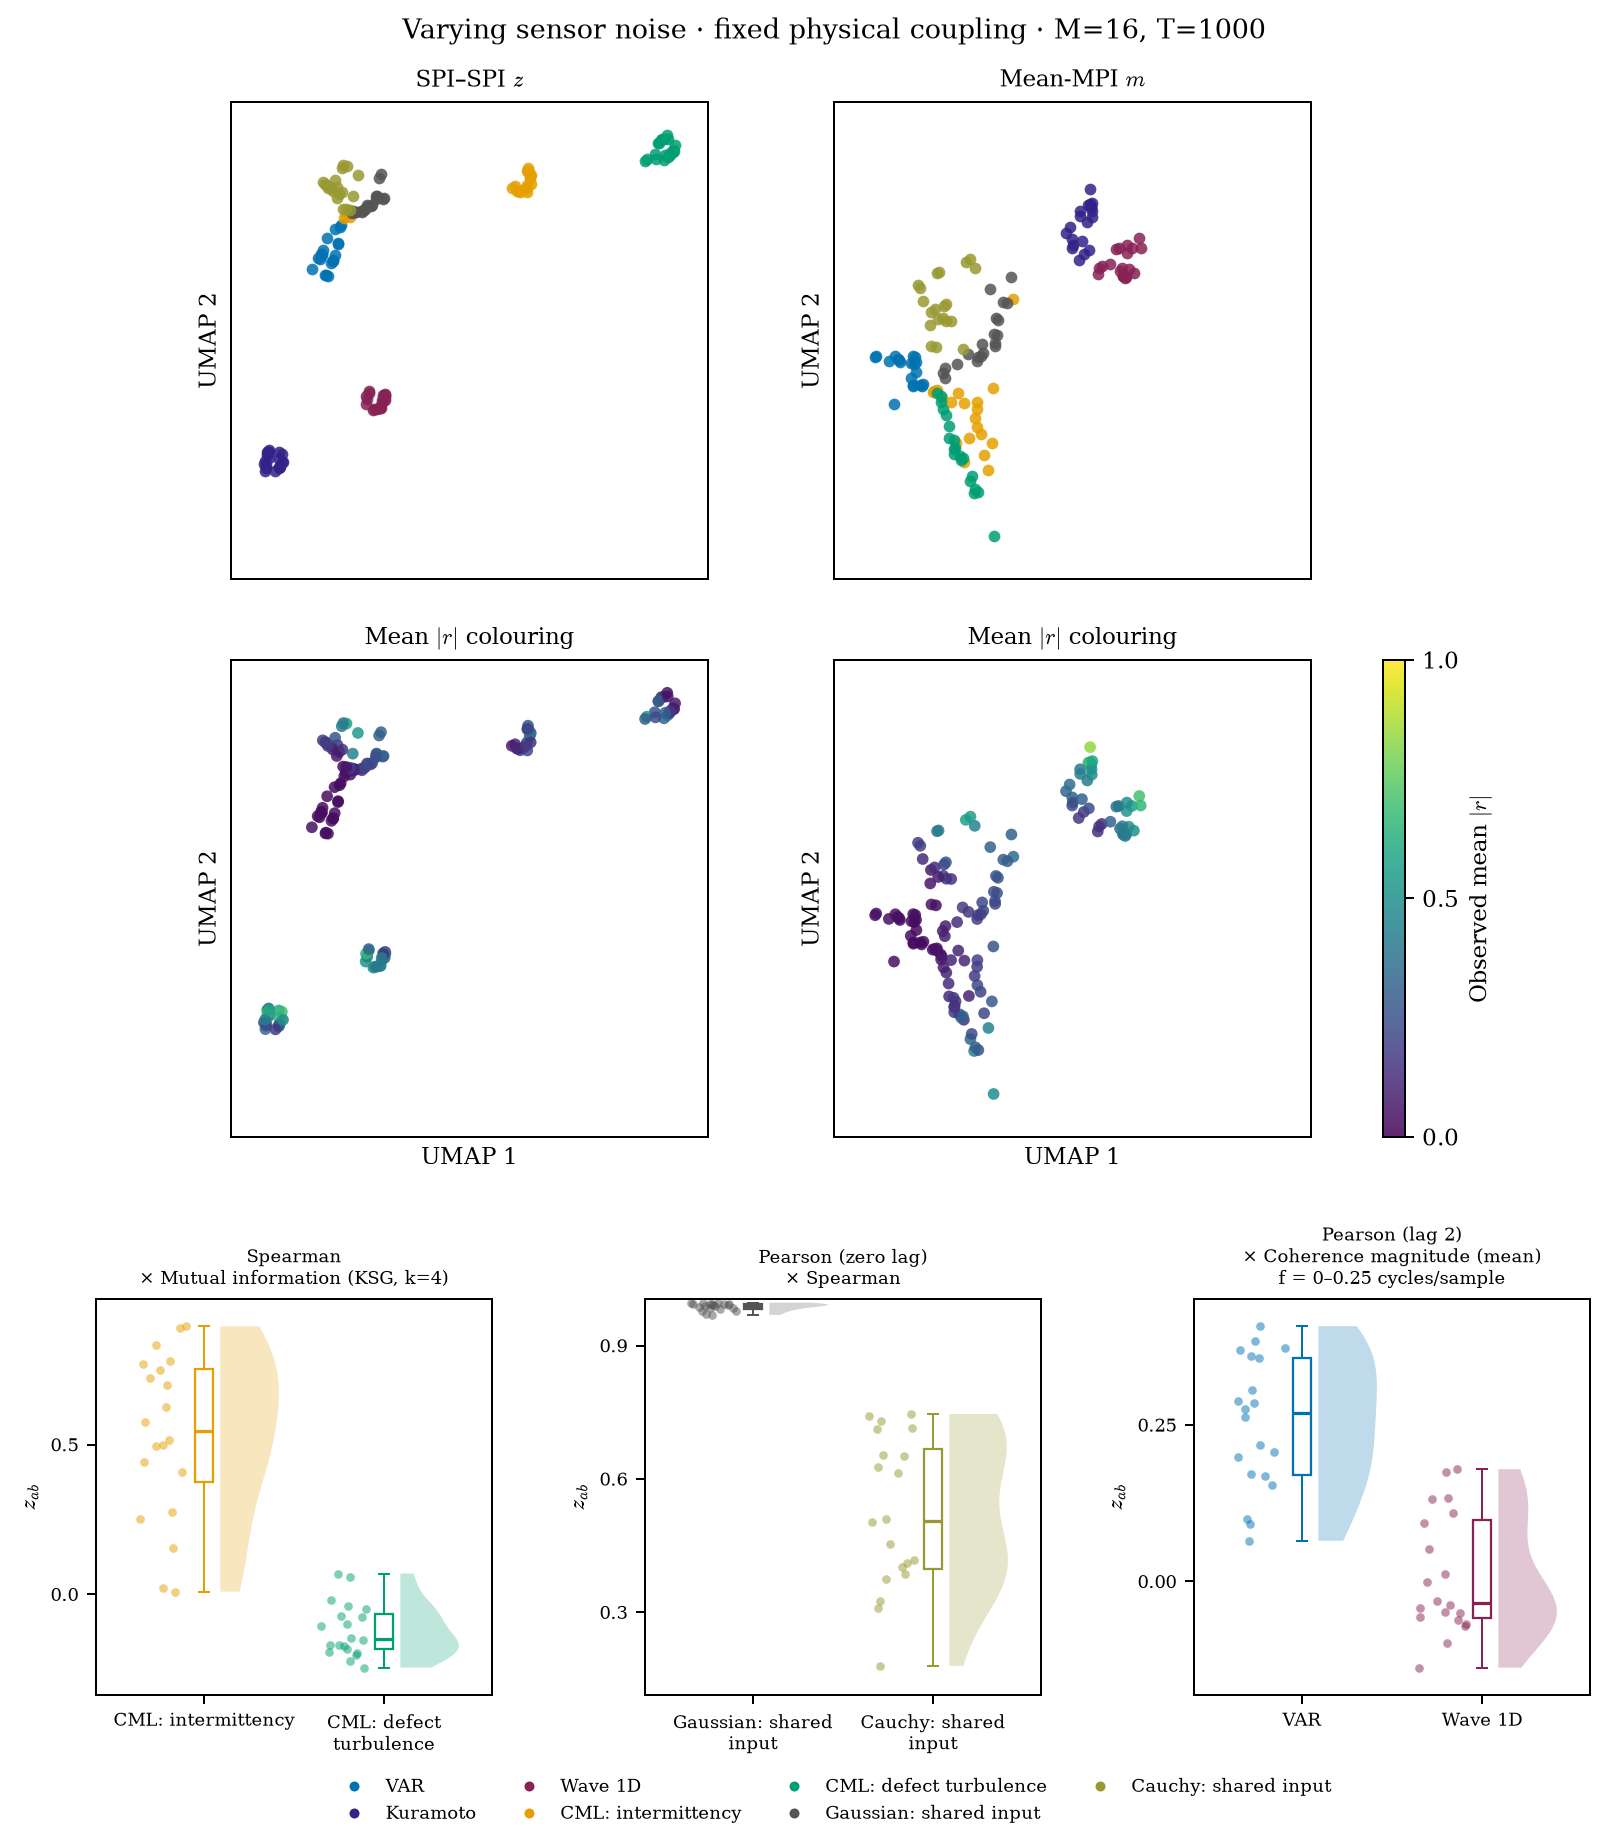

,class_a,class_b,spi_a,spi_b,training_auc,display_auc,display_n_a,display_n_b
0,CML-intermittency,CML-defect,spearmanr,mi_kraskov_NN-4,1.00,0.990,20.0,20.0
1,Gaussian-shared,Cauchy-shared,cov_EmpiricalCovariance,spearmanr,1.00,1.000,20.0,20.0
2,VAR,Wave,corr_pearson_tau-2,cohmag_multitaper_mean_fs-1_fmin-0_fmax-0-25,0.97,0.942,20.0,20.0


In [1]:
from pathlib import Path
from IPython.display import display,Image
import pandas as pd
NC_ROOT=Path.cwd().resolve()
while not (NC_ROOT/'pyproject.toml').exists() and NC_ROOT!=NC_ROOT.parent:NC_ROOT=NC_ROOT.parent
NC_OUT=NC_ROOT/'results/proof/strength-factorial-261015'
display(Image(filename=str(NC_OUT/'figures/noise-composite-pca.png')))
display(Image(filename=str(NC_OUT/'figures/noise-composite-umap.png')))
display(pd.read_csv(NC_OUT/'noise-composite-selection.csv')[['class_a','class_b','spi_a','spi_b','training_auc','display_auc','display_n_a','display_n_b']].round(3))